# 🏀 籃球影片自動切片系統：出手 / 非出手二元分類訓練 Notebook

本 Notebook 是正式訓練版，目標是訓練一個能判斷籃球影片片段是否包含「出手事件」的二元分類模型。  
目前任務定義如下：

- `label = 1`：Shot / 出手片段
- `label = 0`：Non-Shot / 非出手片段

模型採用 Hugging Face Transformers 的 **VideoMAE**，資料集從 Kaggle 下載，並以 `labels.csv` 中的標籤進行訓練、驗證、儲存與載入。

> 研究目的：這是「籃球影片自動切片系統」的第一階段雛形。模型先學會偵測出手事件，未來可延伸為長影片滑動視窗掃描、事件定位、自動產生 highlight clips。

## 0. 安裝套件

Colab 通常已內建 PyTorch 與部分常用套件。以下只安裝本專案必要但 Colab 不一定有的套件。


In [ ]:
# 若在 Google Colab 執行，請先安裝必要套件。
# - kagglehub：用於下載 Kaggle Dataset
# - decord：用於高效率讀取影片影格
# - transformers：VideoMAE 模型來源
# - scikit-learn：資料切分與評估指標
!apt-get update
!apt-get install -y fonts-comic-neue

!pip install -q kaggle kagglehub decord transformers scikit-learn tqdm
!pip install -U transformers==5.9.0

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [354 B]
Get:5 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Hit:6 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:7 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:9 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Hit:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Get:11 http://security.ubuntu.com/ubuntu jammy-security/main amd64 Packages [3,959 kB]
Get:12 http://security.ubuntu.com/ubuntu jammy-security/restricted amd64 Packages [7,090 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [10.3

# 模型訓練部分

## 1. 使用前說明

建議執行環境：Google Colab + GPU。  
請依序執行本 Notebook，不要跳著執行，因為後面的訓練、評估與儲存會依賴前面建立的變數。

本版已整理：

1. 移除重複與草稿測試區。
2. 將可調整參數集中到「設定區」。
3. 補齊 Kaggle 金鑰設定教學與安全讀取方式。
4. 補齊 Dataset、DataLoader、訓練迴圈、Early Stopping、儲存與載入的註解。
5. 讓其他同學只要設定 Kaggle Secrets 與參數，就能順利重跑。

### 關於目前結果的提醒
從你目前的曲線看，驗證準確率約落在 90% 以上，最高點接近 95%。不過第 5 個 epoch 後，訓練 loss 繼續下降、validation loss 開始上升，validation accuracy 也開始回落，這代表**可能已經出現早期過擬合訊號**。因此本 Notebook 保留 Early Stopping，並會自動保存驗證表現最好的權重。


## 2. 集中設定區

之後如果要測試不同模型、batch size、epoch、learning rate，主要修改這一格即可。  
建議每次實驗只改少數參數，並記錄結果，才方便比較模型表現。


In [ ]:
import warnings

# # Temporarily uninstall and reinstall transformers to resolve potential dependency conflicts with torch
# # This ensures that a compatible version of transformers is used with the current PyTorch installation.
# # This is added here to directly address the error in this cell's execution context.
# !pip uninstall -y transformers
# !pip install transformers

from pathlib import Path
import os
import json
import random
import shutil

import numpy as np
import pandas as pd
import torch
import decord
from decord import VideoReader, cpu
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from transformers import VideoMAEImageProcessor, VideoMAEForVideoClassification

# =========================================================
# A. 專案與資料集設定
# =========================================================
PROJECT_NAME = "basketball-shot-segmentation"
KAGGLE_DATASET = "donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full"
LABEL_FILENAME = "labels.csv"

# 若你不使用 Kaggle，而是手動上傳資料集，可把 USE_KAGGLE_DOWNLOAD 改成 False，
# 再把 LOCAL_DATASET_PATH 改成資料集所在資料夾。
USE_KAGGLE_DOWNLOAD = True
LOCAL_DATASET_PATH = "/content/Dataset"

# =========================================================
# B. 模型與訓練設定
# =========================================================
MODEL_NAME = "MCG-NJU/videomae-base-finetuned-kinetics"
NUM_LABELS = 2
CLASS_NAMES = ["Non-Shot (0)", "Shot (1)"]

RANDOM_SEED = 42
TEST_SIZE = 0.2
MAX_FRAMES = 16          # 每支影片抽取幾個影格。VideoMAE 常用 16 frames。
BATCH_SIZE = 96          # 若 GPU 記憶體不足，先改成 32、16 或 8。
NUM_WORKERS = 8          # Colab 可先用 2；高階機器可提高到 4 或 8。
PREFETCH_FACTOR = 4      # num_workers > 0 時才會使用。

EPOCHS = 15
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
PATIENCE = 4             # 驗證表現連續幾輪沒進步就停止。

# 是否啟用混合精度。GPU 訓練建議 True；CPU 執行會自動關閉。
USE_AMP = True
# A100/H100 推薦
AMP_DTYPE = torch.bfloat16
# 舊 GPU 可改：
# AMP_DTYPE = torch.float16

# torch.compile 有時會讓第一次訓練變慢，也可能影響模型儲存。
# 若使用 A100/H100 且熟悉 PyTorch 2.x，可改成 True 測試速度。
USE_TORCH_COMPILE = True

# =========================================================
# C. 儲存設定
# =========================================================
OUTPUT_DIR = Path("./outputs")
BEST_MODEL_DIR = OUTPUT_DIR / "best_basketball_videomae_model"
FINAL_MODEL_DIR = OUTPUT_DIR / "final_basketball_videomae_model"

# Google Drive Backup
DRIVE_BACKUP_DIR = "/content/drive/MyDrive/Basketball_Project/Model_VideoMAE_H100_V3"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)
FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# =========================================================
# D. 固定隨機種子：讓切分與訓練比較可重現
# =========================================================
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用裝置：{device}")
if torch.cuda.is_available():
    print(f"GPU：{torch.cuda.get_device_name(0)}")

## 3. Kaggle API 金鑰設定

### 建議作法：使用 Colab Secrets

請先到 Kaggle 下載 API Token：

1. 登入 Kaggle。
2. 點選右上角頭像 → `Settings`。
3. 找到 `API` → 點選 `Create New Token`。
4. 下載後會得到 `kaggle.json`，內容大致如下：

```json
{"username":"你的Kaggle帳號","key":"你的Kaggle API Key"}
```

接著在 Colab 左側點選鑰匙圖示 `Secrets`，新增以下其中一種設定：

### 方式 A：分開存，最推薦

- `KAGGLE_USERNAME`：填入 username
- `KAGGLE_KEY`：填入 key

### 方式 B：整包 JSON 存入一個 Secret

- `KAGGLE_JSON`：貼上整份 `kaggle.json` 內容

請不要把自己的 Kaggle key 直接寫在 Notebook 裡，也不要把 key 上傳到 GitHub。


In [ ]:
def setup_kaggle_credentials():
    """安全設定 Kaggle API 憑證。

    支援三種來源：
    1. Colab Secrets: KAGGLE_USERNAME + KAGGLE_KEY
    2. Colab Secrets: KAGGLE_JSON
    3. 本機或 Colab 已存在的 ~/.kaggle/kaggle.json
    """
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_json_path = kaggle_dir / "kaggle.json"
    kaggle_dir.mkdir(parents=True, exist_ok=True)

    username = None
    key = None

    # 在 Colab 內可用 google.colab.userdata；在本機執行時會自動跳過。
    try:
        from google.colab import userdata
        username = userdata.get("KAGGLE_USERNAME")
        key = userdata.get("KAGGLE_KEY")
        kaggle_json_secret = userdata.get("KAGGLE_JSON")
    except Exception:
        kaggle_json_secret = None

    if username and key:
        kaggle_json_path.write_text(json.dumps({"username": username, "key": key}), encoding="utf-8")
        os.chmod(kaggle_json_path, 0o600)
        print("已從 Colab Secrets 的 KAGGLE_USERNAME / KAGGLE_KEY 建立 Kaggle 憑證。")
        return

    if kaggle_json_secret:
        # 檢查是否為合法 JSON，避免貼錯內容。
        parsed = json.loads(kaggle_json_secret)
        if "username" not in parsed or "key" not in parsed:
            raise ValueError("KAGGLE_JSON 必須包含 username 與 key。")
        kaggle_json_path.write_text(json.dumps(parsed), encoding="utf-8")
        os.chmod(kaggle_json_path, 0o600)
        print("已從 Colab Secrets 的 KAGGLE_JSON 建立 Kaggle 憑證。")
        return

    if kaggle_json_path.exists():
        os.chmod(kaggle_json_path, 0o600)
        print(f"偵測到既有 Kaggle 憑證：{kaggle_json_path}")
        return

    raise FileNotFoundError(
        "找不到 Kaggle API 憑證。請先在 Colab Secrets 設定 KAGGLE_USERNAME/KAGGLE_KEY 或 KAGGLE_JSON。"
    )

if USE_KAGGLE_DOWNLOAD:
    setup_kaggle_credentials()

已從 Colab Secrets 的 KAGGLE_USERNAME / KAGGLE_KEY 建立 Kaggle 憑證。


## 4. 下載資料集並讀取標籤

此區塊會下載 Kaggle Dataset，接著自動尋找 `labels.csv`。  
程式會依照 `relative_path` 或 `file_name` 欄位建立影片完整路徑，並跳過不存在的影片檔案。

In [ ]:
if USE_KAGGLE_DOWNLOAD:
    import kagglehub
    dataset_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
else:
    dataset_path = Path(LOCAL_DATASET_PATH)

if not dataset_path.exists():
    raise FileNotFoundError(f"資料集路徑不存在：{dataset_path}")

print(f"資料集路徑：{dataset_path}")

# 顯示資料集前幾層結構，方便同學確認檔案位置。
print("\n資料集檔案結構預覽：")
preview_count = 0
for root, dirs, files in os.walk(dataset_path):
    level = Path(root).relative_to(dataset_path).parts
    if len(level) > 2:
        continue
    indent = "  " * len(level)
    print(f"{indent}{Path(root).name}/")
    for file in files[:5]:
        print(f"{indent}  {file}")
        preview_count += 1
    if preview_count > 30:
        break

Using Colab cache for faster access to the '2026-nccu-1142dtai-ebc-full' dataset.
資料集路徑：/kaggle/input/2026-nccu-1142dtai-ebc-full

資料集檔案結構預覽：
2026-nccu-1142dtai-ebc-full/
  games.csv
  labels.csv
  non_shot/
    n_E03_053.mp4
    n_F02_066.mp4
    n_B03_079.mp4
    n_E01_018.mp4
    n_A02_016.mp4
  shot/
    B03_096.mp4
    C01_061.mp4
    A01_030.mp4
    B03_100.mp4
    C01_018.mp4


In [ ]:
def find_label_csv(root_path: Path, filename: str = "labels.csv") -> Path:
    """在資料集資料夾中尋找 labels.csv。"""
    direct_path = root_path / filename
    if direct_path.exists():
        return direct_path

    matches = list(root_path.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"在 {root_path} 中找不到 {filename}。")

    # 若找到多個，預設使用第一個，並印出提醒。
    if len(matches) > 1:
        print("找到多個 labels.csv，將使用第一個：")
        for m in matches:
            print(" -", m)
    return matches[0]

label_csv_path = find_label_csv(dataset_path, LABEL_FILENAME)
label_root_path = label_csv_path.parent
print(f"labels.csv：{label_csv_path}")
print(f"標籤所在資料夾：{label_root_path}")

df_labels = pd.read_csv(label_csv_path)
print(f"標籤筆數：{len(df_labels)}")
display(df_labels.head())

required_columns = {"label"}
missing_columns = required_columns - set(df_labels.columns)
if missing_columns:
    raise ValueError(f"labels.csv 缺少必要欄位：{missing_columns}")

if not df_labels["label"].isin([0, 1]).all():
    bad_values = sorted(df_labels.loc[~df_labels["label"].isin([0, 1]), "label"].unique())
    raise ValueError(f"label 欄位只能包含 0 或 1，目前發現：{bad_values}")

labels.csv：/kaggle/input/2026-nccu-1142dtai-ebc-full/labels.csv
標籤所在資料夾：/kaggle/input/2026-nccu-1142dtai-ebc-full
標籤筆數：3358


,game_id,file_name,relative_path,label,label_name,shot_result,shot_result_name,source,event_time_sec,clip_start_sec,clip_end_sec,youtube_url,title
0,E01,E01_001.mp4,Dataset/shot/E01_001.mp4,1,shot,1.0,made,manual_shot_time,290.0,286.0,292.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026
1,E01,E01_002.mp4,Dataset/shot/E01_002.mp4,1,shot,1.0,made,manual_shot_time,305.0,301.0,307.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026
2,E01,E01_003.mp4,Dataset/shot/E01_003.mp4,1,shot,0.0,missed,manual_shot_time,314.0,310.0,316.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026
3,E01,E01_004.mp4,Dataset/shot/E01_004.mp4,1,shot,0.0,missed,manual_shot_time,318.0,314.0,320.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026
4,E01,E01_005.mp4,Dataset/shot/E01_005.mp4,1,shot,1.0,made,manual_shot_time,335.0,331.0,337.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026


In [ ]:
def build_video_path(row: pd.Series, dataset_root: Path, label_root: Path) -> Path:
    """依照 labels.csv 欄位建立影片路徑。

    優先使用 relative_path；若沒有，則使用 file_name。
    若 relative_path 開頭包含 Dataset/，會自動移除一次，避免 Kaggle 解壓縮後多一層或少一層導致找不到檔案。
    """
    if "relative_path" in row and pd.notna(row["relative_path"]):
        rel = str(row["relative_path"]).strip()
        rel_without_dataset = rel.replace("Dataset/", "", 1) if rel.startswith("Dataset/") else rel

        candidates = [
            dataset_root / rel,
            dataset_root / rel_without_dataset,
            label_root / rel,
            label_root / rel_without_dataset,
        ]
    elif "file_name" in row and pd.notna(row["file_name"]):
        file_name = str(row["file_name"]).strip()
        candidates = [
            label_root / file_name,
            dataset_root / file_name,
        ]
    else:
        raise ValueError("labels.csv 需要 relative_path 或 file_name 欄位才能找到影片。")

    for path in candidates:
        if path.exists():
            return path

    # 若候選路徑都不存在，回傳第一個候選路徑，後面會統一統計缺失數。
    return candidates[0]

df_labels = df_labels.copy()
df_labels["full_path"] = df_labels.apply(lambda row: build_video_path(row, dataset_path, label_root_path), axis=1)
df_labels["exists"] = df_labels["full_path"].apply(lambda p: Path(p).exists())

missing_count = int((~df_labels["exists"]).sum())
if missing_count > 0:
    print(f"警告：有 {missing_count} 支影片找不到，會先排除。")
    display(df_labels.loc[~df_labels["exists"], ["full_path", "label"]].head())

valid_df = df_labels[df_labels["exists"]].copy()
if valid_df.empty:
    raise RuntimeError("沒有任何有效影片可用，請檢查 labels.csv 的路徑欄位與資料集結構。")

video_data = [
    {"filepath": str(row["full_path"]), "label": int(row["label"])}
    for _, row in valid_df.iterrows()
]

print(f"可用影片數量：{len(video_data)}")
print("\n標籤分布：")
print(valid_df["label"].value_counts().sort_index())
print("\n前 5 筆資料：")
for item in video_data[:5]:
    print(item)

可用影片數量：3358

標籤分布：
label
0    1679
1    1679
Name: count, dtype: int64

前 5 筆資料：
{'filepath': '/kaggle/input/2026-nccu-1142dtai-ebc-full/shot/E01_001.mp4', 'label': 1}
{'filepath': '/kaggle/input/2026-nccu-1142dtai-ebc-full/shot/E01_002.mp4', 'label': 1}
{'filepath': '/kaggle/input/2026-nccu-1142dtai-ebc-full/shot/E01_003.mp4', 'label': 1}
{'filepath': '/kaggle/input/2026-nccu-1142dtai-ebc-full/shot/E01_004.mp4', 'label': 1}
{'filepath': '/kaggle/input/2026-nccu-1142dtai-ebc-full/shot/E01_005.mp4', 'label': 1}


## 5. 切分訓練集與驗證集

這裡使用 `stratify` 分層抽樣，確保訓練集與驗證集中的 Shot / Non-Shot 比例接近原始資料集。

In [ ]:
video_paths = [item["filepath"] for item in video_data]
labels = [item["label"] for item in video_data]

X_train, X_val, y_train, y_val = train_test_split(
    video_paths,
    labels,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    shuffle=True,
    stratify=labels,
)

train_data = [{"filepath": path, "label": int(label)} for path, label in zip(X_train, y_train)]
val_data = [{"filepath": path, "label": int(label)} for path, label in zip(X_val, y_val)]

print(f"總資料筆數：{len(video_data)}")
print(f"訓練集筆數：{len(train_data)}")
print(f"驗證集筆數：{len(val_data)}")

print("\n訓練集標籤分布：")
print(pd.Series(y_train).value_counts(normalize=True).sort_index())

print("\n驗證集標籤分布：")
print(pd.Series(y_val).value_counts(normalize=True).sort_index())

總資料筆數：3358
訓練集筆數：2686
驗證集筆數：672

訓練集標籤分布：
0    0.5
1    0.5
Name: proportion, dtype: float64

驗證集標籤分布：
0    0.5
1    0.5
Name: proportion, dtype: float64


## 6. 定義影片資料集與 DataLoader

核心設計：

- 訓練階段：每個時間區間隨機抽影格，增加資料多樣性。
- 驗證階段：每個時間區間固定抽中間影格，讓評估結果穩定。
- 若影片太短：用 `linspace` 補足固定影格數。
- 訓練階段可做水平翻轉，讓模型更不依賴特定攻擊方向。

In [ ]:
decord.bridge.set_bridge("torch")

class BinaryBasketballVideoDataset(Dataset):
    """籃球影片二元分類 Dataset。

    回傳格式：
    - pixel_values: VideoMAE 需要的影片張量
    - labels: 0 或 1
    """

    def __init__(self, data_list, processor, max_frames=16, is_training=True, horizontal_flip_prob=0.5):
        self.data_list = data_list
        self.processor = processor
        self.max_frames = max_frames
        self.is_training = is_training
        self.horizontal_flip_prob = horizontal_flip_prob

    def __len__(self):
        return len(self.data_list)

    def _sample_indices(self, total_frames: int) -> np.ndarray:
        """將影片切成 max_frames 個區間，每區間抽一幀。"""
        if total_frames <= 0:
            raise ValueError("影片沒有任何影格。")

        if total_frames >= self.max_frames:
            boundaries = np.linspace(0, total_frames, self.max_frames + 1, dtype=int)
            indices = []
            for i in range(self.max_frames):
                start, end = boundaries[i], boundaries[i + 1]
                end = max(end, start + 1)
                if self.is_training:
                    indices.append(random.randint(start, end - 1))
                else:
                    indices.append((start + end - 1) // 2)
            return np.array(indices, dtype=int)

        return np.linspace(0, total_frames - 1, self.max_frames, dtype=int)

    def __getitem__(self, idx):
        video_info = self.data_list[idx]
        video_path = video_info["filepath"]
        label = int(video_info["label"])

        try:
            vr = VideoReader(video_path, ctx=cpu(0))
            indices = self._sample_indices(len(vr))

            # decord 讀出格式為 (T, H, W, C)，轉成 (T, C, H, W)。
            frames = vr.get_batch(indices).permute(0, 3, 1, 2).float()

            # 訓練集做水平翻轉資料增強。籃球比賽左右半場方向會變，翻轉通常合理。
            if self.is_training and random.random() < self.horizontal_flip_prob:
                frames = torch.flip(frames, dims=[3])

            # VideoMAEImageProcessor 會進行 resize、normalize 等前處理。
            # 這裡傳入 list(frames)，讓 processor 將 T 個 frame 視為一支影片。
            inputs = self.processor(list(frames), return_tensors="pt", do_rescale=True)
            pixel_values = inputs["pixel_values"].squeeze(0)

            return {
                "pixel_values": pixel_values,
                "labels": torch.tensor(label, dtype=torch.long),
            }

        except Exception as exc:
            # 不讓單支壞影片中斷整個訓練。collate_fn 會排除 None。
            warnings.warn(f"讀取影片失敗，已跳過：{video_path}；原因：{exc}")
            return None


def collate_fn(batch):
    """移除讀取失敗的樣本，並組成 batch。"""
    batch = [item for item in batch if item is not None]
    if not batch:
        return None

    pixel_values = torch.stack([item["pixel_values"] for item in batch])
    labels = torch.stack([item["labels"] for item in batch])
    return {"pixel_values": pixel_values, "labels": labels}

processor = VideoMAEImageProcessor.from_pretrained(MODEL_NAME)

train_dataset = BinaryBasketballVideoDataset(
    train_data,
    processor=processor,
    max_frames=MAX_FRAMES,
    is_training=True,
    horizontal_flip_prob=0.5,
)

val_dataset = BinaryBasketballVideoDataset(
    val_data,
    processor=processor,
    max_frames=MAX_FRAMES,
    is_training=False,
    horizontal_flip_prob=0.0,
)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "collate_fn": collate_fn,
    "pin_memory": torch.cuda.is_available(),
}
if NUM_WORKERS > 0:
    loader_kwargs["prefetch_factor"] = PREFETCH_FACTOR
    loader_kwargs["persistent_workers"] = True

train_dataloader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_dataloader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)

print("DataLoader 建立完成。")
print(f"訓練資料：{len(train_dataset)} 筆")
print(f"驗證資料：{len(val_dataset)} 筆")
print(f"Batch size：{BATCH_SIZE}")
print(f"Num workers：{NUM_WORKERS}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

DataLoader 建立完成。
訓練資料：2686 筆
驗證資料：672 筆
Batch size：96
Num workers：8


## 7. 建立模型與優化器

若要測試不同模型，主要修改前面的 `MODEL_NAME`。  
例如可以改成其他 Hugging Face 上的影片分類模型，但要注意：不同模型可能需要不同的 processor 或輸入格式。

In [ ]:
model = VideoMAEForVideoClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    ignore_mismatched_sizes=True,
)
model.to(device)

if USE_TORCH_COMPILE and hasattr(torch, "compile"):
    model = torch.compile(model)
    print("已啟用 torch.compile。")

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("模型建立完成。")
print(f"模型：{MODEL_NAME}")
print(f"分類數：{NUM_LABELS}")
print(f"Learning rate：{LEARNING_RATE}")
print(f"Weight decay：{WEIGHT_DECAY}")
print(f"裝置：{device}")

config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `400`.


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                         
---------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.query.bias | MISSING    |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.value.bi

已啟用 torch.compile。
模型建立完成。
模型：MCG-NJU/videomae-base-finetuned-kinetics
分類數：2
Learning rate：3e-05
Weight decay：0.01
裝置：cuda


## 8. 訓練與驗證

本區塊包含：

- Training loss 紀錄
- Validation loss 紀錄
- Validation accuracy 紀錄
- Early Stopping
- 自動保存最佳模型

保存邏輯：若 `val_accuracy` 更高，或 accuracy 相同但 `val_loss` 更低，就視為更好的模型。

In [ ]:
def unwrap_model(model):
    """若模型被 torch.compile 包住，儲存時需取回原始模型。"""
    return getattr(model, "_orig_mod", model)


def run_one_epoch(model, dataloader, optimizer=None, training=True):
    """執行一個 epoch。

    training=True 時會做反向傳播；False 時只做驗證。
    回傳：平均 loss、真實標籤、預測標籤。
    """
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    valid_batch_count = 0
    all_labels = []
    all_preds = []

    amp_enabled = bool(USE_AMP and torch.cuda.is_available())
    scaler = GradScaler(
        "cuda",
        enabled=(AMP_DTYPE == torch.float16)
    )

    desc = "Training" if training else "Validation"
    progress_bar = tqdm(dataloader, desc=desc)

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch in progress_bar:
            if batch is None:
                continue

            pixel_values = batch["pixel_values"].to(device, non_blocking=True)
            labels = batch["labels"].to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=amp_enabled):
                outputs = model(pixel_values=pixel_values, labels=labels)
                loss = outputs.loss
                logits = outputs.logits

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            predictions = torch.argmax(logits, dim=-1)
            all_labels.extend(labels.detach().cpu().numpy())
            all_preds.extend(predictions.detach().cpu().numpy())

            total_loss += float(loss.item())
            valid_batch_count += 1
            progress_bar.set_postfix(loss=total_loss / max(valid_batch_count, 1))

    if valid_batch_count == 0:
        raise RuntimeError(f"{desc} 沒有任何有效 batch，請檢查資料集或影片讀取。")

    avg_loss = total_loss / valid_batch_count
    return avg_loss, np.array(all_labels), np.array(all_preds)


train_loss_history = []
val_loss_history = []
val_acc_history = []

best_val_loss = float("inf")
best_val_acc = 0.0
patience_counter = 0

for epoch in range(1, EPOCHS + 1):
    print(f"\n========== Epoch {epoch}/{EPOCHS} ==========")

    train_loss, train_labels_epoch, train_preds_epoch = run_one_epoch(
        model,
        train_dataloader,
        optimizer=optimizer,
        training=True,
    )

    val_loss, val_labels_epoch, val_preds_epoch = run_one_epoch(
        model,
        val_dataloader,
        optimizer=None,
        training=False,
    )

    val_acc = accuracy_score(val_labels_epoch, val_preds_epoch)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)

    print(f"訓練 Loss：{train_loss:.4f}")
    print(f"驗證 Loss：{val_loss:.4f}")
    print(f"驗證 Accuracy：{val_acc:.4f}")

    improved = (val_acc > best_val_acc) or (val_acc == best_val_acc and val_loss < best_val_loss)
    if improved:
        best_val_acc = val_acc
        best_val_loss = val_loss
        patience_counter = 0

        model_to_save = unwrap_model(model)
        model_to_save.save_pretrained(BEST_MODEL_DIR)
        processor.save_pretrained(BEST_MODEL_DIR)
        print(f"已保存目前最佳模型至：{BEST_MODEL_DIR}")
    else:
        patience_counter += 1
        print(f"驗證表現未提升，Early Stopping 計數：{patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print("觸發 Early Stopping，提前結束訓練。")
        break

print("\n訓練完成。")
print(f"最佳驗證 Accuracy：{best_val_acc:.4f}")
print(f"最佳驗證 Loss：{best_val_loss:.4f}")


========== Epoch 1/15 ==========


Training:   0%|          | 0/28 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is dis

Validation:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(


...

Validation:   0%|          | 0/7 [00:00<?, ?it/s]

訓練 Loss：0.0963
驗證 Loss：0.2146
驗證 Accuracy：0.9315
驗證表現未提升，Early Stopping 計數：3/4

========== Epoch 8/15 ==========


Training:   0%|          | 0/28 [00:00<?, ?it/s]

Validation:   0%|          | 0/7 [00:00<?, ?it/s]

訓練 Loss：0.0471
驗證 Loss：0.2032
驗證 Accuracy：0.9360
驗證表現未提升，Early Stopping 計數：4/4
觸發 Early Stopping，提前結束訓練。

訓練完成。
最佳驗證 Accuracy：0.9435
最佳驗證 Loss：0.1714


In [ ]:
!nvidia-smi -l 2

In [ ]:
# ----- while OOM -----
import torch
import gc

# 1. 刪除可能卡在背景的巨大變數（例如剛才崩潰的 batch 或 outputs）
# 我們用 try-except 確保變數不存在時不會報錯
try:
    del batch
    del outputs
    del pixel_values
    del labels
except NameError:
    pass

# 2. 強制讓 Python 進行垃圾回收 (Garbage Collection)
gc.collect()

# 3. 強制清空 PyTorch 快取中的 GPU 記憶體
if torch.cuda.is_available():
    torch.cuda.empty_cache()

    # 4. 印出目前 GPU 記憶體的剩餘狀況，確認有沒有清成功
    print(f"✅ GPU 記憶體已成功清空！")
    print(f"目前已分配記憶體: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
    print(f"目前快取記憶體: {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
else:
    print("目前沒有偵測到可用 GPU")

✅ GPU 記憶體已成功清空！
目前已分配記憶體: 1.18 GB
目前快取記憶體: 1.23 GB


## 9. 最終評估

這裡會重新載入「驗證表現最佳」的模型權重，避免使用最後一輪可能已經過擬合的權重。

In [ ]:
best_model = VideoMAEForVideoClassification.from_pretrained(BEST_MODEL_DIR).to(device)
best_model.eval()

final_val_loss, final_labels, final_preds = run_one_epoch(
    best_model,
    val_dataloader,
    optimizer=None,
    training=False,
)

accuracy = accuracy_score(final_labels, final_preds)
precision = precision_score(final_labels, final_preds, average="binary", zero_division=0)
recall = recall_score(final_labels, final_preds, average="binary", zero_division=0)
f1 = f1_score(final_labels, final_preds, average="binary", zero_division=0)

print("最終評估結果：")
print(f"Validation Loss：{final_val_loss:.4f}")
print(f"Accuracy：{accuracy:.4f}")
print(f"Precision：{precision:.4f}")
print(f"Recall：{recall:.4f}")
print(f"F1-score：{f1:.4f}")

print("\nClassification Report：")
print(classification_report(final_labels, final_preds, target_names=CLASS_NAMES, zero_division=0))

print("Confusion Matrix：")
print(confusion_matrix(final_labels, final_preds))

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

Validation:   0%|          | 0/7 [00:00<?, ?it/s]

最終評估結果：
Validation Loss：0.1712
Accuracy：0.9405
Precision：0.9540
Recall：0.9256
F1-score：0.9396

Classification Report：
              precision    recall  f1-score   support

Non-Shot (0)       0.93      0.96      0.94       336
    Shot (1)       0.95      0.93      0.94       336

    accuracy                           0.94       672
   macro avg       0.94      0.94      0.94       672
weighted avg       0.94      0.94      0.94       672

Confusion Matrix：
[[321  15]
 [ 25 311]]


## 10. 繪製訓練曲線

觀察重點：

- 如果 training loss 持續下降，但 validation loss 上升，通常是過擬合訊號。
- 如果 validation accuracy 開始下降，也代表模型泛化能力可能變差。
- 因此最終模型不一定選最後一輪，而是選 validation 表現最佳的 epoch。

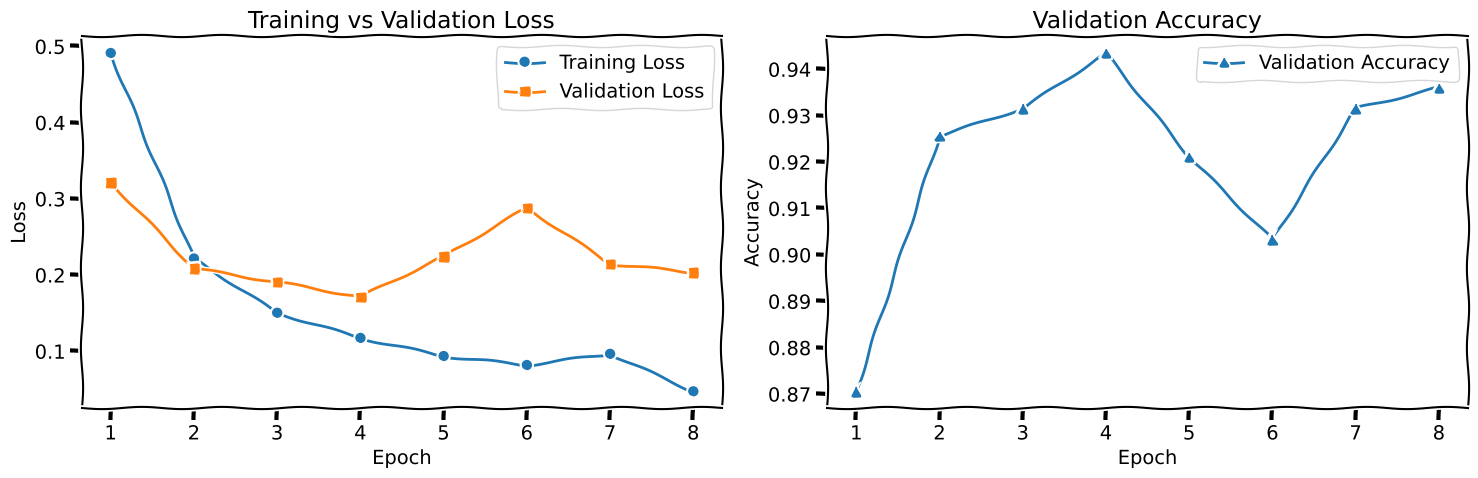

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt

if len(train_loss_history) == 0:
    raise RuntimeError("尚未訓練模型，沒有曲線可以繪製。")

epochs_range = range(1, len(train_loss_history) + 1)

with plt.xkcd(scale=1.1, length=80, randomness=1):

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(15, 5)
    )

    # =====================
    # Loss
    # =====================

    axes[0].plot(
        epochs_range,
        train_loss_history,
        marker="o",
        linewidth=2,
        label="Training Loss"
    )

    axes[0].plot(
        epochs_range,
        val_loss_history,
        marker="s",
        linewidth=2,
        label="Validation Loss"
    )

    axes[0].set_title("Training vs Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    # =====================
    # Accuracy
    # =====================

    axes[1].plot(
        epochs_range,
        val_acc_history,
        marker="^",
        linewidth=2,
        label="Validation Accuracy"
    )

    axes[1].set_title("Validation Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## 11. 保存最後模型與訓練紀錄

除了最佳模型外，也可以保存最後一輪模型與訓練紀錄，方便日後比對實驗。

In [ ]:
# 保存最後一輪模型。
unwrap_model(model).save_pretrained(FINAL_MODEL_DIR)
processor.save_pretrained(FINAL_MODEL_DIR)

history_df = pd.DataFrame({
    "epoch": list(range(1, len(train_loss_history) + 1)),
    "train_loss": train_loss_history,
    "val_loss": val_loss_history,
    "val_accuracy": val_acc_history,
})
history_csv_path = OUTPUT_DIR / "training_history.csv"
history_df.to_csv(history_csv_path, index=False)

eval_summary_path = OUTPUT_DIR / "final_eval_summary.txt"
eval_summary_path.write_text(
    "Final Validation Evaluation\n"
    f"loss={final_val_loss:.6f}\n"
    f"accuracy={accuracy:.6f}\n"
    f"precision={precision:.6f}\n"
    f"recall={recall:.6f}\n"
    f"f1={f1:.6f}\n",
    encoding="utf-8",
)

print(f"最佳模型：{BEST_MODEL_DIR}")
print(f"最後模型：{FINAL_MODEL_DIR}")
print(f"訓練紀錄：{history_csv_path}")
print(f"評估摘要：{eval_summary_path}")

## 12. 備份到 Google Drive

Colab runtime 斷線後，`/content` 內的檔案可能消失。  
建議訓練完成後，把最佳模型備份到 Google Drive。


In [ ]:
# 若不需要備份到 Google Drive，可以跳過此格。
try:
    from google.colab import drive
    drive.mount("/content/drive")

    destination = Path(DRIVE_BACKUP_DIR)
    if destination.exists():
        shutil.rmtree(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(BEST_MODEL_DIR, destination)

    print(f"最佳模型已備份到 Google Drive：{destination}")
except Exception as exc:
    print(f"Google Drive 備份失敗或不在 Colab 環境：{exc}")


Mounted at /content/drive
最佳模型已備份到 Google Drive：/content/drive/MyDrive/Basketball_Project/Model_VideoMAE_H100_V2


## 13. 下次直接載入已訓練模型

若已經有訓練好的模型，可不必重新訓練，直接用以下方式載入。  
`model_path` 可設定成本機輸出資料夾或 Google Drive 備份路徑。

In [ ]:
# 範例：從最佳模型資料夾載入。
model_path = BEST_MODEL_DIR

loaded_processor = VideoMAEImageProcessor.from_pretrained(model_path)
loaded_model = VideoMAEForVideoClassification.from_pretrained(model_path).to(device)
loaded_model.eval()

print(f"模型已載入：{model_path}")
print(f"目前裝置：{device}")

##  如何調整下一輪實驗

建議下一步不要只看 accuracy，至少同步比較 precision、recall、F1-score，因為「出手」通常才是你真正關心的事件。

### 可以優先測試的參數

1. `MODEL_NAME`  
   測試不同 VideoMAE 或其他 video classification backbone。

2. `MAX_FRAMES`  
   目前是 16。若出手瞬間容易漏掉，可測試 24 或 32，但 GPU 記憶體會增加。

3. `BATCH_SIZE`  
   記憶體不足就降低；高階 GPU 可提高。batch size 改變時，learning rate 也可能要跟著微調。

4. `LEARNING_RATE`  
   可測試 `1e-5`、`2e-5`、`3e-5`。如果 validation loss 震盪明顯，通常先降低 learning rate。

5. `WEIGHT_DECAY`  
   可測試 `0.0`、`0.01`、`0.05`。若過擬合嚴重，可提高 weight decay。

6. `PATIENCE`  
   若 validation accuracy 會短暫震盪，可略提高 patience；若資料少且容易過擬合，可降低。

### 對你目前圖表的建議
目前第 5 個 epoch 之後，validation loss 開始上升，accuracy 從高點回落，建議下一版實驗：

- 保留 Early Stopping。
- 優先採用最佳 epoch 的權重，而不是最後一輪。
- 加入 confusion matrix 檢查模型是否偏向預測 Shot 或 Non-Shot。
- 未來若要做長影片自動切片，應該再測試 sliding window 下的 false positive rate，因為長影片中錯誤觸發會被放大。


# Prototype VER.1

## 14. Gradio 介面：上傳影片並判斷 Shot / Non-Shot

本節使用訓練完成的 VideoMAE 模型建立簡單 demo 介面。  

使用者可以上傳一段籃球短片，系統會輸出 Shot 與 Non-Shot 的分類機率。

此 demo 主要用於展示模型是否能判斷「短片段是否包含出手事件」。  

若未來要處理完整比賽影片，需要再加入 sliding window，將長影片切成多個短片段後逐段判斷。

### 14-1 安裝與匯入 Gradio

In [ ]:
!pip install -q gradio

import gradio as gr
import torch
import numpy as np
import decord
from decord import VideoReader, cpu
from pathlib import Path

### 14-2 載入模型：訓練完直接用 / 或從資料夾載入

這一格獨立處理模型載入。
如果你是訓練完直接接著做 Demo，可以用 USE_CURRENT_MODEL = True。
如果你是下次重新打開 Notebook，沒有重新訓練，就改成 USE_CURRENT_MODEL = False。

In [ ]:
from transformers import VideoMAEImageProcessor, VideoMAEForVideoClassification

import torch
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("使用裝置:", device)

if torch.cuda.is_available():
  print(
      "GPU:",
      torch.cuda.get_device_name(0)
)
# ============================================================
# 14-2. Load VideoMAE model for Gradio demo
# ============================================================

# True：
#   適合「剛訓練完」直接接 Gradio。
#   會使用目前記憶體中的 model 和 processor。
#
# False：
#   適合「下次重新開 Notebook」直接載入已訓練好的模型。
#   會從 SAVED_MODEL_DIR 載入模型與 processor。
# USE_CURRENT_MODEL = True
USE_CURRENT_MODEL = False

# 若不需要備份到 Google Drive，可以跳過此格。
from google.colab import drive
drive.mount("/content/drive")
# 若 USE_CURRENT_MODEL = False，請指定模型資料夾。
# 你可以改成：
# SAVED_MODEL_DIR = BEST_MODEL_DIR
SAVED_MODEL_DIR = Path("/content/drive/MyDrive/Basketball_Project/Model_VideoMAE_H100_V2")

# Gradio 推論時使用的模型名稱與 processor

# 注意：這裡不要覆蓋訓練用的 model，避免你後面還想繼續訓練。
demo_model = None
demo_processor = None

if USE_CURRENT_MODEL:
    # --------------------------------------------------------
    # 情況 A：剛訓練完，直接使用目前記憶體中的模型
    # --------------------------------------------------------
    try:
        demo_model = unwrap_model(model)
    except NameError:
        demo_model = model

    demo_processor = processor

    print("✅ 使用目前記憶體中的訓練模型作為 Gradio demo model。")

else:
    # --------------------------------------------------------
    # 情況 B：重新載入已儲存模型
    # --------------------------------------------------------
    SAVED_MODEL_DIR = Path(SAVED_MODEL_DIR)

    if not SAVED_MODEL_DIR.exists():
        raise FileNotFoundError(
            f"找不到模型資料夾：{SAVED_MODEL_DIR}\n"
            "請確認 BEST_MODEL_DIR 或 Google Drive 路徑是否正確。"
        )

    demo_processor = VideoMAEImageProcessor.from_pretrained(SAVED_MODEL_DIR)
    demo_model = VideoMAEForVideoClassification.from_pretrained(SAVED_MODEL_DIR)

    print(f"✅ 已從資料夾載入模型：{SAVED_MODEL_DIR}")

demo_model.to(device)
demo_model.eval()

print(f"Gradio demo model 已準備完成，使用裝置：{device}")

### 14-3 影片抽幀與前處理函數

這裡的重點是：推論時的抽幀方式要盡量跟驗證集一致。

你訓練時的 validation 是把影片平均切成 MAX_FRAMES 個區間，每個區間取中間幀，所以這裡也照同樣邏輯做。

In [ ]:
# ============================================================
# 14-3. Video preprocessing for VideoMAE inference
# ============================================================

def sample_video_indices(total_frames: int, max_frames: int = 16) -> np.ndarray:
    """
    將影片平均分成 max_frames 個區間，並從每個區間取中間幀。

    這個邏輯要盡量與 validation dataset 保持一致，
    才能讓 Gradio 推論結果接近訓練 / 驗證時的資料分布。
    """
    if total_frames <= 0:
        raise ValueError("影片沒有任何影格，無法推論。")

    if total_frames >= max_frames:
        boundaries = np.linspace(0, total_frames, max_frames + 1, dtype=int)

        indices = []
        for i in range(max_frames):
            start = boundaries[i]
            end = boundaries[i + 1]
            end = max(end, start + 1)

            # 推論時不做 random sampling，固定取每個區間的中間幀。
            middle_index = (start + end - 1) // 2
            indices.append(middle_index)

        return np.array(indices, dtype=int)

    # 如果影片幀數少於 max_frames，就重複取樣補到 max_frames。
    return np.linspace(0, total_frames - 1, max_frames, dtype=int)


def load_video_for_videomae(video_path: str, processor, max_frames: int = 16) -> torch.Tensor:
    """
    讀取上傳影片，轉成 VideoMAE 可以接受的 pixel_values。

    回傳形狀：
    - pixel_values: (1, T, C, H, W)

    其中：
    - 1 是 batch size
    - T 是 MAX_FRAMES
    - C 是 RGB 三通道
    - H, W 是 processor resize 後的影像大小
    """
    if video_path is None:
        raise ValueError("請先上傳影片。")

    video_path = str(video_path)

    vr = VideoReader(video_path, ctx=cpu(0))
    total_frames = len(vr)

    if total_frames == 0:
        raise ValueError("影片讀取成功，但沒有任何影格。")

    indices = sample_video_indices(
        total_frames=total_frames,
        max_frames=max_frames
    )

    # decord 讀出來是 torch tensor，形狀為：
    # (T, H, W, C)
    frames = vr.get_batch(indices)

    # decord NDArray -> numpy
    frames = frames.asnumpy()

    # numpy -> torch tensor
    frames = torch.from_numpy(frames)

    # 轉成：
    # (T, C, H, W)
    # 並轉為 float，和你訓練 Dataset 中的寫法一致。
    frames = frames.permute(
        0,
        3,
        1,
        2
    ).float()

    # processor 會做 resize、center crop、normalize 等處理。
    # 這裡傳入 list(frames)，與你訓練時 BinaryBasketballVideoDataset 的寫法一致。
    inputs = processor(
        list(frames),
        return_tensors="pt",
        do_rescale=True
    )

    # inputs["pixel_values"] 形狀為：
    # (1, T, C, H, W)
    pixel_values = inputs["pixel_values"]

    return pixel_values

## 14-4 單支影片預測函數

這個函數會給 Gradio 使用。
輸出會顯示兩類的機率：

* Shot / 出手
* Non-Shot / 非出手

In [ ]:
# ============================================================
# 14-4. Prediction function
# ============================================================

GRADIO_CLASS_NAMES = {
    0: "Non-Shot / 非出手",
    1: "Shot / 出手"
}

def predict_basketball_video(video_path):
    """
    Gradio 會把使用者上傳的影片路徑傳進來。
    此函數負責：
    1. 讀取影片
    2. 抽取固定數量影格
    3. 做 VideoMAE 前處理
    4. 使用訓練好的模型推論
    5. 回傳分類機率
    """
    try:
        pixel_values = load_video_for_videomae(
            video_path=video_path,
            processor=demo_processor,
            max_frames=MAX_FRAMES
        )

        pixel_values = pixel_values.to(device)

        with torch.no_grad():
            outputs = demo_model(pixel_values=pixel_values)
            logits = outputs.logits
            probabilities = torch.softmax(logits, dim=-1)[0]

        non_shot_prob = float(probabilities[0].detach().cpu())
        shot_prob = float(probabilities[1].detach().cpu())

        predicted_label_id = int(torch.argmax(probabilities).detach().cpu())
        predicted_label_name = GRADIO_CLASS_NAMES[predicted_label_id]

        # 給 gr.Label 使用的格式：{類別名稱: 機率}
        label_result = {
            "Shot / 出手": shot_prob,
            "Non-Shot / 非出手": non_shot_prob
        }

        # 額外輸出一段文字，讓 demo 看起來更清楚。
        summary = (
            f"模型判斷結果：{predicted_label_name}\n\n"
            f"Shot / 出手機率：{shot_prob:.2%}\n"
            f"Non-Shot / 非出手機率：{non_shot_prob:.2%}\n\n"
            f"使用影格數：{MAX_FRAMES} frames\n"
            f"使用裝置：{device}"
        )

        return label_result, summary

    except Exception as exc:
        error_result = {
            "Shot / 出手": 0.0,
            "Non-Shot / 非出手": 0.0
        }

        error_message = (
            "影片推論失敗。\n\n"
            f"錯誤原因：{exc}\n\n"
            "請確認上傳的是 mp4、mov、avi 等常見影片格式，"
            "並且影片可以正常播放。"
        )

        return error_result, error_message

### 14-5 建立 Gradio 介面

In [ ]:
# ============================================================
# 14-5. Build Gradio interface
# ============================================================

demo = gr.Interface(
    fn=predict_basketball_video,

    inputs=gr.Video(
        label="上傳籃球短片",
        sources=["upload"]
    ),

    outputs=[
        gr.Label(
            label="模型分類機率",
            num_top_classes=2
        ),
        gr.Textbox(
            label="詳細判斷結果",
            lines=8
        )
    ],

    title="🏀 Basketball Shot / Non-Shot VideoMAE Classifier",

    description="""
上傳一段籃球短影片，模型會判斷該片段是否包含「出手」動作。

目前分類：
- Shot / 出手
- Non-Shot / 非出手

注意：此模型是針對短片段分類，不是完整長影片逐秒切片。
如果要做長影片自動切片，下一階段需要加入 sliding window 掃描。
""",

    allow_flagging="never"
)

demo.launch(
    debug=True,
    share=True
)

# Prototype VER.2

In [ ]:
!pip install -q gradio

import gradio as gr
import torch
import numpy as np
import decord
from decord import VideoReader, cpu
from pathlib import Path

In [ ]:
from transformers import VideoMAEImageProcessor, VideoMAEForVideoClassification

import torch
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("使用裝置:", device)

if torch.cuda.is_available():
  print(
      "GPU:",
      torch.cuda.get_device_name(0)
)
# ============================================================
# 14-2. Load VideoMAE model for Gradio demo
# ============================================================

# True：
#   適合「剛訓練完」直接接 Gradio。
#   會使用目前記憶體中的 model 和 processor。
#
# False：
#   適合「下次重新開 Notebook」直接載入已訓練好的模型。
#   會從 SAVED_MODEL_DIR 載入模型與 processor。
# USE_CURRENT_MODEL = True
USE_CURRENT_MODEL = False

# 若不需要備份到 Google Drive，可以跳過此格。
from google.colab import drive
drive.mount("/content/drive")
# 若 USE_CURRENT_MODEL = False，請指定模型資料夾。
# 你可以改成：
# SAVED_MODEL_DIR = BEST_MODEL_DIR
SAVED_MODEL_DIR = Path("/content/drive/MyDrive/Basketball_Project/Model_VideoMAE_H100_V2")

# Gradio 推論時使用的模型名稱與 processor

# 注意：這裡不要覆蓋訓練用的 model，避免你後面還想繼續訓練。
demo_model = None
demo_processor = None

if USE_CURRENT_MODEL:
    # --------------------------------------------------------
    # 情況 A：剛訓練完，直接使用目前記憶體中的模型
    # --------------------------------------------------------
    try:
        demo_model = unwrap_model(model)
    except NameError:
        demo_model = model

    demo_processor = processor

    print("✅ 使用目前記憶體中的訓練模型作為 Gradio demo model。")

else:
    # --------------------------------------------------------
    # 情況 B：重新載入已儲存模型
    # --------------------------------------------------------
    SAVED_MODEL_DIR = Path(SAVED_MODEL_DIR)

    if not SAVED_MODEL_DIR.exists():
        raise FileNotFoundError(
            f"找不到模型資料夾：{SAVED_MODEL_DIR}\n"
            "請確認 BEST_MODEL_DIR 或 Google Drive 路徑是否正確。"
        )

    demo_processor = VideoMAEImageProcessor.from_pretrained(SAVED_MODEL_DIR)
    demo_model = VideoMAEForVideoClassification.from_pretrained(SAVED_MODEL_DIR)

    print(f"✅ 已從資料夾載入模型：{SAVED_MODEL_DIR}")

demo_model.to(device)
demo_model.eval()

print(f"Gradio demo model 已準備完成，使用裝置：{device}")

MAX_FRAMES = 16

使用裝置: cuda
GPU: Tesla T4
Mounted at /content/drive


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

✅ 已從資料夾載入模型：/content/drive/MyDrive/Basketball_Project/Model_VideoMAE_H100_V2
Gradio demo model 已準備完成，使用裝置：cuda


## 15. Final Product：Basketball Shot Detection System

本 Notebook 區塊承接第 14 節已完成的 VideoMAE 短影片分類 Prototype，進一步實作完整展示系統。

本節目標包含兩種使用模式：

1. **短影片分類模式 Short Clip Classification**  
   使用者可以自行上傳短影片，或直接選用 Google Drive 中的 `shot` / `non_shot` 範例影片，讓模型判斷該短片是否包含出手動作。

2. **長影片自動偵測與切片模式 Long Video Shot Segmentation**  
   使用者可以上傳長影片，或選用 Google Drive 中的長影片範例。系統會使用 sliding window 逐段掃描長影片，偵測可能的出手時間點，輸出：
   - 出手時間標記 `.txt`
   - 切好的出手片段 `.zip`
   - 若提供人工標記檔，則計算 Precision、Recall、F1 與平均時間誤差

---

### 設計原則

本研究的 VideoMAE 模型是針對短片段進行二元分類：

- `Shot / 出手`
- `Non-Shot / 非出手`

因此長影片不能一次直接丟進模型，而是需要：

```text
長影片
↓
以 6 秒為單位建立 sliding window
↓
每 1 秒滑動一次
↓
每個 window 丟入 VideoMAE
↓
取得 Shot probability
↓
超過門檻者視為候選出手事件
↓
合併相近事件
↓
輸出時間標記與切片影片
```

本節預設與資料集製作邏輯一致：

```text
每個出手片段 = 出手前 4 秒 + 出手後 2 秒
```

所以如果某個 6 秒 window 被模型判斷為出手，推估出手時間點為：

```text
predicted_shot_time = window_start + 4.0
```

這樣與你用 `clip_dataset_builder.py` 建立訓練資料時的切片邏輯一致。

In [ ]:
# ============================================================
# 15-1. Imports and basic environment check
# ============================================================

from pathlib import Path
import os
import re
import math
import json
import time
import shutil
import zipfile
import subprocess
import tempfile
import warnings

import numpy as np
import torch
import decord
from decord import VideoReader, cpu

# Gradio 若尚未安裝，請先執行：!pip install -q gradio
try:
    import gradio as gr
except ImportError:
    raise ImportError("請先執行：!pip install -q gradio")

# 本節會沿用第 14 節建立好的 demo_model、demo_processor、device、MAX_FRAMES。
# 若你是重新打開 Notebook，請先執行第 14-2 的模型載入區塊。
required_names = ["demo_model", "demo_processor", "device", "MAX_FRAMES"]
missing_names = [name for name in required_names if name not in globals()]

if missing_names:
    raise RuntimeError(
        "缺少必要變數：" + ", ".join(missing_names) + "\n"
        "請先執行第 14-2 模型載入區塊，確保 demo_model、demo_processor、device、MAX_FRAMES 已存在。"
    )

# 推論階段不需要梯度。
demo_model.to(device)
demo_model.eval()

print("✅ 第 15 節環境確認完成")
print(f"Device: {device}")
print(f"MAX_FRAMES: {MAX_FRAMES}")

✅ 第 15 節環境確認完成
Device: cuda
MAX_FRAMES: 16


## 15-2. Demo dataset 路徑設定

請將 Google Drive 中的 demo 資料整理成下列結構：

```text
/content/drive/MyDrive/Basketball_Project/demo_dataset/
├── shot/
│   ├── A03_xxx.mp4
│   └── ...
├── non_shot/
│   ├── n_A03_xxx.mp4
│   └── ...
└── long/
    ├── Q1.mp4
    ├── Q1.txt
    ├── Q2.mp4
    ├── Q2.txt
    ├── Q3.mp4
    ├── Q3.txt
    ├── Q4.mp4
    └── Q4.txt
```

其中 `Q1.txt`、`Q2.txt` 等人工標記檔，每一行只需要放一個出手時間，例如：

```text
00:15
00:42
01:10
```

目前若還沒有人工標記檔，也可以先只放長影片，系統仍可輸出模型預測的出手時間與切片結果。

In [ ]:
# ============================================================
# 15-2. Demo dataset path settings
# ============================================================

DEMO_DATASET_DIR = Path("/content/drive/MyDrive/Basketball_Project/demo_dataset")

EXAMPLE_SHORT_SHOT_DIR = DEMO_DATASET_DIR / "shot"
EXAMPLE_SHORT_NON_SHOT_DIR = DEMO_DATASET_DIR / "non_shot"
EXAMPLE_LONG_VIDEO_DIR = DEMO_DATASET_DIR / "long"

# 本節輸出會集中到這個資料夾，避免污染原始 demo_dataset。
FINAL_DEMO_OUTPUT_DIR = Path("/content/basketball_shot_detection_outputs")
FINAL_DEMO_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 支援的影片格式。
VIDEO_EXTENSIONS = {".mp4", ".mov", ".avi", ".mkv", ".m4v"}

print("Demo dataset paths:")
print(f"Shot examples     : {EXAMPLE_SHORT_SHOT_DIR}")
print(f"Non-shot examples : {EXAMPLE_SHORT_NON_SHOT_DIR}")
print(f"Long examples     : {EXAMPLE_LONG_VIDEO_DIR}")
print(f"Output dir        : {FINAL_DEMO_OUTPUT_DIR}")

Demo dataset paths:
Shot examples     : /content/drive/MyDrive/Basketball_Project/demo_dataset/shot
Non-shot examples : /content/drive/MyDrive/Basketball_Project/demo_dataset/non_shot
Long examples     : /content/drive/MyDrive/Basketball_Project/demo_dataset/long
Output dir        : /content/basketball_shot_detection_outputs


## 15-3. Long-video inference parameters

這些參數會直接影響長影片偵測結果：

| 參數 | 預設值 | 說明 |
|---|---:|---|
| `LONG_VIDEO_WINDOW_SECONDS` | 6.0 | 每次丟給模型判斷的短片長度 |
| `LONG_VIDEO_STRIDE_SECONDS` | 1.0 | sliding window 每次前進幾秒 |
| `SHOT_THRESHOLD` | 0.70 | Shot probability 超過此值才視為候選出手 |
| `MERGE_DISTANCE_SECONDS` | 3.0 | 多個相近候選點會合併成同一球 |
| `SHOT_PRE_SECONDS` | 4.0 | 輸出切片時，保留出手前幾秒 |
| `SHOT_POST_SECONDS` | 2.0 | 輸出切片時，保留出手後幾秒 |
| `MATCH_TOLERANCE_SECONDS` | 2.0 | 與人工標記比對時，允許的時間誤差 |

若偵測結果太多誤判，可以提高 `SHOT_THRESHOLD`，例如 0.80。  
若漏掉太多出手，可以降低 `SHOT_THRESHOLD`，例如 0.60。

In [ ]:
# ============================================================
# 15-3. Long video segmentation parameters
# ============================================================

LONG_VIDEO_WINDOW_SECONDS = 6.0
LONG_VIDEO_STRIDE_SECONDS = 1.0
SHOT_THRESHOLD = 0.70
MERGE_DISTANCE_SECONDS = 3.0

# 與 clip_dataset_builder.py 的訓練資料切片邏輯一致：出手前 4 秒 + 出手後 2 秒。
SHOT_PRE_SECONDS = 4.0
SHOT_POST_SECONDS = 2.0

# 與人工標記比對時，預測時間點與人工標記相差不超過此秒數即算命中。
MATCH_TOLERANCE_SECONDS = 2.0

# 長影片掃描時，是否輸出每個 window 的機率紀錄 CSV。
SAVE_WINDOW_PROBABILITY_CSV = True

print("Long-video parameters:")
print(f"Window seconds     : {LONG_VIDEO_WINDOW_SECONDS}")
print(f"Stride seconds     : {LONG_VIDEO_STRIDE_SECONDS}")
print(f"Shot threshold     : {SHOT_THRESHOLD}")
print(f"Merge distance     : {MERGE_DISTANCE_SECONDS}")
print(f"Clip range         : -{SHOT_PRE_SECONDS}s ~ +{SHOT_POST_SECONDS}s")
print(f"Match tolerance    : {MATCH_TOLERANCE_SECONDS}s")

Long-video parameters:
Window seconds     : 6.0
Stride seconds     : 1.0
Shot threshold     : 0.7
Merge distance     : 3.0
Clip range         : -4.0s ~ +2.0s
Match tolerance    : 2.0s


## 15-4. 共用工具函數

本區包含：

- 時間格式轉換，例如 `00:15` → `15.0` 秒
- 秒數格式化，例如 `75.3` → `01:15.300`
- ffmpeg / ffprobe 呼叫
- 取得影片長度
- 建立範例影片清單
- 壓縮輸出資料夾

In [ ]:
# ============================================================
# 15-4. Utility functions
# ============================================================

def require_command(command: str) -> str:
    """確認系統是否有指定 command，例如 ffmpeg、ffprobe。"""
    path = shutil.which(command)
    if path is None:
        raise RuntimeError(f"找不到 `{command}`，請確認執行環境已安裝。")
    return path


def run_command(command: list[str], description: str = "command") -> None:
    """執行 shell command；若失敗則回傳清楚錯誤。"""
    completed = subprocess.run(command, capture_output=True, text=True)
    if completed.returncode != 0:
        stderr = completed.stderr.strip()
        stdout = completed.stdout.strip()
        detail = stderr or stdout or "沒有錯誤輸出"
        raise RuntimeError(f"{description} 失敗：{detail}")


def parse_time_to_seconds(text: str) -> float:
    """將人工標記的時間字串轉成秒數。

    支援格式：
    - MM:SS，例如 00:15
    - HH:MM:SS，例如 01:02:03
    - 使用全形冒號，例如 00：15
    - 純秒數，例如 15.5
    """
    value = str(text).strip().replace("：", ":")
    if not value:
        raise ValueError("空白時間字串無法解析。")

    # 純秒數。
    if re.fullmatch(r"\d+(?:\.\d+)?", value):
        return float(value)

    parts = value.split(":")
    if len(parts) == 2:
        minutes = int(parts[0])
        seconds = float(parts[1])
        return minutes * 60 + seconds

    if len(parts) == 3:
        hours = int(parts[0])
        minutes = int(parts[1])
        seconds = float(parts[2])
        return hours * 3600 + minutes * 60 + seconds

    raise ValueError(f"不支援的時間格式：{text}")


def seconds_to_timestamp(seconds: float) -> str:
    """將秒數轉成 MM:SS.mmm 格式。"""
    seconds = max(float(seconds), 0.0)
    minutes = int(seconds // 60)
    sec = seconds - minutes * 60
    return f"{minutes:02d}:{sec:06.3f}"


def seconds_to_filename_token(seconds: float) -> str:
    """將秒數轉成適合檔名使用的字串。"""
    return seconds_to_timestamp(seconds).replace(":", "-").replace(".", "-")


def get_video_duration(video_path: str | Path) -> float:
    """使用 ffprobe 取得影片長度，單位為秒。"""
    ffprobe = require_command("ffprobe")
    command = [
        ffprobe,
        "-v", "error",
        "-show_entries", "format=duration",
        "-of", "default=noprint_wrappers=1:nokey=1",
        str(video_path),
    ]
    completed = subprocess.run(command, capture_output=True, text=True)
    if completed.returncode != 0:
        raise RuntimeError(f"讀取影片長度失敗：{completed.stderr.strip()}")
    return float(completed.stdout.strip())


def list_video_files(directory: str | Path) -> list[Path]:
    """列出資料夾中的影片檔。"""
    directory = Path(directory)
    if not directory.exists():
        return []
    return sorted([
        path for path in directory.iterdir()
        if path.is_file() and path.suffix.lower() in VIDEO_EXTENSIONS
    ])


def zip_directory(source_dir: str | Path, zip_path: str | Path) -> Path:
    """將資料夾壓縮為 zip。"""
    source_dir = Path(source_dir)
    zip_path = Path(zip_path)
    zip_path.parent.mkdir(parents=True, exist_ok=True)

    if zip_path.exists():
        zip_path.unlink()

    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
        for file_path in source_dir.rglob("*"):
            if file_path.is_file():
                zipf.write(file_path, arcname=file_path.relative_to(source_dir))

    return zip_path


def safe_stem(path: str | Path) -> str:
    """將檔名轉成安全資料夾名稱。"""
    stem = Path(path).stem
    stem = re.sub(r"[^A-Za-z0-9_\-]+", "_", stem)
    return stem[:80] if stem else "video"

## 15-5. 讀取人工標記檔

長影片範例可搭配同名 `.txt` 標記檔，例如：

```text
Q1.mp4
Q1.txt
```

`Q1.txt` 內容每行一個時間點：

```text
00:15
00:42
01:10
```

系統會讀取這些時間，與模型預測的出手時間點做比對。

In [ ]:
# ============================================================
# 15-5. Manual annotation parser
# ============================================================

def read_manual_annotation_file(annotation_path: str | Path) -> list[float]:
    """讀取人工標記檔，每一行代表一個出手時間點。

    範例：
        00:15
        00:42
        01:10

    回傳：
        [15.0, 42.0, 70.0]
    """
    annotation_path = Path(annotation_path)
    if not annotation_path.exists():
        return []

    times = []
    for raw_line in annotation_path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#"):
            continue
        try:
            times.append(parse_time_to_seconds(line))
        except Exception as exc:
            warnings.warn(f"略過無法解析的標記行：{line}；原因：{exc}")

    return sorted(times)


def find_annotation_for_video(video_path: str | Path) -> Path | None:
    """尋找與影片同名的人工標記檔。

    例如：
        /long/Q1.mp4 -> /long/Q1.txt
    """
    video_path = Path(video_path)
    candidate = video_path.with_suffix(".txt")
    return candidate if candidate.exists() else None


def format_annotation_preview(times: list[float]) -> str:
    """將人工標記時間整理成可讀文字。"""
    if not times:
        return "目前沒有讀取到人工標記。"

    return "\n".join(
        f"{i+1:02d}. {seconds_to_timestamp(t)}"
        for i, t in enumerate(times)
    )

## 15-6. VideoMAE 單支短片推論函數

這裡會重用第 14 節已經成功的推論邏輯，但做兩個強化：

1. **不依賴 `decord.bridge.set_bridge("torch")`**  
   直接將 decord `NDArray` 轉成 numpy，再轉成 torch tensor，避免 Gradio 環境出現：

   ```text
   'NDArray' object has no attribute 'permute'
   ```

2. **固定使用 validation 的抽幀邏輯**  
   推論時不做 random sampling，而是平均切成 `MAX_FRAMES` 個區段，每段取中間幀。

In [ ]:
# ============================================================
# 15-6. VideoMAE short-clip inference utilities
# ============================================================

CLASS_NAMES_FOR_DEMO = {
    0: "Non-Shot / 非出手",
    1: "Shot / 出手",
}


def sample_video_indices(total_frames: int, max_frames: int = 16) -> np.ndarray:
    """將影片平均切成 max_frames 個區間，每個區間取中間幀。"""
    if total_frames <= 0:
        raise ValueError("影片沒有任何影格，無法推論。")

    if total_frames >= max_frames:
        boundaries = np.linspace(0, total_frames, max_frames + 1, dtype=int)
        indices = []
        for i in range(max_frames):
            start = boundaries[i]
            end = boundaries[i + 1]
            end = max(end, start + 1)
            middle_index = (start + end - 1) // 2
            indices.append(middle_index)
        return np.array(indices, dtype=int)

    # 影片幀數少於 max_frames 時，重複取樣補足。
    return np.linspace(0, total_frames - 1, max_frames, dtype=int)


def load_video_for_videomae(video_path: str | Path, processor, max_frames: int = 16) -> torch.Tensor:
    """將影片讀取並轉換為 VideoMAE 可接受的 pixel_values。

    回傳形狀：
        (1, T, C, H, W)
    """
    if video_path is None:
        raise ValueError("請先選擇或上傳影片。")

    video_path = str(video_path)
    vr = VideoReader(video_path, ctx=cpu(0))
    total_frames = len(vr)

    if total_frames == 0:
        raise ValueError("影片讀取成功，但沒有任何影格。")

    indices = sample_video_indices(total_frames=total_frames, max_frames=max_frames)

    # 不依賴 decord bridge，避免 Gradio 或重新啟動 Runtime 後出現 NDArray 沒有 permute 的問題。
    frames = vr.get_batch(indices).asnumpy()       # (T, H, W, C), uint8
    frames = torch.from_numpy(frames)              # torch.Tensor
    frames = frames.permute(0, 3, 1, 2).float()    # (T, C, H, W)

    inputs = processor(
        list(frames),
        return_tensors="pt",
        do_rescale=True,
    )

    pixel_values = inputs["pixel_values"]          # (1, T, C, H, W)
    return pixel_values


@torch.no_grad()
def predict_video_probabilities(video_path: str | Path) -> dict:
    """對一支短影片做 Shot / Non-Shot 推論。"""
    pixel_values = load_video_for_videomae(
        video_path=video_path,
        processor=demo_processor,
        max_frames=MAX_FRAMES,
    ).to(device)

    outputs = demo_model(pixel_values=pixel_values)
    logits = outputs.logits
    probabilities = torch.softmax(logits, dim=-1)[0]

    non_shot_prob = float(probabilities[0].detach().cpu())
    shot_prob = float(probabilities[1].detach().cpu())
    predicted_label_id = int(torch.argmax(probabilities).detach().cpu())

    return {
        "predicted_label_id": predicted_label_id,
        "predicted_label_name": CLASS_NAMES_FOR_DEMO[predicted_label_id],
        "shot_prob": shot_prob,
        "non_shot_prob": non_shot_prob,
    }


def predict_short_clip_for_gradio(video_path):
    """Gradio 短影片模式使用的 wrapper。"""

    try:
        result = predict_video_probabilities(video_path)

        label_result = {
            "Shot / 出手": result["shot_prob"],
            "Non-Shot / 非出手": result["non_shot_prob"],
        }

        summary = (
            f"模型判斷結果：{result['predicted_label_name']}\n\n"
            f"Shot / 出手機率：{result['shot_prob']:.2%}\n"
            f"Non-Shot / 非出手機率：{result['non_shot_prob']:.2%}\n\n"
            f"使用影格數：{MAX_FRAMES} frames\n"
            f"使用裝置：{device}"
        )

        return label_result, summary

    except Exception as exc:

        error_message = (
            "影片推論失敗。\n\n"
            f"錯誤原因：{exc}"
        )

        return (
            {
                "Shot / 出手": 0.0,
                "Non-Shot / 非出手": 0.0,
            },
            error_message,
        )

## 15-7. 短影片範例選擇功能

短影片模式支援兩種方式：

1. 使用者自行上傳短片
2. 從 Google Drive 的範例資料夾選擇影片

範例資料夾分成：

```text
shot/
non_shot/
```

由於你已經測試過模型不會受到檔名如 `A03`、`n_A03` 影響，因此範例檔案可保留原命名。

In [ ]:
# ============================================================
# 15-7. Short clip example helpers
# ============================================================

def build_short_example_choices() -> list[str]:
    """建立短影片範例選單。"""
    choices = []

    for path in list_video_files(EXAMPLE_SHORT_SHOT_DIR):
        choices.append(f"Shot 範例｜{path.name}")

    for path in list_video_files(EXAMPLE_SHORT_NON_SHOT_DIR):
        choices.append(f"Non-Shot 範例｜{path.name}")

    return choices


def resolve_short_example_choice(choice: str) -> str | None:
    """將選單文字轉成實際檔案路徑。"""
    if not choice:
        return None

    if choice.startswith("Shot 範例｜"):
        filename = choice.split("｜", 1)[1]
        path = EXAMPLE_SHORT_SHOT_DIR / filename
        return str(path) if path.exists() else None

    if choice.startswith("Non-Shot 範例｜"):
        filename = choice.split("｜", 1)[1]
        path = EXAMPLE_SHORT_NON_SHOT_DIR / filename
        return str(path) if path.exists() else None

    return None


def predict_short_from_example(choice):
    """使用範例短影片進行推論。"""
    video_path = resolve_short_example_choice(choice)
    if video_path is None:
        return (
            {"Shot / 出手": 0.0, "Non-Shot / 非出手": 0.0},
            "找不到範例影片，請確認 demo_dataset/shot 或 demo_dataset/non_shot 是否存在。"
        )
    return predict_short_clip_for_gradio(video_path)


short_example_choices = build_short_example_choices()
print(f"短影片範例數量：{len(short_example_choices)}")
for item in short_example_choices[:10]:
    print("-", item)

短影片範例數量：10
- Shot 範例｜A03_010.mp4
- Shot 範例｜A03_020.mp4
- Shot 範例｜A03_030.mp4
- Shot 範例｜A03_040.mp4
- Shot 範例｜A03_050.mp4
- Non-Shot 範例｜n_A03_010.mp4
- Non-Shot 範例｜n_A03_020.mp4
- Non-Shot 範例｜n_A03_030.mp4
- Non-Shot 範例｜n_A03_040.mp4
- Non-Shot 範例｜n_A03_050.mp4


## 15-8. 長影片 Sliding Window 掃描

長影片掃描使用下列策略：

1. 以 `LONG_VIDEO_WINDOW_SECONDS = 6.0` 秒作為一個判斷片段。
2. 每次滑動 `LONG_VIDEO_STRIDE_SECONDS = 1.0` 秒。
3. 對每個 window 建立暫存短片，丟入 VideoMAE 判斷。
4. 若 `Shot probability >= SHOT_THRESHOLD`，則記錄為候選出手事件。
5. 因為每個出手 clip 是「出手前 4 秒 + 出手後 2 秒」，因此：

```text
predicted_shot_time = window_start + SHOT_PRE_SECONDS
```

注意：這個版本重視清楚與穩定，會使用 ffmpeg 將長影片切成暫存 window，再呼叫前面已驗證成功的 VideoMAE 推論函數。速度不一定是最快，但最適合作為最終展示 Prototype。

In [ ]:
# ============================================================
# 15-8. Long video sliding-window prediction
# ============================================================

def cut_video_segment(
    video_path: str | Path,
    output_path: str | Path,
    start_seconds: float,
    duration_seconds: float,
    reencode: bool = True,
) -> Path:
    """使用 ffmpeg 從影片切出一段短片。

    reencode=True 較慢但相容性最好，適合 Gradio demo。
    """
    ffmpeg = require_command("ffmpeg")
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    command = [
        ffmpeg,
        "-y",
        "-ss", f"{max(start_seconds, 0.0):.3f}",
        "-t", f"{duration_seconds:.3f}",
        "-i", str(video_path),
    ]

    if reencode:
        command += [
            "-c:v", "libx264",
            "-crf", "23",
            "-preset", "veryfast",
            "-c:a", "aac",
            "-movflags", "+faststart",
        ]
    else:
        command += ["-c", "copy"]

    command += [str(output_path)]
    run_command(command, description=f"切片 {output_path.name}")
    return output_path


def build_windows(video_duration: float, window_seconds: float, stride_seconds: float) -> list[tuple[float, float]]:
    """建立 sliding windows，回傳 [(window_start, window_end), ...]。"""
    if video_duration <= 0:
        return []

    windows = []
    start = 0.0

    while start + window_seconds <= video_duration:
        windows.append((start, start + window_seconds))
        start += stride_seconds

    # 若影片最後剩餘片段不足一個完整 window，可視需求補最後一段。
    # 這裡若影片長度大於 window，額外加入最後一個完整 window，避免漏掉尾端出手。
    last_start = max(video_duration - window_seconds, 0.0)
    if windows and abs(windows[-1][0] - last_start) > 1e-6:
        windows.append((last_start, video_duration))
    elif not windows and video_duration > 0:
        windows.append((0.0, min(video_duration, window_seconds)))

    # 去除可能重複的 start。
    unique = []
    seen = set()
    for s, e in windows:
        key = round(s, 3)
        if key not in seen:
            unique.append((s, e))
            seen.add(key)

    return unique


def merge_candidate_shots(candidates: list[dict], merge_distance_seconds: float = 3.0) -> list[dict]:
    """合併相近的候選出手事件。

    若多個候選點距離很近，保留 shot_prob 最高者作為該事件代表。
    """
    if not candidates:
        return []

    candidates = sorted(candidates, key=lambda item: item["predicted_shot_time"])
    groups = []
    current_group = [candidates[0]]

    for item in candidates[1:]:
        previous_time = current_group[-1]["predicted_shot_time"]
        current_time = item["predicted_shot_time"]

        if current_time - previous_time <= merge_distance_seconds:
            current_group.append(item)
        else:
            groups.append(current_group)
            current_group = [item]

    groups.append(current_group)

    merged = []
    for group in groups:
        best = max(group, key=lambda item: item["shot_prob"])
        merged.append(best)

    return merged


def scan_long_video_for_shots(
    video_path: str | Path,
    output_root: str | Path,
    threshold: float = SHOT_THRESHOLD,
    window_seconds: float = LONG_VIDEO_WINDOW_SECONDS,
    stride_seconds: float = LONG_VIDEO_STRIDE_SECONDS,
    merge_distance_seconds: float = MERGE_DISTANCE_SECONDS,
    progress_callback=None,
) -> tuple[list[dict], list[dict], Path]:
    """掃描長影片，回傳：

    - merged_shots: 合併後的出手事件
    - window_records: 每個 window 的模型分數紀錄
    - temp_window_dir: 暫存 window 片段資料夾
    """
    video_path = Path(video_path)
    output_root = Path(output_root)
    temp_window_dir = output_root / "temp_windows"
    temp_window_dir.mkdir(parents=True, exist_ok=True)

    duration = get_video_duration(video_path)
    windows = build_windows(duration, window_seconds, stride_seconds)

    if not windows:
        raise RuntimeError("無法建立 sliding windows，請檢查影片長度。")

    candidates = []
    window_records = []

    for idx, (start, end) in enumerate(windows, start=1):
        actual_duration = end - start
        window_path = temp_window_dir / f"window_{idx:05d}_{seconds_to_filename_token(start)}.mp4"

        if progress_callback is not None:
            progress_callback(idx / len(windows), desc=f"Scanning window {idx}/{len(windows)}")

        cut_video_segment(
            video_path=video_path,
            output_path=window_path,
            start_seconds=start,
            duration_seconds=actual_duration,
            reencode=True,
        )

        pred = predict_video_probabilities(window_path)
        shot_prob = pred["shot_prob"]
        non_shot_prob = pred["non_shot_prob"]

        # 因訓練資料為 shot_time - 4s 到 shot_time + 2s，故 window 中推估出手點為 start + 4s。
        predicted_shot_time = start + SHOT_PRE_SECONDS

        record = {
            "window_index": idx,
            "window_start": start,
            "window_end": end,
            "predicted_shot_time": predicted_shot_time,
            "shot_prob": shot_prob,
            "non_shot_prob": non_shot_prob,
            "is_candidate": shot_prob >= threshold,
            "window_path": str(window_path),
        }
        window_records.append(record)

        if shot_prob >= threshold:
            candidates.append(record)

    merged_shots = merge_candidate_shots(candidates, merge_distance_seconds)
    return merged_shots, window_records, temp_window_dir

## 15-9. 長影片輸出：時間標記、切片、ZIP

長影片偵測完成後，系統會產生：

1. `shot_timestamps.txt`：模型偵測出的出手時間點與 confidence
2. `detected_shot_clips/`：切好的出手片段
3. `detected_shot_clips.zip`：切片影片壓縮檔，供使用者下載
4. `window_probabilities.csv`：每個 sliding window 的機率紀錄，方便研究分析

In [ ]:
# ============================================================
# 15-9. Long video outputs
# ============================================================

def write_shot_timestamps_txt(
    video_path: str | Path,
    merged_shots: list[dict],
    output_txt_path: str | Path,
    threshold: float,
    window_seconds: float,
    stride_seconds: float,
) -> Path:
    """寫出模型偵測的出手時間標記檔。"""
    output_txt_path = Path(output_txt_path)
    output_txt_path.parent.mkdir(parents=True, exist_ok=True)

    lines = []
    lines.append("Basketball Shot Detection Result")
    lines.append("=" * 40)
    lines.append(f"Video: {Path(video_path).name}")
    lines.append(f"Window seconds: {window_seconds:.3f}")
    lines.append(f"Stride seconds: {stride_seconds:.3f}")
    lines.append(f"Shot threshold: {threshold:.3f}")
    lines.append(f"Detected shot count: {len(merged_shots)}")
    lines.append("")
    lines.append("Detected Shots:")

    if not merged_shots:
        lines.append("No shot detected.")
    else:
        for idx, item in enumerate(merged_shots, start=1):
            t = item["predicted_shot_time"]
            prob = item["shot_prob"]
            lines.append(f"{idx:02d}. {seconds_to_timestamp(t)}	confidence={prob:.4f}")

    output_txt_path.write_text(
        "\n".join(lines),
        encoding="utf-8"
    )


def write_window_probability_csv(window_records: list[dict], output_csv_path: str | Path) -> Path:
    """輸出每個 sliding window 的分數紀錄。"""
    import csv

    output_csv_path = Path(output_csv_path)
    output_csv_path.parent.mkdir(parents=True, exist_ok=True)

    fields = [
        "window_index",
        "window_start",
        "window_end",
        "predicted_shot_time",
        "shot_prob",
        "non_shot_prob",
        "is_candidate",
        "window_path",
    ]

    with output_csv_path.open("w", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        for row in window_records:
            writer.writerow({field: row.get(field, "") for field in fields})

    return output_csv_path


def cut_detected_shot_clips(
    video_path: str | Path,
    merged_shots: list[dict],
    clips_dir: str | Path,
    pre_seconds: float = SHOT_PRE_SECONDS,
    post_seconds: float = SHOT_POST_SECONDS,
) -> list[Path]:
    """依據預測出手時間，切出出手片段。"""
    video_path = Path(video_path)
    clips_dir = Path(clips_dir)
    clips_dir.mkdir(parents=True, exist_ok=True)

    duration = get_video_duration(video_path)
    clip_paths = []

    for idx, item in enumerate(merged_shots, start=1):
        shot_time = float(item["predicted_shot_time"])
        start = max(shot_time - pre_seconds, 0.0)
        end = min(shot_time + post_seconds, duration)
        clip_duration = max(end - start, 0.1)

        output_name = f"shot_{idx:03d}_{seconds_to_filename_token(shot_time)}_conf_{item['shot_prob']:.2f}.mp4"
        output_path = clips_dir / output_name

        cut_video_segment(
            video_path=video_path,
            output_path=output_path,
            start_seconds=start,
            duration_seconds=clip_duration,
            reencode=True,
        )

        clip_paths.append(output_path)

    return clip_paths

## 15-10. 與人工標記比對

長影片事件偵測不適合用一般 classification accuracy 評估。  
更合理的是以「時間點是否對得上」來計算：

- **True Positive (TP)**：模型預測時間點與某個人工標記時間相差不超過 `MATCH_TOLERANCE_SECONDS`
- **False Positive (FP)**：模型預測出手，但附近沒有人工標記
- **False Negative (FN)**：人工有標記，但模型沒偵測到

並計算：

```text
Precision = TP / (TP + FP)
Recall    = TP / (TP + FN)
F1        = 2PR / (P + R)
```

In [ ]:
# ============================================================
# 15-10. Evaluation against manual annotations
# ============================================================

def match_predictions_to_ground_truth(
    predicted_times: list[float],
    ground_truth_times: list[float],
    tolerance_seconds: float = MATCH_TOLERANCE_SECONDS,
) -> dict:
    """將模型預測時間與人工標記時間做一對一匹配。"""
    predicted_times = sorted([float(t) for t in predicted_times])
    ground_truth_times = sorted([float(t) for t in ground_truth_times])

    matched_gt = set()
    matches = []
    false_positives = []

    for pred_time in predicted_times:
        best_gt_idx = None
        best_error = float("inf")

        for gt_idx, gt_time in enumerate(ground_truth_times):
            if gt_idx in matched_gt:
                continue
            error = abs(pred_time - gt_time)
            if error <= tolerance_seconds and error < best_error:
                best_error = error
                best_gt_idx = gt_idx

        if best_gt_idx is not None:
            matched_gt.add(best_gt_idx)
            matches.append({
                "pred_time": pred_time,
                "gt_time": ground_truth_times[best_gt_idx],
                "error": best_error,
            })
        else:
            false_positives.append(pred_time)

    false_negatives = [
        gt_time for gt_idx, gt_time in enumerate(ground_truth_times)
        if gt_idx not in matched_gt
    ]

    tp = len(matches)
    fp = len(false_positives)
    fn = len(false_negatives)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    avg_error = float(np.mean([m["error"] for m in matches])) if matches else None

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "avg_time_error": avg_error,
        "matches": matches,
        "false_positives": false_positives,
        "false_negatives": false_negatives,
    }


def format_evaluation_report(eval_result: dict, ground_truth_times: list[float], predicted_times: list[float]) -> str:
    """將評估結果整理成文字報告。"""
    lines = []
    lines.append("Manual Annotation Evaluation")
    lines.append("=" * 40)
    lines.append(f"Ground truth shot count : {len(ground_truth_times)}")
    lines.append(f"Predicted shot count    : {len(predicted_times)}")
    lines.append(f"True Positive           : {eval_result['tp']}")
    lines.append(f"False Positive          : {eval_result['fp']}")
    lines.append(f"False Negative          : {eval_result['fn']}")
    lines.append(f"Precision               : {eval_result['precision']:.4f}")
    lines.append(f"Recall                  : {eval_result['recall']:.4f}")
    lines.append(f"F1-score                : {eval_result['f1']:.4f}")

    if eval_result["avg_time_error"] is not None:
        lines.append(f"Average time error      : {eval_result['avg_time_error']:.3f} sec")
    else:
        lines.append("Average time error      : N/A")

    lines.append("")
    lines.append("Matched events:")
    if eval_result["matches"]:
        for idx, match in enumerate(eval_result["matches"], start=1):
            lines.append(
                f"{idx:02d}. pred={seconds_to_timestamp(match['pred_time'])}, "
                f"gt={seconds_to_timestamp(match['gt_time'])}, "
                f"error={match['error']:.3f}s"
            )
    else:
        lines.append("No matched events.")

    if eval_result["false_positives"]:
        lines.append("")
        lines.append("False positives:")
        for t in eval_result["false_positives"]:
            lines.append(f"- {seconds_to_timestamp(t)}")

    if eval_result["false_negatives"]:
        lines.append("")
        lines.append("False negatives:")
        for t in eval_result["false_negatives"]:
            lines.append(f"- {seconds_to_timestamp(t)}")

    return "\n".join(
        lines
    )

## 15-11. 長影片 Gradio 執行函數

此函數是長影片模式的主要入口。它會：

1. 取得使用者上傳影片或範例影片
2. 掃描長影片
3. 合併出手事件
4. 輸出 `shot_timestamps.txt`
5. 切出出手片段並打包 ZIP
6. 若有人工標記檔，輸出評估報告

In [ ]:
# ============================================================
# 15-11. Long video Gradio wrapper
# ============================================================

def build_long_example_choices() -> list[str]:
    """建立長影片範例選單。"""
    choices = []
    for path in list_video_files(EXAMPLE_LONG_VIDEO_DIR):
        choices.append(path.name)
    return choices


def resolve_long_example_choice(choice: str) -> str | None:
    if not choice:
        return None
    path = EXAMPLE_LONG_VIDEO_DIR / choice
    return str(path) if path.exists() else None


long_example_choices = build_long_example_choices()
print(f"長影片範例數量：{len(long_example_choices)}")
for item in long_example_choices[:10]:
    print("-", item)


def run_long_video_detection(
    uploaded_video,
    example_choice,
    threshold,
    stride_seconds,
    merge_distance_seconds,
    progress=gr.Progress(track_tqdm=False),
):
    """Gradio 長影片模式使用的主函數。"""

    try:

        # =====================================================
        # 1. 決定影片來源
        # =====================================================
        if uploaded_video is not None:
            video_path = Path(uploaded_video)
            source_type = "uploaded"

        else:
            example_path = resolve_long_example_choice(example_choice)

            if example_path is None:
                raise ValueError(
                    "請上傳長影片，或選擇一個長影片範例。"
                )

            video_path = Path(example_path)
            source_type = "example"

        # =====================================================
        # 2. 建立輸出資料夾
        # =====================================================
        run_id = (
            f"{safe_stem(video_path)}_"
            f"{int(time.time())}"
        )

        output_root = FINAL_DEMO_OUTPUT_DIR / run_id

        output_root.mkdir(
            parents=True,
            exist_ok=True
        )

        clips_dir = output_root / "detected_shot_clips"
        timestamps_txt_path = output_root / "shot_timestamps.txt"
        window_csv_path = output_root / "window_probabilities.csv"
        clips_zip_path = output_root / "detected_shot_clips.zip"
        eval_report_path = output_root / "evaluation_report.txt"

        progress(
            0.01,
            desc="準備長影片掃描"
        )

        # =====================================================
        # 3. Sliding Window 掃描
        # =====================================================
        merged_shots, window_records, temp_window_dir = (
            scan_long_video_for_shots(
                video_path=video_path,
                output_root=output_root,
                threshold=float(threshold),
                window_seconds=LONG_VIDEO_WINDOW_SECONDS,
                stride_seconds=float(stride_seconds),
                merge_distance_seconds=float(
                    merge_distance_seconds
                ),
                progress_callback=progress,
            )
        )

        progress(
            0.85,
            desc="輸出時間標記與切片影片"
        )

        # =====================================================
        # 4. 輸出時間標記 txt
        # =====================================================
        write_shot_timestamps_txt(
            video_path=video_path,
            merged_shots=merged_shots,
            output_txt_path=timestamps_txt_path,
            threshold=float(threshold),
            window_seconds=LONG_VIDEO_WINDOW_SECONDS,
            stride_seconds=float(stride_seconds),
        )

        # =====================================================
        # 5. 輸出 window csv
        # =====================================================
        if SAVE_WINDOW_PROBABILITY_CSV:

            write_window_probability_csv(
                window_records,
                window_csv_path,
            )

        # =====================================================
        # 6. 切片與 zip
        # =====================================================
        clip_paths = cut_detected_shot_clips(
            video_path=video_path,
            merged_shots=merged_shots,
            clips_dir=clips_dir,
            pre_seconds=SHOT_PRE_SECONDS,
            post_seconds=SHOT_POST_SECONDS,
        )

        zip_directory(
            clips_dir,
            clips_zip_path
        )

        # =====================================================
        # 7. 評估
        # =====================================================
        annotation_path = find_annotation_for_video(
            video_path
        )

        evaluation_text = ""

        if annotation_path is not None:

            gt_times = read_manual_annotation_file(
                annotation_path
            )

            pred_times = [
                item["predicted_shot_time"]
                for item in merged_shots
            ]

            eval_result = (
                match_predictions_to_ground_truth(
                    predicted_times=pred_times,
                    ground_truth_times=gt_times,
                    tolerance_seconds=MATCH_TOLERANCE_SECONDS,
                )
            )

            evaluation_text = (
                format_evaluation_report(
                    eval_result,
                    gt_times,
                    pred_times,
                )
            )

            eval_report_path.write_text(
                evaluation_text,
                encoding="utf-8",
            )

        else:

            evaluation_text = (
                "沒有找到同名人工標記檔，因此只輸出模型偵測結果。\n\n"
                "若要啟用評估，請在長影片旁放置同名 txt。\n"
                f"例如：\n{video_path.with_suffix('.txt')}"
            )

            eval_report_path.write_text(
                evaluation_text,
                encoding="utf-8",
            )

        # =====================================================
        # 8. 摘要
        # =====================================================
        summary_lines = []

        summary_lines.append(
            "長影片偵測完成"
        )

        summary_lines.append(
            "=" * 40
        )

        summary_lines.append(
            f"影片來源：{source_type}"
        )

        summary_lines.append(
            f"影片名稱：{video_path.name}"
        )

        summary_lines.append(
            f"偵測出手數：{len(merged_shots)}"
        )

        summary_lines.append(
            f"Threshold：{float(threshold):.2f}"
        )

        summary_lines.append(
            f"Stride：{float(stride_seconds):.2f} 秒"
        )

        summary_lines.append("")
        summary_lines.append("偵測時間點：")

        if merged_shots:

            for idx, item in enumerate(
                merged_shots,
                start=1
            ):

                summary_lines.append(
                    f"{idx:02d}. "
                    f"{seconds_to_timestamp(item['predicted_shot_time'])} "
                    f"confidence={item['shot_prob']:.4f}"
                )

        else:

            summary_lines.append(
                "未偵測到出手。"
            )

        summary_lines.append("")
        summary_lines.append(
            evaluation_text
        )

        summary_text = "\n".join(
            summary_lines
        )

        progress(
            1.0,
            desc="完成"
        )

        return (
            summary_text,
            str(timestamps_txt_path),
            str(clips_zip_path),
            str(window_csv_path)
            if window_csv_path.exists()
            else None,
            str(eval_report_path),
        )

    except Exception as exc:

        error_message = (
            "長影片偵測失敗。\n\n"
            f"錯誤原因：{exc}"
        )

        return (
            error_message,
            None,
            None,
            None,
            None,
        )

長影片範例數量：7
- A03.mp4
- A03_Q1.mp4
- A03_Q1_2min.mp4
- A03_Q2.mp4
- A03_Q3.mp4
- A03_Q4.mp4
- A03_Q4_2min.mp4


## 15-12. Gradio Final UI

此介面使用 `gr.Blocks` 建立雙模式系統：

- **短影片分類**：自行上傳或選擇短片範例
- **長影片偵測與切片**：自行上傳或選擇長片範例，輸出時間標記與切片 ZIP

如果在 Colab 中使用，建議：

```python
final_demo.launch(debug=True, share=True)
```

`share=True` 會產生公開連結，方便展示。

In [ ]:
# ============================================================
# 15-12. Gradio Final UI
# ============================================================

with gr.Blocks(title="Basketball Shot Detection System") as final_demo:
    gr.Markdown(
        """
        # 🏀 Basketball Shot Detection System

        本系統使用 VideoMAE 影片分類模型，提供兩種模式：

        1. **短影片分類**：判斷一支短影片是否包含出手動作。
        2. **長影片偵測與切片**：掃描長影片，輸出出手時間標記與切好的出手片段。

        建議先使用短影片模式確認模型正常，再使用長影片模式進行完整測試。
        """
    )

    with gr.Tab("短影片分類 Short Clip"):
        gr.Markdown(
            """
            ## 短影片分類

            可以自行上傳一支短影片，或從 Google Drive 中的 `shot` / `non_shot` 範例選擇影片進行測試。
            """
        )

        with gr.Row():
            with gr.Column():
                short_upload = gr.Video(label="自行上傳短影片")
                short_upload_button = gr.Button("使用上傳短片進行推論", variant="primary")

            with gr.Column():
                short_example_dropdown = gr.Dropdown(
                    choices=short_example_choices,
                    label="選擇短影片範例",
                    value=short_example_choices[0] if short_example_choices else None,
                )
                short_example_button = gr.Button("使用範例短片進行推論")

        short_label_output = gr.Label(label="模型分類機率", num_top_classes=2)
        short_summary_output = gr.Textbox(label="詳細判斷結果", lines=8)

        short_upload_button.click(
            fn=predict_short_clip_for_gradio,
            inputs=short_upload,
            outputs=[short_label_output, short_summary_output],
        )

        short_example_button.click(
            fn=predict_short_from_example,
            inputs=short_example_dropdown,
            outputs=[short_label_output, short_summary_output],
        )

    with gr.Tab("長影片偵測與切片 Long Video"):
        gr.Markdown(
            """
            ## 長影片偵測與切片

            系統會將長影片切成多個 6 秒 sliding windows，逐段判斷是否為出手片段。

            輸出內容包含：
            - 出手時間標記 `.txt`
            - 切好的出手片段 `.zip`
            - 每個 window 的機率紀錄 `.csv`
            - 若存在同名人工標記檔，會額外輸出評估報告
            """
        )

        with gr.Row():
            with gr.Column():
                long_upload = gr.Video(label="自行上傳長影片")
                long_example_dropdown = gr.Dropdown(
                    choices=long_example_choices,
                    label="或選擇長影片範例",
                    value=long_example_choices[0] if long_example_choices else None,
                )

            with gr.Column():
                threshold_slider = gr.Slider(
                    minimum=0.10,
                    maximum=0.99,
                    value=SHOT_THRESHOLD,
                    step=0.01,
                    label="Shot threshold",
                )
                stride_slider = gr.Slider(
                    minimum=0.5,
                    maximum=3.0,
                    value=LONG_VIDEO_STRIDE_SECONDS,
                    step=0.5,
                    label="Sliding window stride seconds",
                )
                merge_slider = gr.Slider(
                    minimum=1.0,
                    maximum=8.0,
                    value=MERGE_DISTANCE_SECONDS,
                    step=0.5,
                    label="Merge distance seconds",
                )

        long_run_button = gr.Button("開始長影片偵測", variant="primary")

        long_summary_output = gr.Textbox(label="偵測摘要與評估結果", lines=22)
        timestamps_file_output = gr.File(label="下載出手時間標記 txt")
        clips_zip_output = gr.File(label="下載切片影片 zip")
        window_csv_output = gr.File(label="下載 window probability csv")
        eval_report_output = gr.File(label="下載 evaluation report txt")

        long_run_button.click(
            fn=run_long_video_detection,
            inputs=[
                long_upload,
                long_example_dropdown,
                threshold_slider,
                stride_slider,
                merge_slider,
            ],
            outputs=[
                long_summary_output,
                timestamps_file_output,
                clips_zip_output,
                window_csv_output,
                eval_report_output,
            ],
        )

print("✅ Gradio Final UI 建立完成")

✅ Gradio Final UI 建立完成


## 15-13. Launch Gradio App

在 Colab 中建議使用：

```python
final_demo.launch(debug=True, share=True)
```

若在本機 Jupyter Notebook 中執行，可使用：

```python
final_demo.launch(debug=True)
```

注意：長影片模式需要呼叫 ffmpeg 並多次進行模型推論，處理時間會比短影片模式久。建議初次測試先使用較短的長影片範例，確認流程正常後再測完整 Q1–Q4。

In [ ]:
# ============================================================
# 15-13. Launch app
# ============================================================

final_demo.launch(
    debug=True,
    share=True,
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://fa2ddf9892de87770d.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://fa2ddf9892de87770d.gradio.live


In [ ]:
gradio deploy

SyntaxError: invalid syntax (3470978507.py, line 1)

------------


# Final Draft

### 1. 下載 Kaggle 資料集

### 1.1 設定 Kaggle API 憑證

為了從 Kaggle 下載資料集，您需要設定您的 Kaggle API 憑證。請按照以下步驟操作：

1.  **取得 Kaggle API Key**：
    *   前往 [Kaggle 網站](https://www.kaggle.com/) 並登入您的帳戶。
    *   點擊右上角的用戶頭像，選擇「My Account」。
    *   滾動到「API」部分，點擊「Create New API Token」。這將下載一個 `kaggle.json` 檔案到您的電腦。

2.  **上傳 `kaggle.json` 到 Colab Secrets**：
    *   在 Colab 介面左側，點擊🔑圖示（Secrets）。
    *   點擊「Add new secret」。
    *   將 `kaggle.json` 檔案的內容複製貼上。通常，內容會是類似 `{"username":"YOUR_USERNAME","key":"YOUR_API_KEY"}` 的 JSON 格式。
    *   將 secret 的名稱設定為 `KAGGLE_CONFIG_DIR`。

3.  **運行以下程式碼進行認證**：
    *   以下程式碼會從 Colab Secrets 讀取您的憑證，並將其設定為環境變數，讓 Kaggle API 可以找到您的認證資訊。

In [ ]:
# 安裝相關套件
!pip install kaggle kagglehub -q
!pip install decord tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 141.3 MB/s eta 0:00:00


In [ ]:
# 載入 colab 的 userdata，用於安全地存取您的 Kaggle API 金鑰
from google.colab import userdata
import os

# 設定 Kaggle API 憑證
# 從 Colab Secrets 中獲取您的 Kaggle API 金鑰
# 確保您已經在 Colab Secrets 中將 kaggle.json 的內容儲存為 KAGGLE_CONFIG_DIR

# 將 KAGGLE_CONFIG_DIR 設定為環境變數，指向儲存憑證的目錄
# Colab 會自動處理 kaggle.json 的位置，我們只需確保環境變數被設定
os.environ['KAGGLE_CONFIG_DIR'] = '/content/.kaggle'

# 如果 /content/.kaggle 不存在，則建立它
if not os.path.exists('/content/.kaggle'):
    os.makedirs('/content/.kaggle')

# 從 Coㄋ

# 設定正確的檔案權限，Kaggle API 需要這個
os.chmod('/content/.kaggle/kaggle.json', 600)

print("Kaggle API 憑證已配置。")

# 測試 Kaggle API 是否能正常運作
try:
    import kaggle
    kaggle.api.authenticate()
    print("Kaggle API 認證成功！")
except Exception as e:
    print(f"Kaggle API 認證失敗: {e}")
    print("請檢查您的 Kaggle API 金鑰是否正確設定在 Colab Secrets 中，並確保命名為 'KAGGLE_CONFIG_DIR'。")

Kaggle API 憑證已配置。
Kaggle API 認證成功！


In [ ]:
# 首先安裝必要的函式庫import kagglehub
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from transformers import VideoMAEImageProcessor, VideoMAEForVideoClassification
import torch
import random
from decord import VideoReader, cpu
from tqdm.notebook import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 設定 Kaggle API 憑證
# 如果您尚未設置，請參考先前訊息中的 Kaggle 認證指南，
# 將您的 kaggle.json 檔案上傳並運行相應的配置代碼。

# 下載您的 EBC 測試資料集
# 這將建立一個目錄並回傳其路徑
# 資料集名稱: donkeyjo6rmp4/2026-dtai-ebc-group-new or donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full
try:
    dataset_path = kagglehub.dataset_download("donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full")
    print(f"資料集檔案路徑: {dataset_path}")
except Exception as e:
    print(f"下載 Kaggle 資料集失敗: {e}")
    print("請確認您的 Kaggle API 憑證已正確配置，且對此資料集有存取權限。")
    # 如果下載失敗，我們需要一個應變措施，例如手動設定一個假路徑或讓使用者上傳
    dataset_path = "./temp_dataset_path" # 暫時性路徑，如果下載失敗，需要手動處理
    os.makedirs(dataset_path, exist_ok=True)

下載 Kaggle 資料集失敗: name 'kagglehub' is not defined
請確認您的 Kaggle API 憑證已正確配置，且對此資料集有存取權限。


In [ ]:
# 載入必要的函式庫 (其餘已在上方單元格或 `e3643b1f` 中導入)
import kagglehub
import os

# 下載您的 EBC 測試資料集
# 這將建立一個目錄並回傳其路徑
# 資料集名稱: donkeyjo6rmp4/2026-dtai-ebc-group-new
try:
    dataset_path = kagglehub.dataset_download("donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full")
    print(f"資料集檔案路徑: {dataset_path}")
except Exception as e:
    print(f"下載 Kaggle 資料集失敗: {e}")
    print("請確認您的 Kaggle API 憑證已正確配置，且對此資料集有存取權限。如果問題持續存在，請檢查 Kaggle 資料集頁面以獲取最新的存取資訊或名稱。")
    # 如果下載失敗，不再設定臨時路徑，而是直接讓錯誤傳播，以便使用者能看到真實問題
    raise

100%|██████████| 1.66G/1.66G [00:45<00:00, 39.7MB/s]

Extracting files...


資料集檔案路徑: /root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1


### 2. 檢查資料集結構並載入標籤

In [ ]:
import os
import pandas as pd

# 檢查下載資料夾的內容
print(f"列出 {dataset_path} 的內容:")
for root, dirs, files in os.walk(dataset_path):
    for name in files:
        print(os.path.join(root, name))
    for name in dirs:
        print(os.path.join(root, name) + "/")

# 為了處理嵌套的 'Dataset' 資料夾，我們將調整 dataset_path
# 根據輸出，實際資料和 labels.csv 都位於 dataset_path 根目錄，而不是子資料夾 Dataset 下。
data_root_path = dataset_path

# 假設 labels.csv 位於資料集的根目錄，且影片位於其子目錄中
# 注意：這裡將 'label.csv' 改為 'labels.csv'
label_csv_path = os.path.join(data_root_path, 'labels.csv')
video_base_path = data_root_path # 影片檔案可能在 data_root_path 的子資料夾 (如 shot/ 和 non_shot/)

if not os.path.exists(label_csv_path):
    # 如果 labels.csv 不在預期的 data_root_path，嘗試在 data_root_path 的子資料夾中尋找
    found_label_csv = False
    for root, dirs, files in os.walk(data_root_path):
        if 'labels.csv' in files: # 注意：這裡將 'label.csv' 改為 'labels.csv'
            label_csv_path = os.path.join(root, 'labels.csv')
            video_base_path = root # 假設影片和 labels.csv 在同一個資料夾
            found_label_csv = True
            break
    if not found_label_csv:
        raise FileNotFoundError(f"在 {data_root_path} 中找不到 'labels.csv'。請檢查資料集結構。")

print(f"\n找到 labels.csv 於: {label_csv_path}")
print(f"假設影片基礎路徑為: {video_base_path}")

# 載入 labels.csv
try:
    df_labels = pd.read_csv(label_csv_path)
    print("成功載入 labels.csv 的前 5 行:")
    display(df_labels.head())
    print(f"總共有 {len(df_labels)} 筆標籤資料。")
except Exception as e:
    raise RuntimeError(f"載入 labels.csv 時發生錯誤: {e}")

# 驗證 label 欄位是否存在且為 0 或 1
if 'label' not in df_labels.columns:
    raise ValueError("labels.csv 中缺少 'label' 欄位。")

if not df_labels['label'].isin([0, 1]).all():
    print("警告: 'label' 欄位中存在非 0 或 1 的值。這可能需要進一步清洗。")

# 為每個影片片段構建完整的路徑
# 根據 df_labels 的內容，`relative_path` 欄位提供了正確的相對路徑
# 我們將使用原始的 `dataset_path` 和 `relative_path` 來構建完整的絕對路徑
if 'relative_path' in df_labels.columns:
    # Strip 'Dataset/' prefix if it exists in relative_path as it's not present in the actual path
    df_labels['full_path'] = df_labels['relative_path'].apply(
        lambda x: os.path.join(dataset_path, x.replace('Dataset/', '', 1) if x.startswith('Dataset/') else x)
    )
elif 'file_name' in df_labels.columns:
    df_labels['full_path'] = df_labels['file_name'].apply(lambda x: os.path.join(video_base_path, x))
elif 'id' in df_labels.columns:
    print("警告: labels.csv 中沒有 'relative_path' 或 'file_name' 欄位。嘗試使用 'id' 欄位與 .mp4 附檔名組合。")
    df_labels['full_path'] = df_labels['id'].astype(str).apply(lambda x:
        os.path.join(video_base_path, 'shot', f"{x}.mp4") if 'E' in x else os.path.join(video_base_path, 'non_shot', f"{x}.mp4") # Simplified assumption for subfolders
    )
else:
    raise ValueError("labels.csv 中沒有 'relative_path', 'file_name', 或 'id' 欄位來構建影片路徑。")

# 檢查影片路徑是否存在
valid_video_data = df_labels[df_labels['full_path'].apply(os.path.exists)]
missing_videos_count = len(df_labels) - len(valid_video_data)

if missing_videos_count > 0:
    print(f"警告: 有 {missing_videos_count} 個影片檔案在指定路徑中找不到。這些將被跳過。")

if valid_video_data.empty:
    raise RuntimeError("在所有影片路徑中找不到有效的影片檔案。請檢查 'video_base_path' 和 'labels.csv' 中檔案名的對應關係。")

video_data = valid_video_data[['full_path', 'label']].to_dict(orient='records')
print(f"\n已準備好 {len(video_data)} 筆有效影片資料，用於訓練與測試。")

# 顯示前幾筆準備好的資料
print("前 5 筆準備好的影片資料範例:")
for i, entry in enumerate(video_data[:5]):
    print(f"  檔案: {os.path.basename(entry['full_path'])}, 標籤: {entry['label']}")

列出 /root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1 的內容:
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/games.csv
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/labels.csv
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/shot/
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/non_shot/
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/shot/B01_053.mp4
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/shot/C01_025.mp4
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/shot/D02_030.mp4
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/shot/D03_012.mp4
/root/.cache/kagglehub/datasets/donkeyjo6rmp4/2026-nccu-1142dtai-ebc-full/versions/1/shot/C03_071.mp4
/root/.cache/kaggleh

,game_id,file_name,relative_path,label,label_name,shot_result,shot_result_name,source,event_time_sec,clip_start_sec,clip_end_sec,youtube_url,title
0,E01,E01_001.mp4,Dataset/shot/E01_001.mp4,1,shot,1.0,made,manual_shot_time,290.0,286.0,292.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026
1,E01,E01_002.mp4,Dataset/shot/E01_002.mp4,1,shot,1.0,made,manual_shot_time,305.0,301.0,307.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026
2,E01,E01_003.mp4,Dataset/shot/E01_003.mp4,1,shot,0.0,missed,manual_shot_time,314.0,310.0,316.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026
3,E01,E01_004.mp4,Dataset/shot/E01_004.mp4,1,shot,0.0,missed,manual_shot_time,318.0,314.0,320.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026
4,E01,E01_005.mp4,Dataset/shot/E01_005.mp4,1,shot,1.0,made,manual_shot_time,335.0,331.0,337.0,https://www.youtube.com/live/aIyTpFEEzjU?si=mq...,【2026EBC五男甲四強】G288 北市北投 vs 投縣南光 - 20/03/2026


總共有 3358 筆標籤資料。

已準備好 3358 筆有效影片資料，用於訓練與測試。
前 5 筆準備好的影片資料範例:
  檔案: E01_001.mp4, 標籤: 1
  檔案: E01_002.mp4, 標籤: 1
  檔案: E01_003.mp4, 標籤: 1
  檔案: E01_004.mp4, 標籤: 1
  檔案: E01_005.mp4, 標籤: 1


### 3. 切分訓練集與測試集

In [ ]:
# 將資料打散並切分為 80% 訓練集和 20% 測試集
# 使用 stratify 確保訓練集和測試集中標籤分佈的比例與原始資料集相同
# 'random_state' 確保每次執行結果一致

# 從 video_data 中提取路徑和標籤
video_paths = [d['full_path'] for d in video_data]
labels = [d['label'] for d in video_data]

X_train, X_test, y_train, y_test = train_test_split(
    video_paths, labels,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=labels # 根據標籤分層抽樣，確保類別比例一致
)

# 將切分後的資料重新組合成字典列表格式
train_data = [{'filepath': path, 'label': label} for path, label in zip(X_train, y_train)]
test_data = [{'filepath': path, 'label': label} for path, label in zip(X_test, y_test)]

print(f"總資料筆數: {len(video_data)}")
print(f"訓練集資料筆數: {len(train_data)}")
print(f"測試集資料筆數: {len(test_data)}")

# 檢查訓練集和測試集的標籤分佈
print("\n訓練集標籤分佈:")
print(pd.Series(y_train).value_counts(normalize=True))
print("\n測試集標籤分佈:")
print(pd.Series(y_test).value_counts(normalize=True))


總資料筆數: 3358
訓練集資料筆數: 2686
測試集資料筆數: 672

訓練集標籤分佈:
0    0.5
1    0.5
Name: proportion, dtype: float64

測試集標籤分佈:
0    0.5
1    0.5
Name: proportion, dtype: float64


### 4. 定義自定義影片資料集 (Custom Video Dataset)

In [ ]:
import decord
from decord import VideoReader, cpu
import random
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from transformers import VideoMAEImageProcessor

# 設定 decord 影片讀取器，避免 OOM 錯誤
decord.bridge.set_bridge('torch')

class BinaryBasketballVideoDataset(Dataset):
    def __init__(self, data_list, processor, max_frames=16, is_training=True):
        self.data_list = data_list
        self.processor = processor
        self.max_frames = max_frames
        self.is_training = is_training # 🌟 新增：區分目前是訓練集還是驗證集

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        video_info = self.data_list[idx]
        video_path = video_info['filepath']
        label = video_info['label']

        try:
            vr = VideoReader(video_path, ctx=cpu(0))
            total_frames = len(vr)

            if total_frames == 0:
                raise ValueError(f"影片檔案沒有幀: {video_path}")

            # 🌟 處方 2：【全面升級採樣策略】改用時空均勻分段抽樣，確保不漏掉出手瞬間
            if total_frames >= self.max_frames:
                # 將整支影片切成 16 個等分區間
                boundaries = np.linspace(0, total_frames, self.max_frames + 1, dtype=int)
                indices = []
                for i in range(self.max_frames):
                    start, end = boundaries[i], boundaries[i+1]
                    if self.is_training:
                        # 訓練時：在區間內隨機抽一影格，增加資料多樣性
                        indices.append(random.randint(start, end - 1))
                    else:
                        # 驗證時：固定抽區間的中間影格，確保評估穩定性
                        indices.append((start + end) // 2)
                indices = np.array(indices)
            else:
                # 如果影片極短，直接用 linspace 拉滿
                indices = np.linspace(0, total_frames - 1, self.max_frames, dtype=int)

            # 取得畫面並轉成 (T, C, H, W)
            frames = vr.get_batch(indices).permute(0, 3, 1, 2).float()

            # 確保影格數嚴格匹配
            if frames.shape[0] > self.max_frames:
                frames = frames[:self.max_frames]
            elif frames.shape[0] < self.max_frames:
                padding = self.max_frames - frames.shape[0]
                frames = torch.cat([frames, frames[-1].unsqueeze(0).repeat(padding, 1, 1, 1)], dim=0)

            # 🌟 處方 3：【資料增強】訓練集加入 50% 機率隨機水平翻轉，專治過擬合
            if self.is_training and random.random() > 0.5:
                frames = torch.flip(frames, dims=[3]) # 在 Width 維度做鏡像翻轉

            # 讓 processor 處理（不手動除以 255）
            inputs = self.processor(list(frames), return_tensors="pt", do_rescale=True)
            inputs["pixel_values"] = inputs["pixel_values"].squeeze(0)

            return {
                "pixel_values": inputs["pixel_values"],
                "labels": torch.tensor(label, dtype=torch.long)
            }
        except Exception as e:
            return None

# 定義 collate_fn 處理批次資料
def collate_fn(batch):
    batch = [item for item in batch if item is not None]
    if not batch:
        return None
    pixel_values = torch.stack([x['pixel_values'] for x in batch])
    labels = torch.stack([x['labels'] for x in batch])
    return {'pixel_values': pixel_values, 'labels': labels}


# 載入預訓練的 VideoMAE 特徵提取器
model_name = "MCG-NJU/videomae-base-finetuned-kinetics"
feature_extractor = VideoMAEImageProcessor.from_pretrained(model_name)

# =======================================================
# ⚙️ 滿血版 DataLoader 配置區
# =======================================================
# 🌟 處方 1：既然在 A100/H100 跑 3000 筆，大膽將 Batch Size 催到 128
batch_size = 64
num_workers = 8

# 🌟 初始化資料集時，明確區分 is_training
train_dataset = BinaryBasketballVideoDataset(train_data, feature_extractor, is_training=True)
test_dataset = BinaryBasketballVideoDataset(test_data, feature_extractor, is_training=False)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=True if torch.cuda.is_available() else False,
    prefetch_factor=3 # H100/A100 平台建議開到 3，加速預讀取
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=True if torch.cuda.is_available() else False,
    prefetch_factor=3
)

print(f"🔥 【優化完畢】DataLoader 滿血就位！")
print(f"   • 訓練資料集大小: {len(train_dataset)} 筆 (已啟動隨機時空抽樣 + 隨機翻轉防過擬合)")
print(f"   • 測試資料集大小: {len(test_dataset)} 筆 (已啟動固定中心抽樣)")
print(f"   • 每個 Batch 大小: {batch_size} (高並行吞吐模式)")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

🔥 【優化完畢】DataLoader 滿血就位！
   • 訓練資料集大小: 2686 筆 (已啟動隨機時空抽樣 + 隨機翻轉防過擬合)
   • 測試資料集大小: 672 筆 (已啟動固定中心抽樣)
   • 每個 Batch 大小: 64 (高並行吞吐模式)


In [ ]:
# import decord
# import random
# import torch
# import numpy as np
# from torch.utils.data import Dataset

# # 設定 decord 影片讀取器，避免 OOM 錯誤
# decord.bridge.set_bridge('torch')

# class BinaryBasketballVideoDataset(Dataset):
#     def __init__(self, data_list, processor, max_frames=16, frame_interval=1):
#         self.data_list = data_list
#         self.processor = processor
#         self.max_frames = max_frames
#         self.frame_interval = frame_interval

#     def __len__(self):
#         return len(self.data_list)

#     def __getitem__(self, idx):
#         video_info = self.data_list[idx]
#         video_path = video_info['filepath']
#         label = video_info['label'] # 這裡的 label 應該是 0 或 1

#         try:
#             vr = VideoReader(video_path, ctx=cpu(0)) # 使用 CPU 讀取，避免多線程 GPU 問題
#             total_frames = len(vr)

#             if total_frames == 0:
#                 raise ValueError(f"影片檔案沒有幀: {video_path}")

#             # 確保影片長度足夠抽取所需的幀數，否則調整採樣策略
#             if total_frames < self.max_frames * self.frame_interval:
#                 # 如果影片太短，平均採樣所有幀
#                 indices = np.linspace(0, total_frames - 1, self.max_frames, dtype=int)
#             else:
#                 # 隨機選擇一個起始幀，確保能從中採樣 max_frames 幀
#                 start_frame_idx = random.randint(0, total_frames - (self.max_frames * self.frame_interval))
#                 indices = np.arange(start_frame_idx, start_frame_idx + self.max_frames * self.frame_interval, self.frame_interval)

#             # 🛑【修改重點 1】取得畫面後，直接轉成 float32 但「絕對不要除以 255.0」！
#             # 將 (T, H, W, C) 轉成 (T, C, H, W)
#             frames = vr.get_batch(indices).permute(0, 3, 1, 2).float()

#             # 【刪除這行】：frames = frames.float() / 255.0 <-- 就是這行殺死了模型！

#             # 確保幀數匹配 max_frames
#             if frames.shape[0] > self.max_frames:
#                 frames = frames[:self.max_frames]
#             elif frames.shape[0] < self.max_frames:
#                 # 如果幀數不足，則進行填充 (例如重複最後一幀)
#                 padding = self.max_frames - frames.shape[0]
#                 frames = torch.cat([frames, frames[-1].unsqueeze(0).repeat(padding, 1, 1, 1)], dim=0)

#             # 🛑【修改重點 2】在 processor 裡加上 do_rescale=True (確保它只在底層做一次)
#             # 實際上預設就是 True，但我們明確寫出來避免報錯。
#             inputs = self.processor(list(frames), return_tensors="pt", do_rescale=True)
#             inputs["pixel_values"] = inputs["pixel_values"].squeeze(0)

#             return {
#                 "pixel_values": inputs["pixel_values"],
#                 "labels": torch.tensor(label, dtype=torch.long)
#             }
#         except Exception as e:
#             # print(f"處理影片 {video_path} 時發生錯誤: {e}") # 註解掉，避免洗版
#             return None # 返回 None，讓 collate_fn 處理

# # 定義 collate_fn 處理批次資料，並過濾掉 None 的項目 (處理失敗的影片)
# def collate_fn(batch):
#     batch = [item for item in batch if item is not None]
#     if not batch:
#         return None

#     pixel_values = torch.stack([x['pixel_values'] for x in batch])
#     labels = torch.stack([x['labels'] for x in batch])

#     return {'pixel_values': pixel_values, 'labels': labels}

# # 載入預訓練的 VideoMAE 特徵提取器
# model_name = "MCG-NJU/videomae-base-finetuned-kinetics"
# feature_extractor = VideoMAEImageProcessor.from_pretrained(model_name)

# # 創建資料集和資料載入器
# # 🛑【修改重點 3】餵飽 A100！
# # A100 的 VRAM 通常有 40GB 或 80GB，Batch Size 設 32 太小看它了。
# # 請大膽開到 64 或 128 (如果 OOM 再降回 64)。
# batch_size = 32

# # 🛑【修改重點 4】增加 CPU 搬運工！
# # Colab Pro / A100 節點通常配有很多 CPU 核心。
# # 把 num_workers 從 2 提高到 8 或 12，解決 GPU 等待硬碟讀資料的瓶頸。
# num_workers = 8

# train_dataset = BinaryBasketballVideoDataset(train_data, feature_extractor)
# test_dataset = BinaryBasketballVideoDataset(test_data, feature_extractor)

# train_dataloader = DataLoader(
#     train_dataset,
#     batch_size=batch_size,
#     shuffle=True,
#     num_workers=num_workers,
#     collate_fn=collate_fn,
#     pin_memory=True if torch.cuda.is_available() else False,
#     prefetch_factor=2 # 預先讀取 2 個 Batch 放著等，絕對不讓 GPU 閒置
# )

# test_dataloader = DataLoader(
#     test_dataset,
#     batch_size=batch_size,
#     shuffle=False,
#     num_workers=num_workers,
#     collate_fn=collate_fn,
#     pin_memory=True if torch.cuda.is_available() else False,
#     prefetch_factor=2
# )

# print(f"\n訓練資料集大小: {len(train_dataset)}")
# print(f"測試資料集大小: {len(test_dataset)}")
# print(f"每個 Batch 大小: {batch_size}")

# # 測試一個批次
# for batch in train_dataloader:
#     if batch is not None:
#         print("成功載入一個批次的數據 (訓練資料集):")
#         print(f"  pixel_values shape: {batch['pixel_values'].shape}")
#         print(f"  labels shape: {batch['labels'].shape}")
#     else:
#         print("未能載入批次數據 (訓練資料集，可能由於影片處理錯誤)")
#     break

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]


訓練資料集大小: 2686
測試資料集大小: 672
每個 Batch 大小: 32
成功載入一個批次的數據 (訓練資料集):
  pixel_values shape: torch.Size([32, 16, 3, 224, 224])
  labels shape: torch.Size([32])


### 5. 初始化模型、損失函數和優化器

In [ ]:
import torch
from transformers import VideoMAEForVideoClassification

# 因為是二元分類任務 (出手或非出手)，所以 num_labels 設置為 2
num_labels = 2

print("正在從 Hugging Face 載入預訓練模型與權重...")
# 載入預訓練的 VideoMAE 模型，並指定用於二元分類的標籤數量
model = VideoMAEForVideoClassification.from_pretrained(
    model_name,
    num_labels=num_labels,
    ignore_mismatched_sizes=True # 允許模型頂部分類器層與新的 num_labels 不匹配並重新初始化
)

# 將模型移動到 GPU (如果有的話)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# =======================================================
# ⚡️ 【H100/A100 進階加速選配】硬體級編譯優化
# =======================================================
# 💡 如果之後改租 H100 想要把效能吃得更滿，請把下面兩行的 "#" 刪除：
if hasattr(torch, 'compile'):
    model = torch.compile(model)

# =======================================================
# ⚙️ 設定優化器 (Optimizer) — 滿血抗過擬合版
# =======================================================
# 🌟 調整 1：將 Learning Rate 定位在 2e-5，步伐變穩，徹底解決正確率鋸齒狀震盪
# 🌟 調整 2：加入 weight_decay=0.01 (L2 正規化)，強迫模型抓通用特徵、壓制過擬合
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

print("\n=======================================================")
print(f"✅ VideoMAE 模型與新版優化器已順利設定完畢！")
print(f"   • 分類標籤數量: {num_labels} 類 (二元分類)")
print(f"   • 優化器設定: AdamW (LR=2e-5, Weight Decay=0.01)")
print(f"   • 運行硬體裝置: {device}")
print("=======================================================")

正在從 Hugging Face 載入預訓練模型與權重...


config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([400, 768]) vs model:torch.Size([2, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([400]) vs model:torch.Size([2])          

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.



✅ VideoMAE 模型與新版優化器已順利設定完畢！
   • 分類標籤數量: 2 類 (二元分類)
   • 優化器設定: AdamW (LR=2e-5, Weight Decay=0.01)
   • 運行硬體裝置: cuda


In [ ]:
# from transformers import VideoMAEForVideoClassification
# from torch.optim import AdamW

# # 因為是二元分類任務 (出手或非出手)，所以 num_labels 設置為 2
# num_labels = 2

# # 載入預訓練的 VideoMAE 模型，並指定用於二元分類的標籤數量
# model = VideoMAEForVideoClassification.from_pretrained(
#     model_name,
#     num_labels=num_labels,
#     ignore_mismatched_sizes=True # 允許模型頂部分類器層與新的 num_labels 不匹配並重新初始化
# )

# # 將模型移動到 GPU (如果有的話)
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model.to(device)

# # # 定義損失函數和優化器
# loss_fn = torch.nn.CrossEntropyLoss()
# optimizer = AdamW(model.parameters(), lr=3e-5)


# print(f"VideoMAE 模型已載入，並針對 {num_labels} 個類別 (二元分類) 進行設定。")
# print(f"模型將在 {device} 上運行。")


config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([400, 768]) vs model:torch.Size([2, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([400]) vs model:torch.Size([2])          

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


VideoMAE 模型已載入，並針對 2 個類別 (二元分類) 進行設定。
模型將在 cuda 上運行。


### 6. 模型訓練

In [ ]:
import os
import torch
from tqdm import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
# 引入新版 PyTorch 的現代自動精度語法
from torch.amp import autocast, GradScaler

# =======================================================
# ⚙️ 核心硬體與梯度放大器設定 (針對 T4/V100/A100 的 float16 優化)
# =======================================================
# 🌟 處方 1：重新啟用 GradScaler 並指定為 cuda 模式，防止 float16 梯度下溢
scaler = GradScaler('cuda')

train_loss_history = []
val_loss_history = []
val_acc_history = []

epochs = 15
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 最佳模型儲存與早停機制變數
best_val_loss = float('inf')
best_accuracy = 0.0
patience = 4
patience_counter = 0
save_directory = "./best_basketball_model"
os.makedirs(save_directory, exist_ok=True)

# =======================================================
# 🔄 核心訓練迴圈
# =======================================================
for epoch in range(epochs):
    model.train()
    total_loss = 0
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch + 1}/{epochs} (Training)")

    for batch in progress_bar:
        if batch is None:
            continue

        pixel_values = batch['pixel_values'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        # 🌟 處方 2：明確指定 dtype=torch.float16 (全面相容 T4 與 V100)
        with autocast(device_type='cuda', dtype=torch.float16):
            outputs = model(pixel_values=pixel_values, labels=labels)
            loss = outputs.loss

        # 🌟 處方 3：使用 scaler 縮放梯度並更新權重（float16 必備三步驟）
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        progress_bar.set_postfix(loss=total_loss / (progress_bar.n + 1))

    avg_train_loss = total_loss / len(train_dataloader)
    train_loss_history.append(avg_train_loss)
    print(f"Epoch {epoch + 1} 訓練完成，平均損失: {avg_train_loss:.4f}")

    # ===== 驗證區塊 (Validation) =====
    model.eval()
    val_total_loss = 0
    all_preds_val = []
    all_labels_val = []

    with torch.no_grad():
        val_progress_bar = tqdm(test_dataloader, desc=f"Epoch {epoch + 1}/{epochs} (Validation)")
        for batch in val_progress_bar:
            if batch is None:
                continue

            pixel_values = batch['pixel_values'].to(device)
            labels = batch['labels'].to(device)

            # 🌟 處方 4：驗證推理時也嚴格對齊 dtype=torch.float16
            with autocast(device_type='cuda', dtype=torch.float16):
                outputs = model(pixel_values=pixel_values, labels=labels)
                loss = outputs.loss
                logits = outputs.logits

            predictions = torch.argmax(logits, dim=-1)

            val_total_loss += loss.item()
            all_preds_val.extend(predictions.cpu().numpy())
            all_labels_val.extend(labels.cpu().numpy())
            val_progress_bar.set_postfix(loss=val_total_loss / (val_progress_bar.n + 1))

    avg_val_loss = val_total_loss / len(test_dataloader)
    val_accuracy = accuracy_score(all_labels_val, all_preds_val)

    val_loss_history.append(avg_val_loss)
    val_acc_history.append(val_accuracy)
    print(f"Epoch {epoch + 1} 驗證完成，平均損失: {avg_val_loss:.4f}, 準確度: {val_accuracy:.4f}")

    # 智能檢查點：只儲存歷史表現最好的模型權重
    if val_accuracy > best_accuracy or (val_accuracy == best_accuracy and avg_val_loss < best_val_loss):
        best_accuracy = val_accuracy
        best_val_loss = avg_val_loss
        patience_counter = 0

        model.save_pretrained(save_directory)
        if 'feature_extractor' in globals():
            feature_extractor.save_pretrained(save_directory)
        print(f"👑 偵測到更好的模型！已成功保存至 {save_directory} (最高準確度: {best_accuracy:.4f})")
    else:
        patience_counter += 1
        print(f"⚠️ 驗證集表現未提升，早停倒數：{patience_counter}/{patience}")

    if patience_counter >= patience:
        print(f"決議：模型已連續 {patience} 輪沒有進步且開始過擬合，啟動 Early Stopping，提早結束訓練！")
        break

print("\n=======================================================")
print("訓練與篩選流程結束！接下來開始進行最終精確評估...")
print("=======================================================\n")

Epoch 1/15 (Training):   0%|          | 0/42 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
Epoch 1/15 (Training):  98%|█████████▊| 41/42 [03:28<00:01,  1.56s/it, loss=0.386]/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with 

Epoch 1 訓練完成，平均損失: 0.3834


Epoch 1/15 (Validation):   0%|          | 0/11 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
Epoch 1/15 (Validation): 100%|██████████| 11/11 [01:11<00:00,  6.49s/it, loss=0.242]

Epoch 1 驗證完成，平均損失: 0.2419, 準確度: 0.9018


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Epoch 8 驗證完成，平均損失: 0.2084, 準確度: 0.9330
⚠️ 驗證集表現未提升，早停倒數：3/4


Epoch 9/15 (Training): 100%|██████████| 42/42 [03:25<00:00,  4.89s/it, loss=0.0549]


Epoch 9 訓練完成，平均損失: 0.0549


Epoch 9/15 (Validation): 100%|██████████| 11/11 [00:57<00:00,  5.24s/it, loss=0.22]

Epoch 9 驗證完成，平均損失: 0.2203, 準確度: 0.9211
⚠️ 驗證集表現未提升，早停倒數：4/4
決議：模型已連續 4 輪沒有進步且開始過擬合，啟動 Early Stopping，提早結束訓練！

訓練與篩選流程結束！接下來開始進行最終精確評估...



In [ ]:
# # 🛑【修改重點 5】引入 AMP 梯度縮放器
# from torch.cuda.amp import autocast, GradScaler
# scaler = GradScaler()

# # 🛑【新增重點 1】在訓練迴圈開始前，建立歷史紀錄本
# train_loss_history = []
# val_loss_history = []
# val_acc_history = []

# epochs = 15 # 既然速度變快了，Epoch 可以大膽拉到 10~15，讓它看清楚影片

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch + 1}/{epochs} (Training)")

#     for batch in progress_bar:
#         if batch is None:
#             continue

#         pixel_values = batch['pixel_values'].to(device)
#         labels = batch['labels'].to(device)

#         optimizer.zero_grad()

#         # 🛑【修改重點 6】開啟 autocast 混合精度
#         # 它會自動把可以降低精度的計算轉成 float16，大幅度加速矩陣運算！
#         with autocast():
#             outputs = model(pixel_values=pixel_values, labels=labels)
#             loss = outputs.loss

#         # 🛑【修改重點 7】使用 scaler 取代原本的 loss.backward() 和 optimizer.step()
#         scaler.scale(loss).backward()
#         scaler.step(optimizer)
#         scaler.update()

#         total_loss += loss.item()
#         progress_bar.set_postfix(loss=total_loss / (progress_bar.n + 1))

#     avg_train_loss = total_loss / len(train_dataloader)

#     # 🛑【新增重點 2】記錄當前 Epoch 的訓練 Loss
#     train_loss_history.append(avg_train_loss)
#     print(f"Epoch {epoch + 1} 訓練完成，平均損失: {avg_train_loss:.4f}")

#     # ===== 下方的驗證區塊 (Validation) 維持不變，但記得推理時也可以包上 autocast =====
#     model.eval()
#     val_total_loss = 0
#     all_preds_val = []
#     all_labels_val = []

#     with torch.no_grad():
#         val_progress_bar = tqdm(test_dataloader, desc=f"Epoch {epoch + 1}/{epochs} (Validation)")
#         for batch in val_progress_bar:
#             if batch is None:
#                 continue

#             pixel_values = batch['pixel_values'].to(device)
#             labels = batch['labels'].to(device)

#             # 推理時開啟混合精度也能加速
#             with autocast():
#                 outputs = model(pixel_values=pixel_values, labels=labels)
#                 loss = outputs.loss
#                 logits = outputs.logits

#             predictions = torch.argmax(logits, dim=-1)

#             val_total_loss += loss.item()
#             all_preds_val.extend(predictions.cpu().numpy())
#             all_labels_val.extend(labels.cpu().numpy())
#             val_progress_bar.set_postfix(loss=val_total_loss / (val_progress_bar.n + 1))

#     avg_val_loss = val_total_loss / len(test_dataloader)
#     val_accuracy = accuracy_score(all_labels_val, all_preds_val)

#     # 🛑【新增重點 3】記錄當前 Epoch 的驗證 Loss 與 Accuracy
#     val_loss_history.append(avg_val_loss)
#     val_acc_history.append(val_accuracy)
#     print(f"Epoch {epoch + 1} 驗證完成，平均損失: {avg_val_loss:.4f}, 準確度: {val_accuracy:.4f}")

# print("訓練完成，歷史數據已全數成功保存！")

/tmp/ipykernel_6627/1758521148.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


Epoch 1/15 (Training):   0%|          | 0/84 [00:00<?, ?it/s]

/tmp/ipykernel_6627/1758521148.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1 訓練完成，平均損失: 0.6288


Epoch 1/15 (Validation):   0%|          | 0/21 [00:00<?, ?it/s]

...

/tmp/ipykernel_6627/1758521148.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 15 訓練完成，平均損失: 0.3269


Epoch 15/15 (Validation):   0%|          | 0/21 [00:00<?, ?it/s]

/tmp/ipykernel_6627/1758521148.py:62: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 15 驗證完成，平均損失: 0.5704, 準確度: 0.7440
訓練完成，歷史數據已全數成功保存！


In [ ]:
# ----- while OOM -----
import torch
import gc

# 1. 刪除可能卡在背景的巨大變數（例如剛才崩潰的 batch 或 outputs）
# 我們用 try-except 確保變數不存在時不會報錯
try:
    del batch
    del outputs
    del pixel_values
    del labels
except NameError:
    pass

# 2. 強制讓 Python 進行垃圾回收 (Garbage Collection)
gc.collect()

# 3. 強制清空 PyTorch 快取中的 GPU 記憶體
if torch.cuda.is_available():
    torch.cuda.empty_cache()

    # 4. 印出目前 GPU 記憶體的剩餘狀況，確認有沒有清成功
    print(f"✅ GPU 記憶體已成功清空！")
    print(f"目前已分配記憶體: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
    print(f"目前快取記憶體: {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
else:
    print("目前沒有偵測到可用 GPU")

✅ GPU 記憶體已成功清空！
目前已分配記憶體: 0.90 GB
目前快取記憶體: 0.95 GB


### 7. 模型評估

In [ ]:
# =======================================================
# 🎯 最終模型評估區塊 (Evaluation)
# =======================================================
print("正在載入歷史最棒的權重進行最終測試...")
from transformers import VideoMAEForVideoClassification
model = VideoMAEForVideoClassification.from_pretrained(save_directory).to(device)
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    progress_bar_eval = tqdm(test_dataloader, desc="評估模型")
    for batch in progress_bar_eval:
        if batch is None:
            continue

        pixel_values = batch['pixel_values'].to(device)
        labels = batch['labels'].to(device)

        # 🌟 處方 5：最終評估也同樣對齊 dtype=torch.float16
        with autocast(device_type='cuda', dtype=torch.float16):
            outputs = model(pixel_values=pixel_values)
            logits = outputs.logits

        predictions = torch.argmax(logits, dim=-1)
        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 計算最終評估指標
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average='binary', zero_division=0)
recall = recall_score(all_labels, all_preds, average='binary', zero_division=0)
f1 = f1_score(all_labels, all_preds, average='binary', zero_division=0)

print(f"\n🏆 【最終精確評估結果】 (已自動排除過擬合權重)：")
print(f"  準確度 (Accuracy): {accuracy:.4f}")
print(f"  精確度 (Precision - Binary, for label 1): {precision:.4f}")
print(f"  召回率 (Recall - Binary, for label 1): {recall:.4f}")
print(f"  F1-Score (Binary, for label 1): {f1:.4f}")

print("\n詳細分類報告 (Classification Report):")
class_names = ['Non-Shot (0)', 'Shot (1)']
print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

正在載入歷史最棒的權重進行最終測試...


Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

評估模型: 100%|██████████| 11/11 [00:57<00:00,  5.26s/it]


🏆 【最終精確評估結果】 (已自動排除過擬合權重)：
  準確度 (Accuracy): 0.9494
  精確度 (Precision - Binary, for label 1): 0.9415
  召回率 (Recall - Binary, for label 1): 0.9583
  F1-Score (Binary, for label 1): 0.9499

詳細分類報告 (Classification Report):
              precision    recall  f1-score   support

Non-Shot (0)       0.96      0.94      0.95       336
    Shot (1)       0.94      0.96      0.95       336

    accuracy                           0.95       672
   macro avg       0.95      0.95      0.95       672
weighted avg       0.95      0.95      0.95       672



In [ ]:
# from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# # 確保模型處於評估模式
# model.eval()

# all_preds = []
# all_labels = []

# # 使用 torch.no_grad() 來關閉梯度計算，以節省記憶體並加速計算
# with torch.no_grad():
#     progress_bar_eval = tqdm(test_dataloader, desc="評估模型")
#     for batch in progress_bar_eval:
#         if batch is None: # 跳過任何處理失敗的批次
#             continue

#         pixel_values = batch['pixel_values'].to(device)
#         labels = batch['labels'].to(device)

#         outputs = model(pixel_values=pixel_values)
#         logits = outputs.logits

#         # 取得預測的類別 (機率最高的索引)
#         predictions = torch.argmax(logits, dim=-1)

#         all_preds.extend(predictions.cpu().numpy())
#         all_labels.extend(labels.cpu().numpy())

# # 計算評估指標
# accuracy = accuracy_score(all_labels, all_preds)
# # 為二元分類使用 binary average，或 weighted/macro
# precision = precision_score(all_labels, all_preds, average='binary', zero_division=0) # 針對二元分類
# recall = recall_score(all_labels, all_preds, average='binary', zero_division=0) # 針對二元分類
# f1 = f1_score(all_labels, all_preds, average='binary', zero_division=0) # 針對二元分類

# print(f"\n模型整體評估結果：")
# print(f"  準確度 (Accuracy): {accuracy:.4f}")
# print(f"  精確度 (Precision - Binary, for label 1): {precision:.4f}")
# print(f"  召回率 (Recall - Binary, for label 1): {recall:.4f}")
# print(f"  F1-Score (Binary, for label 1): {f1:.4f}")

# # 顯示每個類別的詳細評估報告
# print("\n詳細分類報告 (Classification Report):")
# class_names = ['Non-Shot (0)', 'Shot (1)'] # 根據您的二元標籤定義
# print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))


評估模型:   0%|          | 0/21 [00:00<?, ?it/s]


模型整體評估結果：
  準確度 (Accuracy): 0.7321
  精確度 (Precision - Binary, for label 1): 0.6931
  召回率 (Recall - Binary, for label 1): 0.8333
  F1-Score (Binary, for label 1): 0.7568

詳細分類報告 (Classification Report):
              precision    recall  f1-score   support

Non-Shot (0)       0.79      0.63      0.70       336
    Shot (1)       0.69      0.83      0.76       336

    accuracy                           0.73       672
   macro avg       0.74      0.73      0.73       672
weighted avg       0.74      0.73      0.73       672



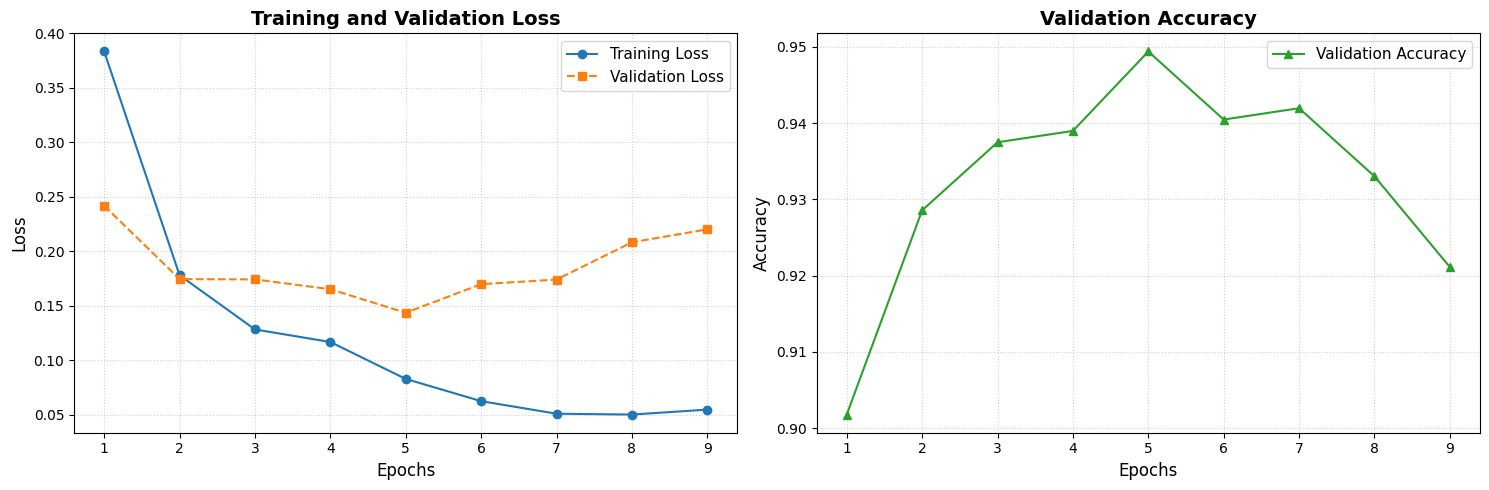

In [ ]:
# ==========================================
# --- 📈 繪製訓練與驗證曲線 (Training Curves) ---
# ==========================================
import matplotlib.pyplot as plt

# 設定畫布大小 (寬 15 吋, 高 5 吋)，並準備左右兩張圖
plt.figure(figsize=(15, 5))
epochs_range = range(1, len(train_loss_history) + 1)

# ----------------- 左邊這張圖：Loss 曲線 -----------------
plt.subplot(1, 2, 1) # (列, 行, 第幾張)
plt.plot(epochs_range, train_loss_history, label='Training Loss', color='#1f77b4', linestyle='-', marker='o')
plt.plot(epochs_range, val_loss_history, label='Validation Loss', color='#ff7f0e', linestyle='--', marker='s')

plt.title('Training and Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6) # 加網格線方便組員對齊數值
plt.xticks(epochs_range) # 強制橫軸只顯示整數的 Epoch
plt.legend(fontsize=11)

# ----------------- 右邊這張圖：Accuracy 曲線 -----------------
plt.subplot(1, 2, 2)
plt.plot(epochs_range, val_acc_history, label='Validation Accuracy', color='#2ca02c', linestyle='-', marker='^')

plt.title('Validation Accuracy', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(epochs_range)
plt.legend(fontsize=11)

# 自動調整佈局避免字體重疊，並秀出圖表
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# --- 💾 保存訓練好的 VideoMAE 模型與處理器 ---
# ==========================================
import os

# 1. 設定你想保存的資料夾名稱
save_directory = "./my_basketball_videomae_model"

# 2. 建立資料夾
os.makedirs(save_directory, exist_ok=True)

# 3. 保存模型本體（權重與設定）
model.save_pretrained(save_directory)

# 4. 保存影像處理器（確保下次解碼影片時的縮放比例一致）
feature_extractor.save_pretrained(save_directory)

print(f"🎉 模型與處理器已成功保存至：{save_directory}")
print("你可以在左側的檔案夾 📁 中看到這個資料夾囉！")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

🎉 模型與處理器已成功保存至：./my_basketball_videomae_model
你可以在左側的檔案夾 📁 中看到這個資料夾囉！


In [ ]:
# ==========================================
# --- ☁️ 將模型整包備份到 Google Drive ---
# ==========================================
from google.colab import drive
import shutil

# 1. 掛載雲端硬碟（如果前面掛載過，這行會自動跳過）
drive.mount('/content/drive')

# 2. 設定你雲端硬碟的目的地路徑（假設存在最外層的 Basketball_Project 資料夾）
# 🌟 你可以自由修改 'Basketball_Project' 成你們組的專案資料夾名稱
destination_drive_path = '/content/drive/MyDrive/Basketball_Project/my_basketball_videomae_model'

# 3. 執行整包複製
try:
    # 如果雲端本來就有舊的，先刪除，避免覆蓋時檔案錯亂
    if os.path.exists(destination_drive_path):
        shutil.rmtree(destination_drive_path)

    shutil.copytree(save_directory, destination_drive_path)
    print(f"🚀 【保險箱同步成功】模型已永久安全儲存在你的雲端硬碟：{destination_drive_path}")
except Exception as e:
    print(f"❌ 備份至雲端硬碟失敗，請確認資料夾路徑是否存在。錯誤訊息: {e}")

ValueError: mount failed

### Google Drive 掛載錯誤說明

您遇到的 `ValueError: mount failed` 錯誤通常表示 Google Colab 在嘗試連接到您的 Google Drive 時遇到問題。這可能是由於以下原因：

*   **暫時性連接問題：** Google Drive 服務或 Colab 環境的短期波動。
*   **認證過期或無效：** 您的 Colab 會話的 Google 認證可能已過期或失效。

**解決方法：**

通常，重新執行掛載 Google Drive 的程式碼（如下一個單元格所示）可以解決此問題。當您執行該單元格時，系統可能會要求您再次進行認證。

如果問題持續存在，請嘗試重新啟動 Colab 執行階段 (Runtime -> Restart runtime)，然後再次執行所有單元格，特別是掛載 Drive 的部分。

In [ ]:
# ==========================================
# --- ☁️ 重新掛載 Google Drive ---
# ==========================================
from google.colab import drive
import shutil
import os

# 1. 掛載雲端硬碟
drive.mount('/content/drive')

# 2. 設定你雲端硬碟的目的地路徑（假設存在最外層的 Basketball_Project 資料夾）
# 🌟 你可以自由修改 'Basketball_Project' 成你們組的專案資料夾名稱
save_directory = "./my_basketball_videomae_model"
destination_drive_path = '/content/drive/MyDrive/Basketball_Project/my_basketball_videomae_model'

# 3. 執行整包複製
try:
    # 如果雲端本來就有舊的，先刪除，避免覆蓋時檔案錯亂
    if os.path.exists(destination_drive_path):
        print(f"偵測到雲端硬碟中存在舊的模型資料夾，正在刪除以進行更新：{destination_drive_path}")
        shutil.rmtree(destination_drive_path)

    shutil.copytree(save_directory, destination_drive_path)
    print(f"🚀 【保險箱同步成功】模型已永久安全儲存在你的雲端硬碟：{destination_drive_path}")
except Exception as e:
    print(f"❌ 備份至雲端硬碟失敗，請確認資料夾路徑是否存在或您的權限。錯誤訊息: {e}")

Mounted at /content/drive
偵測到雲端硬碟中存在舊的模型資料夾，正在刪除以進行更新：/content/drive/MyDrive/Basketball_Project/my_basketball_videomae_model
🚀 【保險箱同步成功】模型已永久安全儲存在你的雲端硬碟：/content/drive/MyDrive/Basketball_Project/my_basketball_videomae_model


In [ ]:
# ==========================================
# --- 🔄 下次開新檔案時：從雲端硬碟載入模型 ---
# ==========================================
import torch
from google.colab import drive
from transformers import VideoMAEImageProcessor, VideoMAEForVideoClassification

# 1. 掛載雲端硬碟
drive.mount('/content/drive')

# 2. 指定模型在雲端硬碟的路徑
model_path = '/content/drive/MyDrive/Basketball_Project/my_basketball_videomae_model'

# 3. 一鍵載入「完全體」模型與影像處理器
print("正在載入你們訓練好的終極模型...")
loaded_processor = VideoMAEImageProcessor.from_pretrained(model_path)
loaded_model = VideoMAEForVideoClassification.from_pretrained(model_path)

# 4. 送上 GPU，準備進行影片預測！
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaded_model.to(device)
loaded_model.eval() # 設為評估模式

print(f"✅ 模型完美載入成功！目前正在 {device} 上待命，可以開始丟新影片給它預測了！")

# 以下為草稿

# 🏀 籃球動作自動化辨識與量化評價系統流程

本專案旨在建立一個從「原始比賽影像」到「個人化訓練報告」的自動化管道。系統分為三個核心階段：事件定位、特徵提取、語義評價。

## 第一階段：事件定位與自動切片 (Event Detection)
**目標：** 在長達 40 分鐘的影片中，精確找出「投籃」、「抄截」等關鍵動作發生的秒數。

選 25-26 NBA 0022500001 - 0022500029 30場 </br>

#### Kaggle pbp2026.csv </br>
https://www.kaggle.com/datasets/szymonjwiak/nba-play-by-play-data-1997-2023?select=pbp2026.csv

#### basketball-video.com
https://basketball-video.com/2025-26?page126




### 1. 全局動作偵測 (Global Action Scanning)
* **模型架構：** 採用 **Video Transformer (如 VideoMAE)** 作為特徵提取核心。
* **滑動視窗策略：**
    * 以 **3 秒** 為一個窗口（Window Size）。
    * 以 **1 秒** 為步長（Stride）進行全片掃描。
* **輸出：** 產出原始動作機率流（Probability Stream），記錄每一秒影片中出現籃球事件的機率。

### 2. 動作密度聚類與分節 (Temporal Clustering)
> **目的：** 解決基層影片無計分板、NBA 影片含廣告的對齊難題。
* **熱度圖生成：** 統計每分鐘偵測到的動作總數。
* **節次識別 (Quarter Detection)：**
    * 利用 **密度閾值法 (Density-based Thresholding)** 濾除動作稀疏的廣告或中場休息片段。
    * 將偵測到的高頻動作區塊自動歸類為 **Quarter 1, 2, 3, 4**。
* **起點校準 ($T_{start}$)：** 捕捉每一節第一個「有效動作」（如跳球、第一次運球）的影片絕對秒數。


### 4. 自動切片與標籤融合 (Auto-Clipping & Labeling)
* **精確過濾：** 僅保留 PBP 中紀錄有案的關鍵事件片段。
* **NMS (非極大值抑制)：** 處理重疊偵測，確保同一個動作（如一次投籃）只被切出一個片段。
* **輸出成果：** * **短片庫：** 數百個 3-5 秒的 `.mp4` 關鍵動作短片。
    * **對照 CSV：** 包含 `Clip_ID`、`Action_Type`、`Shooter`、`Distance`、`Result` 等來自 PBP 的豐富標籤。

## 未來發展




## *第二階段：物理特徵提取與追蹤 (Feature Extraction)
**目標：** 將影像中的動作轉化為可計算的「數位座標」。

### 1. 人體姿態估計 (Pose Estimation)
* **模型選擇：** **YOLOv8-Pose**。
* **任務：** 在第一階段切出的短片中，即時偵測球員的 17 個骨架關鍵點。
* **輸出：** 每一幀的 $x, y$ 座標矩陣。

### 2. 物體追蹤 (Object Tracking)
* **任務：** 追蹤籃球的飛行路徑、球員的移動軌跡。
* **技術：** 使用 ByteTrack 或 BoT-SORT 確保在混亂場景下 ID 不丟失。

### 3. 座標變換 (Coordinate Transformation)
* **單應性矩陣 (Homography)：** 將影片中的傾斜視角平面投影至標準 2D 籃球場平面。
* **數據導出：** 計算 `投籃距離 (Shot Distance)`、`出手高度`、`移動速度`。

In [ ]:
# @title



---

## *第三階段：語義評價與報告生成 (Evaluation & Synthesis)
**目標：** 根據座標數據給出專業建議。

### 1. 時序序列分析 (Sequential Analysis)
* **模型選擇：** **RNN / LSTM** 或 **GRU**。
* **任務：** 讀取連續 60-90 幀的骨架座標流，分析動作的連貫性。
* **評價指標：**
    * **出手穩定度：** 比較 NBA 與基層球員的出手弧度與重心平衡。
    * **防守壓迫：** 計算防守者與進攻者的距離縮減率。

### 2. 數據融合與可視化
* **PBP 關聯：** 將 PBP Log 中的 `Shooter`、`Result` 等資訊與 AI 辨識結果合併。
* **生成報告：**
    * 自動剪輯該場比賽的所有進球精華。
    * 生成個人表現雷達圖（投籃、防守、體能、穩定度）。

---

## 📈 預期成效與技術指標

| 階段 | 關鍵模型 | 預期準確率 (NBA/基層) | 主要輸出 |
| :--- | :--- | :--- | :--- |
| **Stage 1** | Video Transformer | 88% / 82% | 關鍵片段 Timecode |
| **Stage 2** | YOLOv8-Pose | 95% / 90% | 骨架與球軌跡座標 |
| **Stage 3** | RNN / Logic Engine | N/A (定性評價) | 量化評價報告 |

---

## 🚀 部署環境
* **運算硬體：** NVIDIA H100 (80GB VRAM) on Google Colab / Lambda Labs。
* **開發語言：** Python 3.9+。
* **核心框架：** PyTorch, Hugging Face Transformers, Ultralytics (YOLOv8), OpenCV。

# 測錯區

In [ ]:
# @title
# https://basketball-video.com/2025-26?page128

0022500001
https://basketball-video.com/houston-rockets-vs-oklahoma-city-thunder-full-game-replay-october-21-2025-nba
https://ok.ru/videoembed/10622192912982

0022500002
https://basketball-video.com/golden-state-warriors-vs-los-angeles-lakers-full-game-replay-october-21-2025-nba
https://ok.ru/videoembed/10622192847446

0022500003
https://basketball-video.com/cleveland-cavaliers-vs-new-york-knicks-full-game-replay-october-22-2025-nba

0022500004
https://basketball-video.com/san-antonio-spurs-vs-dallas-mavericks-full-game-replay-october-22-2025-nba

0022500005
https://basketball-video.com/oklahoma-city-thunder-vs-indiana-pacers-full-game-replay-october-23-2025-nba

0022500006
https://basketball-video.com/denver-nuggets-vs-golden-state-warriors-full-game-replay-october-23-2025-nba

0022500007
https://basketball-video.com/cleveland-cavaliers-vs-detroit-pistons-full-game-replay-october-27-2025-nba



In [ ]:
# @title
# 這一段是我在伺服器上下載影片的自動腳本
from __future__ import annotations

import re
import subprocess
import sys
from pathlib import Path
import argparse


ROOT = Path(__file__).resolve().parent
VIDEO_MD = ROOT / "video.md"
YTDLP_PYTHONPATH = Path("/private/tmp/yt_dlp_pkg")


def parse_video_rows(markdown_path: Path) -> list[dict[str, str]]:
    lines = markdown_path.read_text(encoding="utf-8").splitlines()
    rows: list[dict[str, str]] = []

    for line in lines:
        if not line.startswith("|"):
            continue

        cols = [part.strip() for part in line.split("|")[1:-1]]
        if len(cols) != 7:
            continue
        if cols[0] in {"#", "---"}:
            continue
        if not re.fullmatch(r"\d+", cols[0]):
            continue

        rows.append(
            {
                "index": cols[0],
                "game_id": cols[1],
                "matchup": cols[2],
                "game_date": cols[3],
                "nba_box_score": cols[4],
                "inferred_basketball_video_url": cols[5],
                "real_video_url": cols[6],
            }
        )

    return rows


def run_download(row: dict[str, str], output_root: Path) -> int:
    game_id = row["game_id"]
    url = row["real_video_url"]
    target_dir = output_root / game_id
    target_dir.mkdir(parents=True, exist_ok=True)

    output_template = str(target_dir / "video.%(ext)s")
    cmd = [
        sys.executable,
        "-m",
        "yt_dlp",
        "--no-playlist",
        "--continue",
        "--no-overwrites",
        "--newline",
        "--downloader",
        "ffmpeg",
        "--write-info-json",
        "--merge-output-format",
        "mp4",
        "--remux-video",
        "mp4",
        "--format",
        "best[height=1080][fps=60]/bestvideo[height=1080][fps=60]+bestaudio",
        "--output",
        output_template,
        url,
    ]

    env = dict(**__import__("os").environ)
    existing_pythonpath = env.get("PYTHONPATH", "")
    env["PYTHONPATH"] = (
        f"{YTDLP_PYTHONPATH}:{existing_pythonpath}"
        if existing_pythonpath
        else str(YTDLP_PYTHONPATH)
    )

    print(f"Downloading {game_id} from {url}")
    completed = subprocess.run(cmd, cwd=output_root, env=env)
    return completed.returncode


def main() -> int:
    parser = argparse.ArgumentParser()
    parser.add_argument(
        "--output-root",
        default=str(ROOT),
        help="Directory where per-game folders will be created.",
    )
    args = parser.parse_args()

    output_root = Path(args.output_root).expanduser().resolve()
    output_root.mkdir(parents=True, exist_ok=True)

    rows = parse_video_rows(VIDEO_MD)

    selected_rows = [
        row
        for row in rows
        if 1 <= int(row["index"]) <= 29 and row["real_video_url"] != "NULL"
    ]

    failures: list[tuple[str, str]] = []

    for row in selected_rows:
        code = run_download(row, output_root)
        if code != 0:
            failures.append((row["game_id"], row["real_video_url"]))

    print()
    print(f"Attempted downloads: {len(selected_rows)}")
    print(f"Failures: {len(failures)}")
    for game_id, url in failures:
        print(f"- {game_id}: {url}")

    return 1 if failures else 0


if __name__ == "__main__":
    raise SystemExit(main())

### 小樣本測試
以 0022500001為例
- Q1st = 10:06 = 606 seconds
- Q2nd = 34:22 = 2062 seconds
- Q3rd = 65:14 = 3914 seconds
- Q4th = 89:00 = 5340 seconds
- OT1st = 121:00 = 7260 seconds
- OT2nd = 137:43 = 8263 seconds

In [ ]:
# @title
# ---------- test_clips.py ----------
## 嘗試自動處理 影片切分 取得訓練集 version 1
import cv2
import os

# --- 1. 設定區 ---
TARGET_GAME_ID = "0022500001"       # 你的目標比賽 ID (可以是字串或數字，依 CSV 格式而定)
VIDEO_PATH = "0022500001.mp4"       # 你的原始影片路徑
ALL_PBP_CSV_PATH = "2026_all_pbp.csv" # 你整年度的 PBP 大表檔案名稱
OUTPUT_DIR = "./test_clips"         # 切片輸出資料夾

if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

# 你手動找出來的各節起點 (單位：秒)
QUARTER_STARTS = {
    1: 606,   # Q1
    2: 2062,  # Q2
    3: 3914,  # Q3
    4: 5340,  # Q4
    5: 7260,  # OT1
    6: 8263   # OT2
}

# --- 2. 輔助函式：將 PBP 的 "MM:SS" 轉為總秒數 ---
def pbp_time_to_seconds(time_str):
    try:
        if pd.isna(time_str): return 0
        minutes, seconds = map(int, str(time_str).split(':'))
        return minutes * 60 + seconds
    except:
        return 0

# --- 3. 讀取年度大表並過濾單場比賽 ---
print("正在讀取年度 PBP 大數據表，請稍候...")
df_all = pd.read_csv(ALL_PBP_CSV_PATH, low_memory=False)

# 強制將 GAME_ID 轉為字串補零，避免格式不一致導致漏掉資料
df_all['GAME_ID'] = df_all['GAME_ID'].astype(str).str.zfill(10)
target_game_str = str(TARGET_GAME_ID).zfill(10)

# 篩選出這場比賽的資料
df = df_all[df_all['GAME_ID'] == target_game_str].copy()
print(f"成功撈出比賽 {TARGET_GAME_ID} 的紀錄，共 {len(df)} 筆事件。")

# --- 4. 篩選投籃事件 ---
# 2026 PBP 通常可以用 EVENTMSGTYPE 判斷：1 是進球 (Make)，2 是不進 (Miss)
# 或者用描述欄位模糊搜尋
if 'EVENTMSGTYPE' in df.columns:
    shot_df = df[df['EVENTMSGTYPE'].isin([1, 2])].copy()
else:
    # 備用方案：如果欄位名稱不同，用文字描述篩選
    desc_cols = [col for col in ['HOMEDESCRIPTION', 'VISITORDESCRIPTION', 'DESCRIPTION'] if col in df.columns]
    condition = pd.Series(False, index=df.index)
    for col in desc_cols:
        condition |= df[col].str.contains('shot|miss|make|layup|jumper|dunk', case=False, na=False)
    shot_df = df[condition].copy()

print(f"在這場比賽中找到 {len(shot_df)} 個投籃事件，開始切片前 5 個進行測試...")

# --- 5. 遍歷並計算時間切片 ---
count = 0
for index, row in shot_df.head(5).iterrows():
    # 讀取節次欄位 (通常叫 PERIOD)
    quarter = int(row['PERIOD'])

    # 讀取比賽鐘時間 (通常叫 PCTIMESTRING)
    pbp_time_str = row['PCTIMESTRING']

    # 算出該節比賽鐘還剩多少秒
    pbp_sec_left = pbp_time_to_seconds(pbp_time_str)

    # 2026年常規賽一節 12 分鐘 (720秒)，延長賽 5 分鐘 (300秒)
    total_quarter_time = 300 if quarter >= 5 else 720

    # 計算該節比賽已經打了多少秒
    game_time_elapsed = total_quarter_time - pbp_sec_left

    # 對齊影片絕對秒數
    t_start = QUARTER_STARTS.get(quarter, 0)
    target_video_second = t_start + game_time_elapsed

    # 設定切片區間：投籃前 2 秒 到 投籃後 1 秒 (共 3 秒)
    # 這裡稍微往左平移 2 秒，確保能抓到出手前的準備動作
    clip_start = target_video_second - 2
    clip_duration = 3

    # 建立輸出的檔案名稱
    output_filename = f"{OUTPUT_DIR}/shot_{count+1}_Q{quarter}_{pbp_time_str.replace(':', '')}.mp4"

    # --- 6. 使用 FFmpeg 進行精確切片 ---
    cmd = f'ffmpeg -ss {clip_start} -t {clip_duration} -i "{VIDEO_PATH}" -c:v libx264 -crf 23 -c:a copy "{output_filename}" -y -loglevel quiet'
    os.system(cmd)

    print(f"事件 {count+1} -> 節次: Q{quarter}, 比賽鐘: {pbp_time_str} -> 影片切片起點: {clip_start}秒")
    count += 1

print("\n測試切片完成！請到 ./test_clips 資料夾檢查那 5 個影片。")

In [ ]:
# @title
# ---------- test_clips_v2_ocr.py ----------
## 嘗試自動處理 影片切分 取得訓練集 version 2 using OCR
from __future__ import annotations

import re
import shutil
import subprocess
import tempfile
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable

import pandas as pd

try:
    import cv2  # type: ignore
except ImportError as exc:  # pragma: no cover
    raise SystemExit(
        "缺少套件 cv2。請先安裝 opencv-python，例如：python3 -m pip install opencv-python"
    ) from exc

try:
    import pytesseract  # type: ignore
except ImportError as exc:  # pragma: no cover
    raise SystemExit(
        "缺少套件 pytesseract。請先安裝，例如：python3 -m pip install pytesseract"
    ) from exc


SCRIPT_DIR = Path(__file__).resolve().parent

TARGET_GAME_ID = "0022500001"
VIDEO_PATH = Path(
    "/Users/tzuen-may/Internal_Admin_Dev/Documents/NCCU課程/1142DTAI/Final/Dataset/Video/NCCU_1142DTAI_Video/0022500001/video.mp4"
)
ALL_PBP_CSV_PATH = Path(
    "/Users/tzuen-may/Internal_Admin_Dev/Documents/NCCU課程/1142DTAI/Final/Dataset/pbp2026.csv"
)
OUTPUT_DIR = SCRIPT_DIR / "test_clips_ocr"
ANCHOR_CSV_PATH = SCRIPT_DIR / f"{TARGET_GAME_ID}_ocr_anchors.csv"
CLIP_MANIFEST_CSV_PATH = SCRIPT_DIR / f"{TARGET_GAME_ID}_ocr_clips.csv"

# 先只切前幾球做測試，確認 OCR 對齊品質。要整場跑時改成 None。
TEST_LIMIT = 5

# 先用偏前的弱標註窗，等 OCR 穩定後再縮。
PRE_ROLL = 8
POST_ROLL = 2
CLIP_DURATION = PRE_ROLL + POST_ROLL

# 影片前面通常有熱身、廣告或主播開場。這個秒數之前不做 OCR，也不抽 non-shot。
GAME_START_VIDEO_SECOND = 600.0

# non-shot 預設抽和 shot 一樣多。若設成整數，就固定抽指定數量。
NON_SHOT_TARGET_COUNT: int | None = None

# 避開 shot 事件的保守區間，避免把實際出手附近誤抽成 non-shot。
NON_SHOT_EXCLUSION_BEFORE_SECONDS = 10.0
NON_SHOT_EXCLUSION_AFTER_SECONDS = 5.0
NON_SHOT_SAMPLE_STRIDE_SECONDS = 2.0

# 每隔幾秒抽一張圖做 OCR。2 秒通常是第一版較穩的平衡。
OCR_SAMPLE_EVERY_N_SECONDS = 5.0

# 測試模式時，不要掃整場影片。先限制 OCR 掃描前幾分鐘，確認流程穩定即可。
OCR_SCAN_WINDOW_SECONDS_FOR_TEST = 900.0

# 每掃描多少個取樣點印一次進度。
OCR_PROGRESS_EVERY_N_SAMPLES = 50

# 錨點品質控制。這些值先保守，目的是降低 OCR 錯讀與回放污染。
MAX_CLOCK_DISTANCE_TO_ACCEPT_SECONDS = 6
MAX_BACKWARD_JUMP_IN_CLOCK_SECONDS = 3
MAX_FORWARD_JUMP_IN_CLOCK_SECONDS = 30

# 這兩個 ROI 需要依你的轉播畫面手動微調。
# 格式是 (x1, y1, x2, y2)，用相對座標 0~1 表示。
# 下面是偏「右下角 scoreboard」的預設值，你很可能要自己調。
# CLOCK_ROI = (0.80, 0.89, 0.92, 0.97)
# PERIOD_ROI = (0.74, 0.89, 0.80, 0.97)
# 修改後的精確 ROI 參數（以你的轉播畫面為準）
# 格式：(x1, y1, x2, y2)

# 比賽鐘 (11:26) -> 位於計分板中間偏左的「上半部」
CLOCK_ROI = (0.46, 0.81, 0.51, 0.85)

# 節次 (1ST) -> 位於計分板中間偏左的「下半部」
PERIOD_ROI = (0.46, 0.85, 0.51, 0.89)

# 如果 tesseract 不是在 PATH 裡，可以指定完整路徑，例如：
# pytesseract.pytesseract.tesseract_cmd = "/opt/homebrew/bin/tesseract"
DEFAULT_TESSERACT_CMD = "/opt/homebrew/bin/tesseract"
if Path(DEFAULT_TESSERACT_CMD).exists():
    pytesseract.pytesseract.tesseract_cmd = DEFAULT_TESSERACT_CMD


def run_tesseract_safe(image, config: str) -> str:
    """
    優先走 pytesseract；若 pyenv 環境下 stderr 解碼炸掉，fallback 到 tesseract CLI。
    """
    if image is None or getattr(image, "size", 0) == 0:
        return ""

    try:
        return pytesseract.image_to_string(image, config=config)
    except UnicodeDecodeError:
        tesseract_cmd = shutil.which(pytesseract.pytesseract.tesseract_cmd) or pytesseract.pytesseract.tesseract_cmd
        with tempfile.TemporaryDirectory() as tmpdir:
            input_path = Path(tmpdir) / "ocr_input.png"
            output_base = Path(tmpdir) / "ocr_output"
            encoded_ok, encoded_buf = cv2.imencode(".png", image)
            if not encoded_ok:
                return ""
            input_path.write_bytes(encoded_buf.tobytes())
            if not input_path.exists() or input_path.stat().st_size == 0:
                return ""
            completed = subprocess.run(
                [tesseract_cmd, str(input_path), str(output_base), *config.split()],
                capture_output=True,
            )
            if completed.returncode != 0:
                return ""

            txt_path = output_base.with_suffix(".txt")
            if not txt_path.exists():
                return ""
            return txt_path.read_text(encoding="utf-8", errors="ignore")


@dataclass
class OcrAnchor:
    video_second: float
    period: int
    clock_text: str
    clock_left_seconds: int


@dataclass
class ClipRecord:
    label: str
    period: int | None
    pbp_clock: str | None
    event_type: str
    event_second: float | None
    clip_start: float
    clip_end: float
    output_path: Path


def pbp_time_to_seconds(clock_str: str) -> int:
    if pd.isna(clock_str):
        return 0

    text = str(clock_str).strip()
    iso_match = re.fullmatch(r"PT(?:(\d+)M)?(?:(\d+(?:\.\d+)?)S)?", text)
    if iso_match:
        minutes = int(iso_match.group(1) or 0)
        seconds = float(iso_match.group(2) or 0)
        return int(round(minutes * 60 + seconds))

    mmss_match = re.fullmatch(r"(\d+):(\d+)", text)
    if mmss_match:
        return int(mmss_match.group(1)) * 60 + int(mmss_match.group(2))

    return 0


def seconds_to_mmss(total_seconds: int) -> str:
    minutes = total_seconds // 60
    seconds = total_seconds % 60
    return f"{minutes:02d}:{seconds:02d}"


def crop_roi(frame, roi: tuple[float, float, float, float]):
    h, w = frame.shape[:2]
    x1, y1, x2, y2 = roi
    return frame[int(y1 * h):int(y2 * h), int(x1 * w):int(x2 * w)]


def preprocess_for_ocr(image):
    if image is None or getattr(image, "size", 0) == 0:
        return None
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    enlarged = cv2.resize(gray, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
    blurred = cv2.GaussianBlur(enlarged, (3, 3), 0)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return thresh


def ocr_clock_text(clock_img) -> str | None:
    processed = preprocess_for_ocr(clock_img)
    if processed is None:
        return None
    text = run_tesseract_safe(
        processed,
        config="--psm 7 -c tessedit_char_whitelist=0123456789:",
    )
    text = re.sub(r"[^0-9:]", "", text)

    match = re.search(r"(\d{1,2}:\d{2})", text)
    return match.group(1) if match else None


def ocr_period_value(period_img) -> int | None:
    processed = preprocess_for_ocr(period_img)
    if processed is None:
        return None
    text = run_tesseract_safe(
        processed,
        config="--psm 7 -c tessedit_char_whitelist=123456QOTqot",
    )
    cleaned = re.sub(r"[^0-9A-Za-z]", "", text).upper()

    # 常見樣式：Q1, 1ST, OT, 2OT
    if "OT" in cleaned and cleaned[:1].isdigit():
        # 2OT -> 視為第 6 節，1OT -> 第 5 節
        leading = int(cleaned[:1])
        return 4 + leading
    if cleaned == "OT":
        return 5

    digit_match = re.search(r"([1-6])", cleaned)
    if digit_match:
        return int(digit_match.group(1))

    return None


def extract_ocr_anchors(video_path: Path) -> list[OcrAnchor]:
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"無法開啟影片：{video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 59.94
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    step_frames = max(int(round(fps * OCR_SAMPLE_EVERY_N_SECONDS)), 1)
    start_frame = max(int(round(GAME_START_VIDEO_SECOND * fps)), 0)

    if TEST_LIMIT is not None:
        scan_end_second = GAME_START_VIDEO_SECOND + OCR_SCAN_WINDOW_SECONDS_FOR_TEST
    else:
        scan_end_second = total_frames / fps
    end_frame = min(int(round(scan_end_second * fps)), total_frames)

    anchors: list[OcrAnchor] = []
    frame_index = start_frame
    sample_count = 0

    if start_frame > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

    while frame_index < end_frame:
        ok, frame = cap.read()
        if not ok:
            break

        video_second = frame_index / fps
        clock_img = crop_roi(frame, CLOCK_ROI)
        period_img = crop_roi(frame, PERIOD_ROI)

        clock_text = ocr_clock_text(clock_img)
        period = ocr_period_value(period_img)

        if clock_text and period is not None:
            anchors.append(
                OcrAnchor(
                    video_second=video_second,
                    period=period,
                    clock_text=clock_text,
                    clock_left_seconds=pbp_time_to_seconds(clock_text),
                )
            )

        sample_count += 1
        if sample_count % OCR_PROGRESS_EVERY_N_SAMPLES == 0:
            print(
                f"OCR 掃描進度: sample={sample_count}, "
                f"video_second={video_second:.1f}, anchors={len(anchors)}"
            )

        # 順序讀取，跳過中間幀，避免反覆 seek 整支影片。
        skip_frames = step_frames - 1
        for _ in range(skip_frames):
            ok = cap.grab()
            if not ok:
                break
        frame_index += step_frames

    cap.release()
    return deduplicate_anchors(anchors)


def deduplicate_anchors(anchors: list[OcrAnchor]) -> list[OcrAnchor]:
    deduped: list[OcrAnchor] = []
    seen: set[tuple[int, int, int]] = set()

    for anchor in anchors:
        key = (round(anchor.video_second), anchor.period, anchor.clock_left_seconds)
        if key in seen:
            continue
        seen.add(key)
        deduped.append(anchor)

    return deduped


def max_clock_seconds_for_period(period: int) -> int:
    return 300 if period >= 5 else 720


def is_plausible_anchor(anchor: OcrAnchor) -> bool:
    return 0 <= anchor.clock_left_seconds <= max_clock_seconds_for_period(anchor.period)


def filter_anchor_sequence(anchors: list[OcrAnchor]) -> list[OcrAnchor]:
    """
    依 period 分組後，沿著影片時間遞增過濾明顯不合理的 OCR 錨點。

    目標不是完美重建時間軸，而是先移除：
    - OCR 錯讀成不可能的 clock
    - 回放 / 舊畫面導致 clock 突然大幅回跳
    """
    if not anchors:
        return []

    grouped: dict[int, list[OcrAnchor]] = {}
    for anchor in anchors:
        if not is_plausible_anchor(anchor):
            continue
        grouped.setdefault(anchor.period, []).append(anchor)

    filtered: list[OcrAnchor] = []
    for period, group in grouped.items():
        ordered = sorted(group, key=lambda item: item.video_second)
        kept: list[OcrAnchor] = []

        for anchor in ordered:
            if not kept:
                kept.append(anchor)
                continue

            prev = kept[-1]
            delta_clock = anchor.clock_left_seconds - prev.clock_left_seconds

            # 同節正常情況下，clock 應該遞減或短暫持平。
            # 若突然增加很多秒，通常是 OCR 誤讀或回放舊畫面。
            if delta_clock > MAX_BACKWARD_JUMP_IN_CLOCK_SECONDS:
                continue

            # 若突然下降太多，也先視為不可信。
            if delta_clock < -MAX_FORWARD_JUMP_IN_CLOCK_SECONDS:
                continue

            kept.append(anchor)

        filtered.extend(kept)

    return sorted(filtered, key=lambda item: item.video_second)


def get_video_duration_seconds(video_path: Path) -> float:
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"無法開啟影片：{video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 59.94
    total_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0
    cap.release()
    return float(total_frames / fps) if fps > 0 else 0.0


def save_anchors_csv(anchors: list[OcrAnchor], csv_path: Path) -> None:
    rows = [
        {
            "video_second": round(anchor.video_second, 3),
            "period": anchor.period,
            "clock_text": anchor.clock_text,
            "clock_left_seconds": anchor.clock_left_seconds,
        }
        for anchor in anchors
    ]
    pd.DataFrame(rows).to_csv(csv_path, index=False)


def choose_best_anchor(
    anchors: list[OcrAnchor],
    period: int,
    clock_left_seconds: int,
) -> OcrAnchor | None:
    same_period = sorted(
        [anchor for anchor in anchors if anchor.period == period],
        key=lambda anchor: anchor.video_second,
    )
    if not same_period:
        return None

    exact_matches = [anchor for anchor in same_period if anchor.clock_left_seconds == clock_left_seconds]
    if exact_matches:
        return exact_matches[0]

    best = min(
        same_period,
        key=lambda anchor: abs(anchor.clock_left_seconds - clock_left_seconds),
    )
    if abs(best.clock_left_seconds - clock_left_seconds) > MAX_CLOCK_DISTANCE_TO_ACCEPT_SECONDS:
        return None

    return best


def estimate_video_second(anchor: OcrAnchor, event_clock_left_seconds: int) -> float:
    # 比賽剩餘時間減少，影片時間應增加。
    delta_seconds = anchor.clock_left_seconds - event_clock_left_seconds
    return anchor.video_second + delta_seconds


def build_ffmpeg_command(
    video_path: Path,
    clip_start: float,
    clip_duration: float,
    output_path: Path,
) -> list[str]:
    return [
        "ffmpeg",
        "-y",
        "-ss",
        str(max(clip_start, 0)),
        "-t",
        str(clip_duration),
        "-i",
        str(video_path),
        "-c:v",
        "libx264",
        "-crf",
        "23",
        "-c:a",
        "aac",
        str(output_path),
    ]


def sanitize_label_text(text: str) -> str:
    return re.sub(r"[^0-9A-Za-z_-]+", "_", text.strip()).strip("_") or "unknown"


def load_pbp_shots(csv_path: Path, game_id: str) -> pd.DataFrame:
    df_all = pd.read_csv(csv_path, low_memory=False)
    df_all["gameid"] = df_all["gameid"].astype(str).str.zfill(10)
    target_game_str = str(game_id).zfill(10)

    df = df_all[df_all["gameid"] == target_game_str].copy()
    if "type" not in df.columns:
        raise KeyError("PBP 資料缺少 'type' 欄位，無法判斷投籃事件。")

    shot_df = df[df["type"].isin({"Made Shot", "Missed Shot"})].copy()
    return shot_df


def write_clip_manifest(records: Iterable[ClipRecord], csv_path: Path) -> None:
    rows = [
        {
            "label": record.label,
            "period": record.period,
            "pbp_clock": record.pbp_clock,
            "event_type": record.event_type,
            "event_second": round(record.event_second, 3) if record.event_second is not None else None,
            "clip_start": round(record.clip_start, 3),
            "clip_end": round(record.clip_end, 3),
            "clip_duration": round(record.clip_end - record.clip_start, 3),
            "output_path": str(record.output_path),
        }
        for record in records
    ]
    pd.DataFrame(rows).to_csv(csv_path, index=False)


def merge_intervals(intervals: list[tuple[float, float]]) -> list[tuple[float, float]]:
    if not intervals:
        return []

    sorted_intervals = sorted(intervals, key=lambda item: item[0])
    merged = [sorted_intervals[0]]

    for start, end in sorted_intervals[1:]:
        prev_start, prev_end = merged[-1]
        if start <= prev_end:
            merged[-1] = (prev_start, max(prev_end, end))
        else:
            merged.append((start, end))

    return merged


def invert_intervals(
    blocked_intervals: list[tuple[float, float]],
    range_start: float,
    range_end: float,
) -> list[tuple[float, float]]:
    if range_end <= range_start:
        return []

    free_intervals: list[tuple[float, float]] = []
    cursor = range_start

    for start, end in blocked_intervals:
        clipped_start = max(start, range_start)
        clipped_end = min(end, range_end)
        if clipped_end <= clipped_start:
            continue
        if clipped_start > cursor:
            free_intervals.append((cursor, clipped_start))
        cursor = max(cursor, clipped_end)

    if cursor < range_end:
        free_intervals.append((cursor, range_end))

    return free_intervals


def build_non_shot_records(
    shot_records: list[ClipRecord],
    video_duration_seconds: float,
) -> list[ClipRecord]:
    blocked_intervals = merge_intervals(
        [
            (
                max((record.event_second or 0.0) - NON_SHOT_EXCLUSION_BEFORE_SECONDS, GAME_START_VIDEO_SECOND),
                min((record.event_second or 0.0) + NON_SHOT_EXCLUSION_AFTER_SECONDS, video_duration_seconds),
            )
            for record in shot_records
            if record.event_second is not None
        ]
    )

    free_intervals = invert_intervals(
        blocked_intervals=blocked_intervals,
        range_start=GAME_START_VIDEO_SECOND,
        range_end=max(video_duration_seconds - CLIP_DURATION, GAME_START_VIDEO_SECOND),
    )

    records: list[ClipRecord] = []
    non_shot_dir = OUTPUT_DIR / "non-shot"
    non_shot_dir.mkdir(parents=True, exist_ok=True)

    candidate_index = 1
    for free_start, free_end in free_intervals:
        clip_start = free_start
        while clip_start + CLIP_DURATION <= free_end:
            clip_end = clip_start + CLIP_DURATION
            output_path = non_shot_dir / f"non-shot_{candidate_index:04d}.mp4"
            records.append(
                ClipRecord(
                    label="non-shot",
                    period=None,
                    pbp_clock=None,
                    event_type="non-shot",
                    event_second=clip_start + (CLIP_DURATION / 2),
                    clip_start=clip_start,
                    clip_end=clip_end,
                    output_path=output_path,
                )
            )
            candidate_index += 1
            clip_start += NON_SHOT_SAMPLE_STRIDE_SECONDS

    if NON_SHOT_TARGET_COUNT is None:
        target_count = len(shot_records)
    else:
        target_count = min(NON_SHOT_TARGET_COUNT, len(records))

    return records[:target_count]


def main() -> int:
    start_time = time.time()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    if not VIDEO_PATH.exists():
        raise FileNotFoundError(f"找不到影片：{VIDEO_PATH}")
    if not ALL_PBP_CSV_PATH.exists():
        raise FileNotFoundError(f"找不到 PBP CSV：{ALL_PBP_CSV_PATH}")

    print("正在從 scoreboard 做 OCR 抽樣，建立影片時間錨點...")
    anchors = extract_ocr_anchors(VIDEO_PATH)
    raw_anchor_count = len(anchors)
    anchors = filter_anchor_sequence(anchors)
    print(f"OCR 成功抓到 {raw_anchor_count} 個錨點，過濾後保留 {len(anchors)} 個。")

    if not anchors:
        raise RuntimeError("沒有抓到任何 OCR 錨點。請先調整 CLOCK_ROI / PERIOD_ROI。")

    save_anchors_csv(anchors, ANCHOR_CSV_PATH)
    print(f"已輸出 OCR 錨點表：{ANCHOR_CSV_PATH}")

    shot_df = load_pbp_shots(ALL_PBP_CSV_PATH, TARGET_GAME_ID)
    print(f"這場比賽共有 {len(shot_df)} 個投籃事件。")

    selected_df = shot_df.head(TEST_LIMIT) if TEST_LIMIT is not None else shot_df
    success_count = 0
    shot_records: list[ClipRecord] = []
    shot_output_dir = OUTPUT_DIR / "shot"
    shot_output_dir.mkdir(parents=True, exist_ok=True)

    for idx, (_, row) in enumerate(selected_df.iterrows(), start=1):
        period = int(row["period"])
        pbp_time_str = str(row["clock"])
        event_type = str(row["type"])
        event_clock_left_seconds = pbp_time_to_seconds(pbp_time_str)

        anchor = choose_best_anchor(anchors, period, event_clock_left_seconds)
        if anchor is None:
            print(f"❌ 事件 {idx} 失敗 -> 找不到 Q{period} 的 OCR 錨點")
            continue

        estimated_event_second = estimate_video_second(anchor, event_clock_left_seconds)
        clip_start = max(estimated_event_second - PRE_ROLL, 0)
        clip_end = clip_start + CLIP_DURATION

        time_label = re.sub(r"[^0-9A-Za-z]+", "", pbp_time_str)
        fine_label = "shot-made" if event_type == "Made Shot" else "shot-missed"
        output_filename = shot_output_dir / f"{fine_label}_{idx:04d}_Q{period}_{time_label}.mp4"

        cmd = build_ffmpeg_command(
            video_path=VIDEO_PATH,
            clip_start=clip_start,
            clip_duration=CLIP_DURATION,
            output_path=output_filename,
        )
        completed = subprocess.run(cmd, capture_output=True, text=True)

        if completed.returncode == 0 and output_filename.exists() and output_filename.stat().st_size > 0:
            print(
                f"✅ 事件 {idx} 成功 -> Q{period} {pbp_time_str} "
                f"-> anchor={anchor.clock_text}@{anchor.video_second:.1f}s "
                f"-> event≈{estimated_event_second:.1f}s "
                f"-> clip_start={clip_start:.1f}s"
            )
            shot_records.append(
                ClipRecord(
                    label="shot",
                    period=period,
                    pbp_clock=pbp_time_str,
                    event_type=fine_label,
                    event_second=estimated_event_second,
                    clip_start=clip_start,
                    clip_end=clip_end,
                    output_path=output_filename,
                )
            )
            success_count += 1
        else:
            print(f"❌ 事件 {idx} 失敗 -> ffmpeg 未成功輸出")
            if completed.stderr:
                print(completed.stderr.strip())

    video_duration_seconds = get_video_duration_seconds(VIDEO_PATH)
    non_shot_records = build_non_shot_records(shot_records, video_duration_seconds)
    non_shot_success_count = 0

    for idx, record in enumerate(non_shot_records, start=1):
        cmd = build_ffmpeg_command(
            video_path=VIDEO_PATH,
            clip_start=record.clip_start,
            clip_duration=CLIP_DURATION,
            output_path=record.output_path,
        )
        completed = subprocess.run(cmd, capture_output=True, text=True)
        if completed.returncode == 0 and record.output_path.exists() and record.output_path.stat().st_size > 0:
            print(
                f"✅ non-shot {idx} 成功 -> "
                f"event≈{record.event_second:.1f}s -> clip_start={record.clip_start:.1f}s"
            )
            non_shot_success_count += 1
        else:
            print(f"❌ non-shot {idx} 失敗 -> ffmpeg 未成功輸出")
            if completed.stderr:
                print(completed.stderr.strip())

    all_records = shot_records + non_shot_records
    write_clip_manifest(all_records, CLIP_MANIFEST_CSV_PATH)

    end_time = time.time()
    print()
    print(f"🎉 OCR 切片完成，shot 成功 {success_count} / {len(selected_df)}。")
    print(f"🎉 non-shot 成功 {non_shot_success_count} / {len(non_shot_records)}。")
    print(f"輸出資料夾：{OUTPUT_DIR}")
    print(f"clip manifest：{CLIP_MANIFEST_CSV_PATH}")
    print(f"總耗時：{end_time - start_time:.2f} 秒")
    print("如果錨點很少或時間亂跳，先調整 CLOCK_ROI / PERIOD_ROI。")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

## Kaggle Basketball-51 測試

>> 缺點 沒有負樣本

In [ ]:
# @title
import kagglehub

# 下載您提供的 EBC 測試資料集
# 這將建立一個目錄並回傳其路徑
path = kagglehub.dataset_download("donkeyjo6rmp4/2026-dtai-ebc-group-new")

print("資料集檔案路徑:", path)

KaggleApiHTTPError: 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.

### 載入並檢查 Kaggle 資料集

首先，我們來看看 Kaggle 下載的資料集裡面有哪些檔案，這將幫助我們找到 Play-by-Play (PBP) 的詳細數據。


In [ ]:
# @title
# import os

# # 假設 Kaggle 資料集下載到 path 變數所指向的路徑
# # path 變數來自於上一個下載 Kaggle 資料集的程式碼區塊

# if 'path' in locals() and os.path.isdir(path):
#     print(f"Kaggle dataset files are located at: {path}")
#     print("Listing contents:")
#     for root, dirs, files in os.walk(path):
#         for name in files:
#             print(os.path.join(root, name))
# else:
#     print("Error: The 'path' variable from Kaggle download is not defined or is not a directory.")
#     print("Please ensure the Kaggle download cell was executed successfully.")
#     # Fallback for common pbp file name if 'path' is not available or if the user manually placed the file
#     print("Attempting to find 'pbp.csv' in the current directory as a fallback...")
#     if os.path.exists('pbp.csv'):
#         print("Found 'pbp.csv' in the current directory.")
#         path = '.' # Set path to current directory if pbp.csv is there


Error: The 'path' variable from Kaggle download is not defined or is not a directory.
Please ensure the Kaggle download cell was executed successfully.
Attempting to find 'pbp.csv' in the current directory as a fallback...


根據 Kaggle 數據集內容，我們通常會找到一個包含 Play-by-Play (PBP) 數據的 CSV 檔案，例如 `pbp.csv` 或類似名稱。我們將使用 `pandas` 載入這個檔案，並篩選出投籃事件。

接下來，我們將把投籃事件的標籤轉換成 `0`（未命中）和 `1`（命中），這對於後續的機器學習模型訓練非常重要。


In [ ]:
# @title
# import pandas as pd

# # 假設 pbp.csv 是你需要的檔案，並且位於 Kaggle 下載的路徑或當前目錄
# # 你可能需要根據實際的檔案名稱和路徑進行調整

# pbp_file_path = os.path.join(path, 'pbp.csv') # Adjust 'pbp.csv' if your file has a different name

# if not os.path.exists(pbp_file_path):
#     print(f"Error: PBP file not found at {pbp_file_path}. Please check the file name and path.")
#     # Attempt a common alternative if pbp.csv isn't found in the designated path
#     pbp_file_path = 'pbp2026.csv' # As mentioned in a previous markdown cell
#     if not os.path.exists(pbp_file_path):
#         print(f"Error: Also could not find {pbp_file_path}. Please ensure your PBP data file is correctly named and located.")
#         raise FileNotFoundError("PBP data file not found.")
#     else:
#         print(f"Using fallback PBP file: {pbp_file_path}")

# try:
#     df_pbp = pd.read_csv(pbp_file_path, low_memory=False)
#     print(f"Successfully loaded PBP data from {pbp_file_path}. Shape: {df_pbp.shape}")
#     display(df_pbp.head())
# except Exception as e:
#     print(f"Error loading PBP file: {e}")

# # 篩選投籃事件並轉換標籤
# # 根據先前的程式碼邏輯 (cell 1jpngrMeJzqh)，EVENTMSGTYPE=1 是命中，2 是未命中

# if 'EVENTMSGTYPE' in df_pbp.columns:
#     # 篩選出投籃事件 (EVENTMSGTYPE 1: Make, 2: Miss)
#     shot_events_df = df_pbp[df_pbp['EVENTMSGTYPE'].isin([1, 2])].copy()

#     # 將標籤轉換為 (0, 1) 格式
#     # 1 (Make) -> 1
#     # 2 (Miss) -> 0
#     shot_events_df['shot_outcome_label'] = shot_events_df['EVENTMSGTYPE'].map({1: 1, 2: 0})

#     print(f"\nTotal shot events identified: {len(shot_events_df)}")
#     print("First 5 shot events with new labels:")
#     display(shot_events_df[['EVENTMSGTYPE', 'shot_outcome_label', 'HOMEDESCRIPTION', 'VISITORDESCRIPTION']].head())
# else:
#     print("Error: 'EVENTMSGTYPE' column not found in PBP data. Cannot automatically label shots.")
#     print("Please inspect the PBP data and provide the correct column for shot outcomes.")



NameError: name 'path' is not defined

### 檢查 `basketball-51-dataset` 內容並處理標籤

根據您的澄清，我們將專注於 `basketball-51-dataset`。首先，我們將再次列出此資料集的內容，以確保找到包含影片檔案和標籤的結構。然後，我們將載入標籤資訊，並將其轉換為 `0`（未命中）和 `1`（命中）的二元格式。


In [ ]:
# @title
import os

# 確保 path 變數已定義 (由 kagglehub.dataset_download 提供)
if 'path' in locals() and os.path.isdir(path):
    # The actual dataset content is often nested in a subdirectory after extraction
    # We need to find the base directory containing the label folders (e.g., '2p0', '2p1')
    base_dataset_path = None
    for item in os.listdir(path):
        potential_base_path = os.path.join(path, item)
        if os.path.isdir(potential_base_path) and 'Basketball_51 dataset' in item:
            base_dataset_path = potential_base_path
            break

    if base_dataset_path is None:
        print(f"Error: Could not find the 'Basketball_51 dataset' subdirectory within {path}.")
        raise ValueError("Dataset base directory not found.")

    print(f"Kaggle dataset files are located at: {path}")
    print(f"Processing videos from base directory: {base_dataset_path}")
    print("Listing contents of the 'basketball-51-dataset':")
    dataset_files = []
    for root, dirs, files in os.walk(base_dataset_path):
        for name in files:
            file_path = os.path.join(root, name)
            dataset_files.append(file_path)
            # print(f"- {file_path}") # Commenting out to reduce verbose output
    if not dataset_files:
        print("No files found in the dataset directory. Please check the downloaded dataset structure.")
else:
    print("Error: The 'path' variable from Kaggle download is not defined or is not a directory. Please run the Kaggle download cell first.")
    # Exit or handle the error appropriately if path is crucial and not set
    raise ValueError("'path' variable not set. Kaggle dataset download is required.")

# 根據資料集說明，通常會有一個 CSV 或文字檔案包含標籤資訊
# 我們將搜尋類似 'labels.csv', 'annotations.txt' 或根據觀察到的檔案結構進行調整
# 假設標籤檔案是 'labels.csv' 或是根據資料夾名稱來推斷 (例如每個子資料夾代表一個類別)

# 為了處理，我們先假設標籤可以直接從資料夾結構或一個特定檔案獲取
# 如果沒有明確的標籤檔案，我們可能需要手動創建一個映射

# 鑑於 'basketball-51-dataset' 的典型結構，影片通常會以資料夾分類
# 例如: 2p0/, 2p1/, etc.
# 我們將嘗試列出這些頂層的分類資料夾

label_dirs = []
for item in os.listdir(base_dataset_path):
    item_path = os.path.join(base_dataset_path, item)
    if os.path.isdir(item_path):
        label_dirs.append(item)

print(f"\nDetected potential label categories (directories): {label_dirs}")

# 根據資料集描述中的類別名稱，建立一個從原始標籤到獨立整數的映射
# 原始標籤: Two point miss(2p0), Two point make(2p1), Three point miss(3p0), Three point make(3p1), Free throw miss(ft0), Free throw make(ft1), Mid range shot miss(mp0), Mid-range shot make(mp1).

# 為每個原始類別分配一個唯一的整數標籤
unique_labels = sorted(list(set(label_dirs))) # 確保順序一致
label_mapping = {label: i for i, label in enumerate(unique_labels)}

print("\nMulti-class label mapping created:")
for original, class_id in label_mapping.items():
    print(f"  '{original}' -> {class_id}")

# 接下來，你需要一個方法來遍歷影片檔案，並根據其資料夾或命名規則應用此標籤
# 這裡示範如何構建一個簡單的 'filepath -> label' 列表

video_data = []
for label_folder in label_dirs:
    if label_folder in label_mapping:
        class_label = label_mapping[label_folder]
        folder_path = os.path.join(base_dataset_path, label_folder)
        for video_file in os.listdir(folder_path):
            if video_file.endswith(('.mp4', '.avi', '.mov')):
                video_filepath = os.path.join(folder_path, video_file)
                video_data.append({
                    'filepath': video_filepath,
                    'original_label': label_folder,
                    'class_label': class_label # 更改為 class_label 以區分二元標籤
                })
    else:
        print(f"Warning: Folder '{label_folder}' does not have a defined mapping. Skipping.")

print(f"\nFound {len(video_data)} video clips with assigned multi-class labels.")
print("First 5 video data entries:")
for i, entry in enumerate(video_data[:min(5, len(video_data))]): # Added min(5, len(video_data)) to handle cases with fewer than 5 videos
    print(f"  {i+1}. File: {os.path.basename(entry['filepath'])}, Original Label: {entry['original_label']}, Class Label: {entry['class_label']}")

# 這 'video_data' 列表現在包含了每個影片的檔案路徑及其對應的類別標籤，
# 可以用來建立 Dataset 和 DataLoader 進行模型訓練。


Kaggle dataset files are located at: /root/.cache/kagglehub/datasets/sarbagyashakya/basketball-51-dataset/versions/1
Processing videos from base directory: /root/.cache/kagglehub/datasets/sarbagyashakya/basketball-51-dataset/versions/1/Basketball_51 dataset
Listing contents of the 'basketball-51-dataset':

Detected potential label categories (directories): ['3p0', 'mp1', 'ft1', 'ft0', '2p1', '3p1', 'mp0', '2p0']

Multi-class label mapping created:
  '2p0' -> 0
  '2p1' -> 1
  '3p0' -> 2
  '3p1' -> 3
  'ft0' -> 4
  'ft1' -> 5
  'mp0' -> 6
  'mp1' -> 7

Found 10311 video clips with assigned multi-class labels.
First 5 video data entries:
  1. File: 3p0_v111_000702_x264.mp4, Original Label: 3p0, Class Label: 2
  2. File: 3p0_v174_003814_x264.mp4, Original Label: 3p0, Class Label: 2
  3. File: 3p0_v162_003656_x264.mp4, Original Label: 3p0, Class Label: 2
  4. File: 3p0_v146_001026_x264.mp4, Original Label: 3p0, Class Label: 2
  5. File: 3p0_v108_003331_x264.mp4, Original Label: 3p0, Class L

### 訓練 Video Transformer 模型

我們將使用準備好的 `video_data` 列表來訓練一個 Video Transformer 模型。首先，我們需要安裝必要的函式庫。


In [ ]:
# @title
# 安裝必要的函式庫
!pip install transformers accelerate decord torchvision tqdm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 139.9 MB/s eta 0:00:00


In [ ]:
# @title
# 升級 transformers 函式庫以確保兼容性
!pip install --upgrade transformers -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 148.5 MB/s eta 0:00:00


### 1. 定義自定義影片資料集 (Custom Video Dataset)

為了有效地訓練 Video Transformer，我們需要一個能夠載入影片、抽取影格並應用預處理轉換的資料集類別。

- **VideoLoader**：處理影片讀取和影格抽取。
- **transforms**：對抽取出的影格進行縮放、正規化等操作，使其符合模型輸入要求。


In [ ]:
# @title
import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
import decord
import numpy as np
import random
from tqdm.notebook import tqdm

# 設定 decord 影片讀取器，避免 OOM 錯誤
decord.bridge.set_bridge('torch')

class BasketballVideoDataset(Dataset):
    def __init__(self, video_data, processor, max_frames=16, frame_interval=4):
        self.video_data = video_data
        self.processor = processor
        self.max_frames = max_frames
        self.frame_interval = frame_interval

    def __len__(self):
        return len(self.video_data)

    def __getitem__(self, idx):
        video_info = self.video_data[idx]
        video_path = video_info['filepath']
        label = video_info['class_label'] # 使用 class_label

        try:
            vr = decord.VideoReader(video_path)
            total_frames = len(vr)

            # 如果影片幀數太少，則可能無法抽取足夠的幀，這裡可以選擇跳過或重複幀
            if total_frames == 0:
                raise ValueError(f"Video file has 0 frames: {video_path}")

            # 隨機抽取起始幀，確保可以抽取 max_frames * frame_interval 這麼多的幀
            if total_frames < self.max_frames * self.frame_interval:
                # 如果影片太短，則重複採樣或只取所有幀
                indices = np.linspace(0, total_frames - 1, self.max_frames, dtype=int)
            else:
                start_frame = random.randint(0, total_frames - (self.max_frames * self.frame_interval) - 1)
                indices = np.arange(start_frame, start_frame + self.max_frames * self.frame_interval, self.frame_interval)

            frames = vr.get_batch(indices).permute(0, 3, 1, 2) # (T, H, W, C) -> (T, C, H, W)
            # 將幀轉換為浮點數並正規化到 [0, 1]
            frames = frames.float() / 255.0

            # 確保幀數匹配 max_frames
            if frames.shape[0] > self.max_frames:
                frames = frames[:self.max_frames]
            elif frames.shape[0] < self.max_frames:
                # 如果幀數不足，則進行填充（例如重複最後一幀）
                padding = self.max_frames - frames.shape[0]
                frames = torch.cat([frames, frames[-1].unsqueeze(0).repeat(padding, 1, 1, 1)], dim=0)

            # 應用預處理器
            # 注意: VideoMAE 的 processor 通常期望一個 'pixel_values' 鍵
            # 我們可以將預處理步驟放在這裡，或者讓 processor 處理原始幀
            # 這裡假定 processor 可以處理一個 batch 的幀
            inputs = self.processor(list(frames), return_tensors="pt")

            # 將 Batch 維度從 [1, num_frames, num_channels, height, width] 調整為 [num_frames, num_channels, height, width]
            inputs["pixel_values"] = inputs["pixel_values"].squeeze(0)

            return {
                "pixel_values": inputs["pixel_values"],
                "labels": torch.tensor(label, dtype=torch.long)
            }
        except Exception as e:
            print(f"Error processing video {video_path}: {e}")
            # 返回一個空的或預設的張量，或重新取樣
            # 這裡返回一個空的，讓 DataLoader 的 collate_fn 處理
            return None

# 設定 VideoMAE 處理器
from transformers import VideoMAEImageProcessor, VideoMAEForVideoClassification

# 載入預訓練的特徵提取器
# 我們需要一個針對分類任務的檢查點
model_name = "MCG-NJU/videomae-base-finetuned-kinetics"
feature_extractor = VideoMAEImageProcessor.from_pretrained(model_name)

# 創建資料集和資料載入器
# max_frames 和 frame_interval 可以根據影片長度和計算資源調整
# 這裡先使用預設值
batch_size = 8 # 可以根據你的 GPU 記憶體調整

# 假設 video_data 已經被正確地從上一個單元格的執行中填充
if 'video_data' not in locals() or not video_data:
    raise ValueError("video_data is not defined or is empty. Please ensure the previous data loading and processing cell ran successfully.")

# 過濾掉處理失敗的 None 項目
filtered_video_data = [item for item in video_data if item is not None]

# 拆分訓練集和驗證集 (70/30 拆分)
total_size = len(filtered_video_data)
train_size = int(0.7 * total_size)
val_size = total_size - train_size

# 確保數據集不為空，且驗證集至少有一個樣本
if total_size == 0:
    raise ValueError("No valid video data available after filtering. Cannot create datasets.")
if val_size == 0 and total_size > 0: # 如果總數據量小，確保至少有一個驗證樣本
    train_size = total_size - 1
    val_size = 1

print(f"總影片數量: {total_size}")
print(f"訓練集數量: {train_size}")
print(f"驗證集數量: {val_size}")

train_subset, val_subset = random_split(filtered_video_data, [train_size, val_size])

train_dataset = BasketballVideoDataset(list(train_subset), feature_extractor)
val_dataset = BasketballVideoDataset(list(val_subset), feature_extractor)

# 我們需要定義一個 collate_fn 來處理每個批次的數據
def collate_fn(batch):
    batch = [item for item in batch if item is not None]
    if not batch:
        return None

    pixel_values = torch.stack([x['pixel_values'] for x in batch])
    labels = torch.stack([x['labels'] for x in batch])

    return {'pixel_values': pixel_values, 'labels': labels}

train_dataloader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print(f"\n訓練資料集大小: {len(train_dataset)}")
print(f"驗證資料集大小: {len(val_dataset)}")
print(f"每個 Batch 大小: {batch_size}")

# 測試一個批次
for batch in train_dataloader:
    if batch is not None:
        print("成功載入一個批次的數據：")
        print(f"  pixel_values shape: {batch['pixel_values'].shape}")
        print(f"  labels shape: {batch['labels'].shape}")
    else:
        print("未能載入批次數據 (可能由於影片處理錯誤)")
    break


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

總影片數量: 10311
訓練集數量: 7217
驗證集數量: 3094

訓練資料集大小: 7217
驗證資料集大小: 3094
每個 Batch 大小: 8
成功載入一個批次的數據：
  pixel_values shape: torch.Size([8, 16, 3, 224, 224])
  labels shape: torch.Size([8])


### 2. 初始化模型、損失函數和優化器

我們將載入預訓練的 VideoMAE 模型，並為我們的二元分類任務 (`0` 代表未命中，`1` 代表命中) 調整輸出層。接著，我們設定交叉熵損失函數 (`CrossEntropyLoss`) 和 AdamW 優化器 (`AdamW`)。

In [ ]:
# @title
from transformers import VideoMAEForVideoClassification
from torch.optim import AdamW

# 這裡的 num_labels 應該根據您的實際標籤數量來設定，現在是 8 個原始類別
num_labels = len(label_mapping) # 從 label_mapping 中獲取獨特的標籤數量

# 載入預訓練的模型，並指定用於分類的標籤數量
model = VideoMAEForVideoClassification.from_pretrained(
    model_name,
    num_labels=num_labels,
    ignore_mismatched_sizes=True # 如果預訓練模型的head與新的num_labels不匹配，忽略並重新初始化
)

# 將模型移動到 GPU (如果有的話)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# 定義損失函數和優化器
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=5e-5)

print(f"模型已載入，並設定為在 {device} 上運行。")
print(f"輸出類別數量: {num_labels}")


config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `400`.


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                         
---------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.query.bias | MISSING    |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.value.bi

模型已載入，並設定為在 cuda 上運行。
輸出類別數量: 8


### 4. 模型評估 (Model Evaluation)

訓練完成後，我們需要評估模型在未見過數據上的性能。這將幫助我們了解模型在所有 8 個原始類別的分類任務上的表現。

**評估步驟：**
1.  將模型設定為評估模式 (`model.eval()`)。
2.  使用驗證集 (`val_dataloader`) 進行預測。
3.  計算每個類別的精確度 (Precision)、召回率 (Recall) 和 F1-score，以及整體加權平均 (Weighted Average)。

In [ ]:
# @title
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
epochs = 3 # 設定訓練的 epoch 數量，您可以根據需要調整

for epoch in range(epochs):
    model.train() # 將模型設定為訓練模式
    total_loss = 0
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch + 1}/{epochs} (Training)")

    for batch in progress_bar:
        if batch is None:
            continue

        pixel_values = batch['pixel_values'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad() # 清除之前的梯度

        outputs = model(pixel_values=pixel_values, labels=labels)
        loss = outputs.loss

        loss.backward() # 反向傳播計算梯度
        optimizer.step() # 更新模型參數

        total_loss += loss.item()
        progress_bar.set_postfix(loss=total_loss / (progress_bar.n + 1))

    avg_train_loss = total_loss / len(train_dataloader)
    print(f"Epoch {epoch + 1} 訓練完成，平均損失: {avg_train_loss:.4f}")

    # 每個 epoch 結束後進行驗證
    model.eval() # 設定模型為評估模式
    val_total_loss = 0
    all_preds_val = []
    all_labels_val = []

    with torch.no_grad():
        val_progress_bar = tqdm(val_dataloader, desc=f"Epoch {epoch + 1}/{epochs} (Validation)")
        for batch in val_progress_bar:
            if batch is None:
                continue

            pixel_values = batch['pixel_values'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(pixel_values=pixel_values, labels=labels)
            loss = outputs.loss
            logits = outputs.logits

            predictions = torch.argmax(logits, dim=-1)

            val_total_loss += loss.item()
            all_preds_val.extend(predictions.cpu().numpy())
            all_labels_val.extend(labels.cpu().numpy())
            val_progress_bar.set_postfix(loss=val_total_loss / (val_progress_bar.n + 1))

    avg_val_loss = val_total_loss / len(val_dataloader)
    val_accuracy = accuracy_score(all_labels_val, all_preds_val)

    print(f"Epoch {epoch + 1} 驗證完成，平均損失: {avg_val_loss:.4f}, 準確度: {val_accuracy:.4f}")

print("訓練完成！")


Epoch 1/3 (Training):   0%|          | 0/903 [00:00<?, ?it/s]

Epoch 1 訓練完成，平均損失: 1.9767


Epoch 1/3 (Validation):   0%|          | 0/387 [00:00<?, ?it/s]

Epoch 1 驗證完成，平均損失: 1.9954, 準確度: 0.1926


Epoch 2/3 (Training):   0%|          | 0/903 [00:00<?, ?it/s]

...

Epoch 2 驗證完成，平均損失: 1.9927, 準確度: 0.1900


Epoch 3/3 (Training):   0%|          | 0/903 [00:00<?, ?it/s]

Epoch 3 訓練完成，平均損失: 1.9743


Epoch 3/3 (Validation):   0%|          | 0/387 [00:00<?, ?it/s]

Epoch 3 驗證完成，平均損失: 1.9908, 準確度: 0.1926
訓練完成！


In [ ]:
# @title
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 確保模型處於評估模式
model.eval()

all_preds = []
all_labels = []

# 使用 torch.no_grad() 來關閉梯度計算，以節省記憶體並加速計算
with torch.no_grad():
    progress_bar_eval = tqdm(val_dataloader, desc="評估模型")
    for batch in progress_bar_eval:
        if batch is None:
            continue

        pixel_values = batch['pixel_values'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits

        # 取得預測的類別 (機率最高的索引)
        predictions = torch.argmax(logits, dim=-1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 計算評估指標
accuracy = accuracy_score(all_labels, all_preds)
# 為多類別分類使用 weighted average
precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

print(f"\n模型整體評估結果：")
print(f"  準確度 (Accuracy): {accuracy:.4f}")
print(f"  精確度 (Precision - Weighted): {precision:.4f}")
print(f"  召回率 (Recall - Weighted): {recall:.4f}")
print(f"  F1-Score (Weighted): {f1:.4f}")

# 顯示每個類別的詳細評估報告
print("\n詳細分類報告 (Classification Report):")
# 確保 label_mapping 中的值與順序對應正確，作為 target_names
class_names = [k for k, v in sorted(label_mapping.items(), key=lambda item: item[1])]
print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))


評估模型:   0%|          | 0/387 [00:00<?, ?it/s]


模型整體評估結果：
  準確度 (Accuracy): 0.1926
  精確度 (Precision - Weighted): 0.0371
  召回率 (Recall - Weighted): 0.1926
  F1-Score (Weighted): 0.0622

詳細分類報告 (Classification Report):
              precision    recall  f1-score   support

         2p0       0.00      0.00      0.00       428
         2p1       0.00      0.00      0.00       588
         3p0       0.19      1.00      0.32       596
         3p1       0.00      0.00      0.00       354
         ft0       0.00      0.00      0.00       197
         ft1       0.00      0.00      0.00       532
         mp0       0.00      0.00      0.00       216
         mp1       0.00      0.00      0.00       183

    accuracy                           0.19      3094
   macro avg       0.02      0.12      0.04      3094
weighted avg       0.04      0.19      0.06      3094

